In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import scipy.stats as stats
from scipy.stats import skew, kurtosis
from scipy.stats import pearsonr, spearmanr
from scipy.stats import shapiro, anderson
from scipy.stats import norm
from scipy.spatial.distance import squareform
from scipy.linalg import svd

from sklearn.covariance import MinCovDet
from sklearn.covariance import EmpiricalCovariance

from sklearn.model_selection import GroupKFold, ParameterGrid
from sklearn.metrics import f1_score, classification_report, confusion_matrix
from sklearn.inspection import permutation_importance
from catboost import CatBoostClassifier
import catboost

In [2]:
df = pd.read_excel("Data/slag_all_TVD.xlsx")

In [3]:
df.info

<bound method DataFrame.info of           W     Well  Sample   Depth  Res          TVD  Stratigraphy  \
0     СН149  C1_slag       1  2880.0  4.0 -2563.518942            11   
1     СН149  C1_slag       2  2884.0  4.0 -2565.159943            11   
2     СН149  C1_slag       3  2888.0  4.0 -2566.792318            11   
3     СН149  C1_slag       4  2892.0  4.0 -2568.400740            11   
4     СН149  C1_slag       5  2896.0  4.0 -2569.996732            11   
...     ...      ...     ...     ...  ...          ...           ...   
8638  A9701  A9_slag     400  4848.0  4.0 -2621.679779             3   
8639  A9701  A9_slag     401  4852.0  4.0 -2621.509310             3   
8640  A9701  A9_slag     402  4856.0  4.0 -2621.338841             3   
8641  A9701  A9_slag     403  4860.0  4.0 -2621.176225             3   
8642  A9701  A9_slag     404  4864.0  NaN -2621.049997             3   

            Mg        Al         Si  ...        Mn        Fe        Ni  \
0     1.633068  8.473423  20.

In [4]:
df.describe()

,Sample,Depth,Res,TVD,Stratigraphy,Mg,Al,Si,P,S,...,Mn,Fe,Ni,Cu,Zn,Se,Rb,Sr,Zr,Mo
count,8643.000000,8643.000000,8622.000000,8642.000000,8643.000000,8643.000000,8643.000000,8643.000000,8643.000000,8643.000000,...,8643.000000,8643.000000,8643.000000,8643.000000,8643.000000,8643.000000,8643.000000,8643.000000,8643.000000,8643.000000
mean,213.936480,3829.209464,4.040130,-2633.290100,4.431447,0.681590,3.816952,27.555983,0.281326,3.039151,...,0.027297,3.051207,0.016658,0.012067,0.048795,0.003232,0.004984,0.023834,0.008732,0.006509
std,122.749372,498.314440,1.273269,37.953091,2.414666,0.653548,1.783850,5.406789,0.308632,2.013540,...,0.044554,1.988355,0.014522,0.005826,0.038333,0.002636,0.001962,0.013817,0.003486,0.007322
min,1.000000,2800.000000,0.700000,-2692.005619,2.000000,0.000000,0.383441,5.231311,0.000000,0.000000,...,0.000000,0.297874,0.000000,0.000000,0.005581,0.000000,0.000000,0.004883,0.001211,0.000000
25%,109.000000,3408.000000,4.000000,-2658.665822,3.000000,0.286231,2.665758,24.015734,0.080144,1.942569,...,0.011425,1.819514,0.009070,0.009073,0.023093,0.001758,0.003599,0.015873,0.006313,0.001342
50%,214.000000,3834.000000,4.000000,-2638.018931,3.000000,0.560542,3.597340,28.971605,0.176740,2.415293,...,0.015627,2.287273,0.011450,0.011192,0.034707,0.002554,0.004921,0.020023,0.008432,0.003302
75%,318.000000,4244.000000,4.000000,-2619.512457,4.000000,0.944495,4.437282,31.587086,0.423452,3.448997,...,0.024512,3.524576,0.018674,0.013469,0.062205,0.003953,0.006212,0.027218,0.010258,0.009362
max,517.000000,4893.000000,68.000000,-2495.653991,11.000000,5.846600,11.612252,38.548209,2.978289,19.818291,...,1.436077,17.298350,0.178235,0.162809,0.327826,0.025143,0.011904,0.157483,0.023842,0.054588


**Отобранные элементы с доставерными определениями**

In [5]:
elements = ['Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe', 'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo']

In [6]:
cols_to_keep = elements + ['Well', 'Sample', 'Depth', 'TVD', 'Stratigraphy']
df_filtered = df[cols_to_keep].copy()

**Подсчет нулей по всем признакам**

In [7]:
# Подсчёт нулей и процентов по каждому элементу
zero_counts = df_filtered[elements].isnull().sum() + (df_filtered[elements] == 0).sum()
total = len(df_filtered)

zero_table = pd.DataFrame({
    'Элемент': zero_counts.index,
    'Нулей': zero_counts.values,
    'Доля нулей, %': (zero_counts.values / total * 100).round(2)
}).sort_values('Доля нулей, %', ascending=False).reset_index(drop=True)

print("Таблица нулевых значений по элементам:")
print(zero_table.to_string(index=False))

# Общее количество
total_zeros = zero_counts.sum()
total_values = total * len(elements)
print(f"\nОбщее количество нулевых значений: {total_zeros}")
print(f"Процент нулевых значений (все элементы): {total_zeros / total_values * 100:.2f}%")

Таблица нулевых значений по элементам:
Элемент  Нулей  Доля нулей, %
     Mg   1765          20.42
     Mo    434           5.02
      P    267           3.09
     Se    198           2.29
     Cu     40           0.46
      S     38           0.44
     Rb     18           0.21
     Ni      4           0.05
      K      2           0.02
     Mn      1           0.01
     Si      0           0.00
     Ca      0           0.00
     Ti      0           0.00
     Al      0           0.00
     Zn      0           0.00
     Sr      0           0.00
     Zr      0           0.00
     Fe      0           0.00

Общее количество нулевых значений: 2767
Процент нулевых значений (все элементы): 1.78%


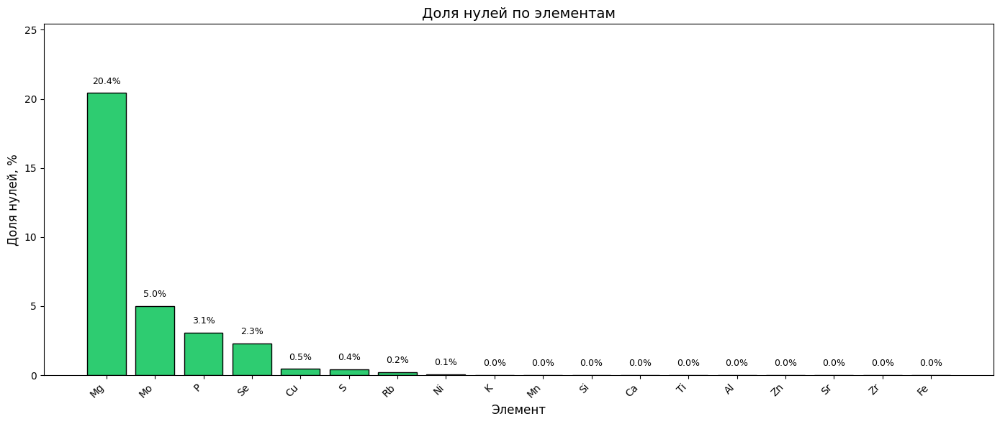

In [8]:
# График: доля нулей по элементам
fig, ax = plt.subplots(figsize=(14, 6))

# Цвета по группам 
def get_color(pct):
    if pct < 30:
        return '#2ecc71'  
    else:
        return '#e74c3c'  

colors = [get_color(p) for p in zero_table['Доля нулей, %']]

bars = ax.bar(zero_table['Элемент'], zero_table['Доля нулей, %'], color=colors, edgecolor='black')

# Подписи значений над столбцами
for bar, pct in zip(bars, zero_table['Доля нулей, %']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{pct:.1f}%', ha='center', va='bottom', fontsize=9)

# Пороговые линии
ax.axhline(y=30, color='red', linestyle='--', alpha=0.5)

ax.set_xlabel('Элемент', fontsize=12)
ax.set_ylabel('Доля нулей, %', fontsize=12)
ax.set_title('Доля нулей по элементам', fontsize=14)

ax.set_ylim(0, max(zero_table['Доля нулей, %']) + 5)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Проверка распределения**

Mg: Shapiro p (сырые) = 0.0000, p (log) = 0.0000
Al: Shapiro p (сырые) = 0.0000, p (log) = 0.0000
Si: Shapiro p (сырые) = 0.0000, p (log) = 0.0000
P: Shapiro p (сырые) = 0.0000, p (log) = 0.0000
S: Shapiro p (сырые) = 0.0000, p (log) = 0.0000
K: Shapiro p (сырые) = 0.0000, p (log) = 0.0000
Ca: Shapiro p (сырые) = 0.0000, p (log) = 0.0000
Ti: Shapiro p (сырые) = 0.0000, p (log) = 0.0000
Mn: Shapiro p (сырые) = 0.0000, p (log) = 0.0000
Fe: Shapiro p (сырые) = 0.0000, p (log) = 0.0000
Ni: Shapiro p (сырые) = 0.0000, p (log) = 0.0000
Cu: Shapiro p (сырые) = 0.0000, p (log) = 0.0000
Zn: Shapiro p (сырые) = 0.0000, p (log) = 0.0000
Se: Shapiro p (сырые) = 0.0000, p (log) = 0.0000
Rb: Shapiro p (сырые) = 0.0000, p (log) = 0.0000
Sr: Shapiro p (сырые) = 0.0000, p (log) = 0.0000
Zr: Shapiro p (сырые) = 0.0000, p (log) = 0.0000
Mo: Shapiro p (сырые) = 0.0000, p (log) = 0.0000


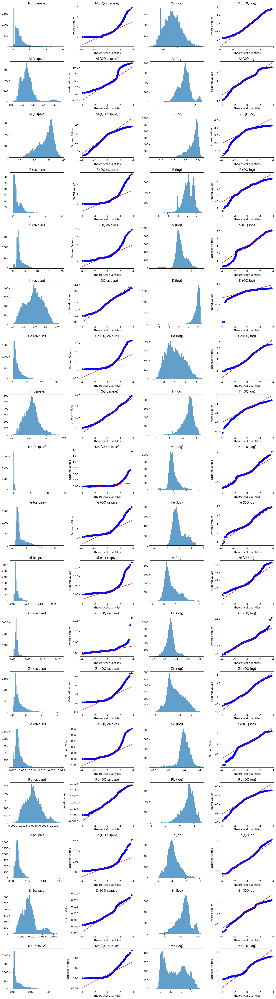

Элемент  N (ненулевых)  Skew (сырые)  Skew (log)  Kurt (сырые)  Kurt (log) Skew(log) < 0.5?
     Mn           8642          8.65        0.58        155.66        2.41              нет
     Cu           8603          4.91        0.32         79.16        1.70               да
     Ni           8639          4.00        1.08         24.00        1.06              нет
     Se           8445          3.01       -0.90         14.32        3.00              нет
     Sr           8643          2.71        0.54         11.01        0.91              нет
      P           8376          2.57       -0.74         10.34        1.30              нет
      S           8605          2.57       -0.53         10.10        2.81              нет
     Ca           8643          2.54        0.31          8.87       -0.55               да
     Mg           6878          2.42        0.30          8.98       -0.25               да
     Fe           8643          2.15        0.85          5.58        0.21      

In [10]:
fig, axes = plt.subplots(len(elements), 4, figsize=(15, 3*len(elements)))
results = []
for i, col in enumerate(elements):
    x_raw = df[col].dropna()
    x_nonzero = x_raw[x_raw > 0]
    x_log = np.log(x_nonzero)

    results.append({
        'Элемент': col,
        'N (ненулевых)': len(x_nonzero),
        'Skew (сырые)': round(skew(x_nonzero), 2),
        'Skew (log)': round(skew(x_log), 2),
        'Kurt (сырые)': round(kurtosis(x_nonzero), 2),
        'Kurt (log)': round(kurtosis(x_log), 2),
        'Skew(log) < 0.5?': 'да' if abs(skew(x_log)) < 0.5 else 'нет',
    })
    
    # Гистограмма сырых
    axes[i, 0].hist(x_raw, bins=50, alpha=0.7)
    axes[i, 0].set_title(f'{col} (сырые)')
    
    # QQ-plot сырых
    stats.probplot(x_raw, dist="norm", plot=axes[i, 1])
    axes[i, 1].set_title(f'{col} (QQ сырые)')

    # Гистограмма логарифмированных значений
    axes[i, 2].hist(x_log, bins=50, alpha=0.7)
    axes[i, 2].set_title(f'{col} (log)')
    
    # QQ-plot логарифмов
    stats.probplot(x_log, dist="norm", plot=axes[i, 3])
    axes[i, 3].set_title(f'{col} (QQ log)')
    
    # Тесты
    sw_raw = shapiro(x_raw.sample(min(5000, len(x_raw))))[1]
    sw_log = shapiro(x_log.sample(min(5000, len(x_log))))[1]
    print(f"{col}: Shapiro p (сырые) = {sw_raw:.4f}, p (log) = {sw_log:.4f}")

plt.tight_layout()

plt.savefig('plot_element_kern_05_10.png', dpi=600, bbox_inches='tight')
plt.show()

results_df = pd.DataFrame(results).sort_values('Skew (сырые)', ascending=False)
print(results_df.to_string(index=False))

**Нахождение артефактов LOD и их зануление**

ЭЛЕМЕНТ: Mg
Всего скважин: 21
Скважин с минимумом > 0: 1


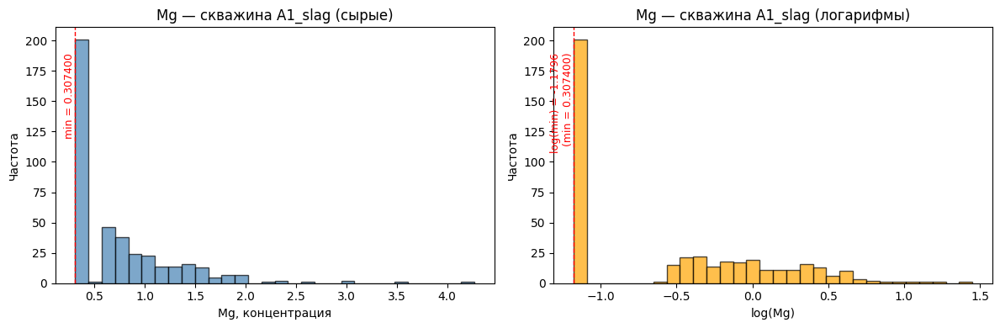

ЭЛЕМЕНТ: Al
Всего скважин: 21
Скважин с минимумом > 0: 21


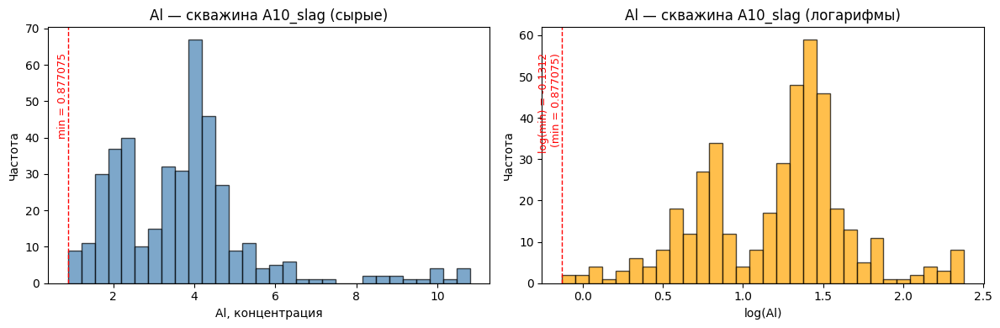

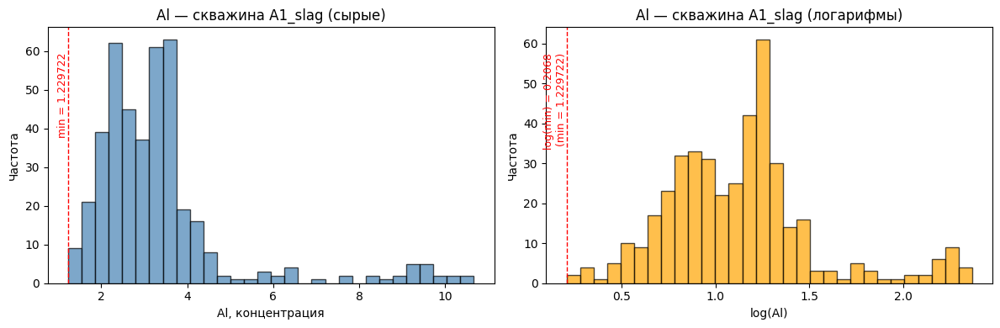

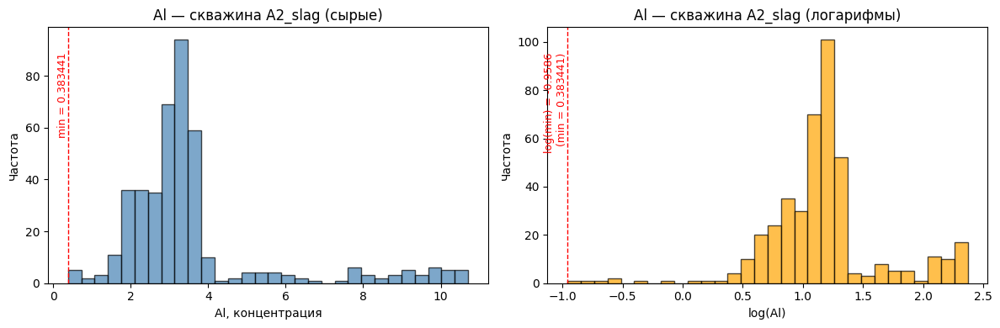

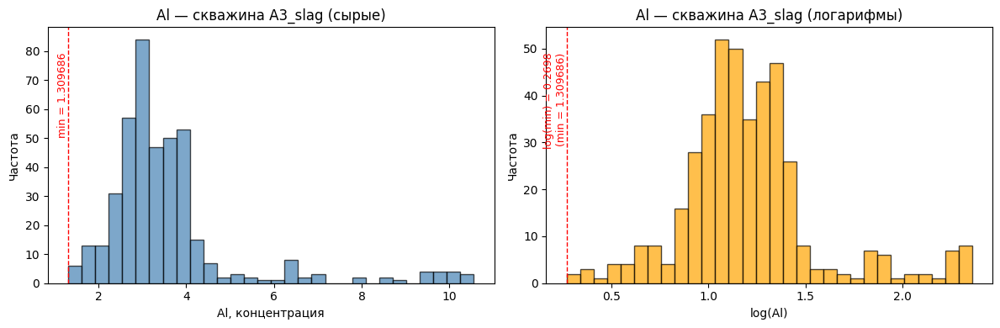

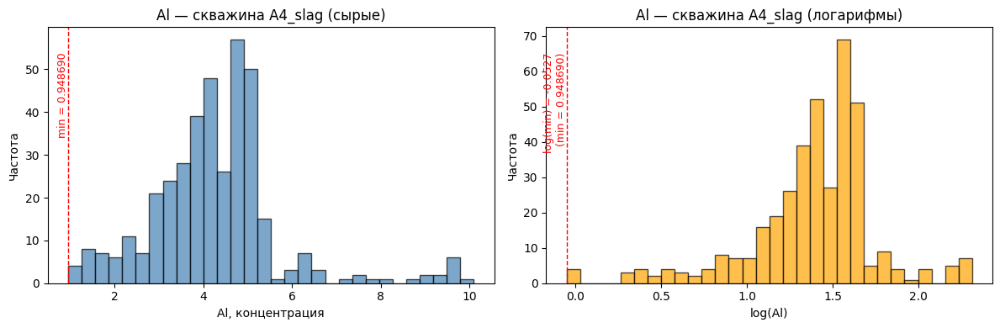

...

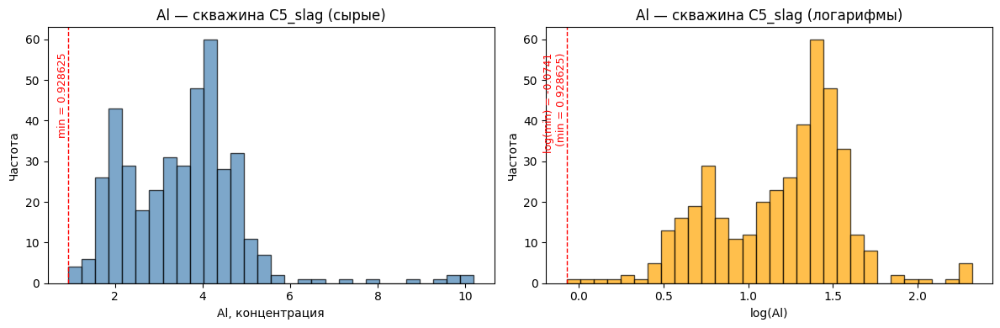

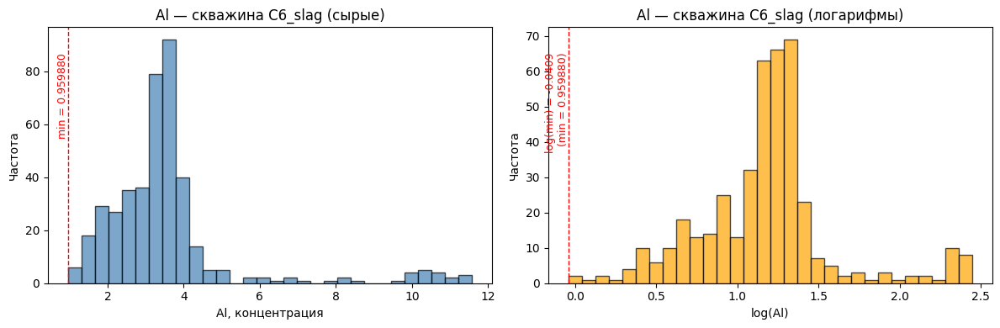

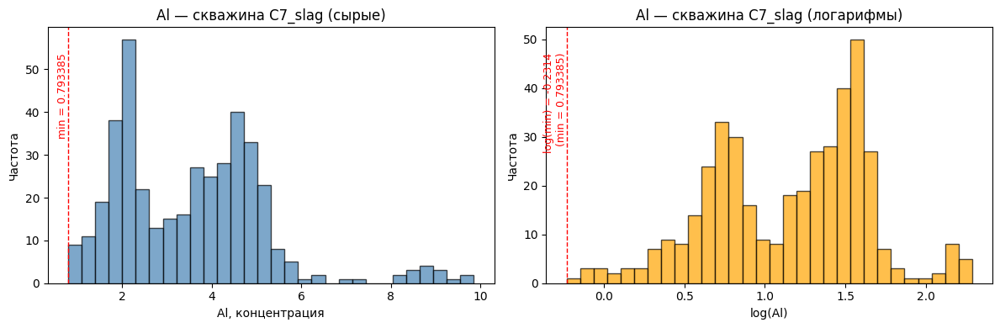

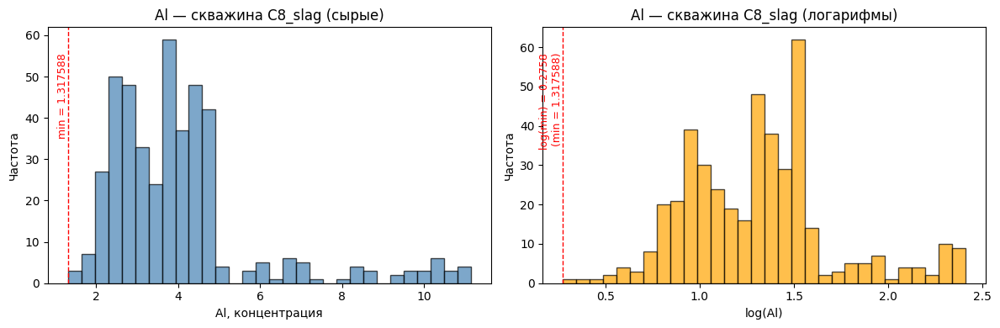

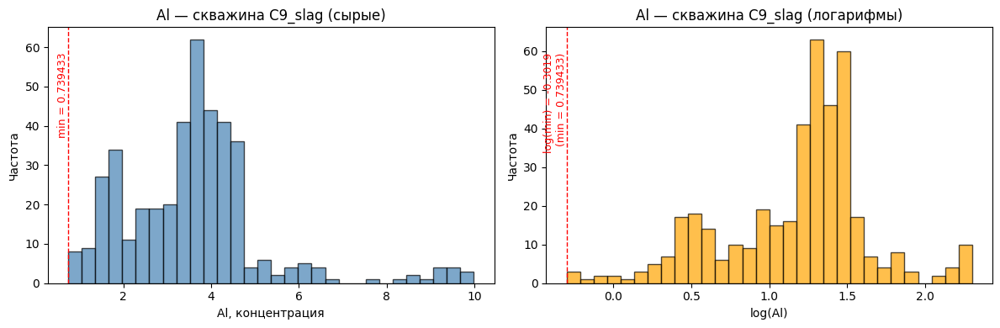

ЭЛЕМЕНТ: Si
Всего скважин: 21
Скважин с минимумом > 0: 21


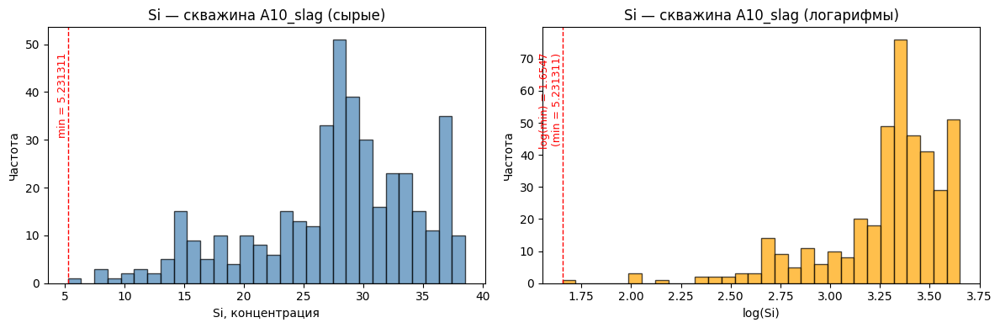

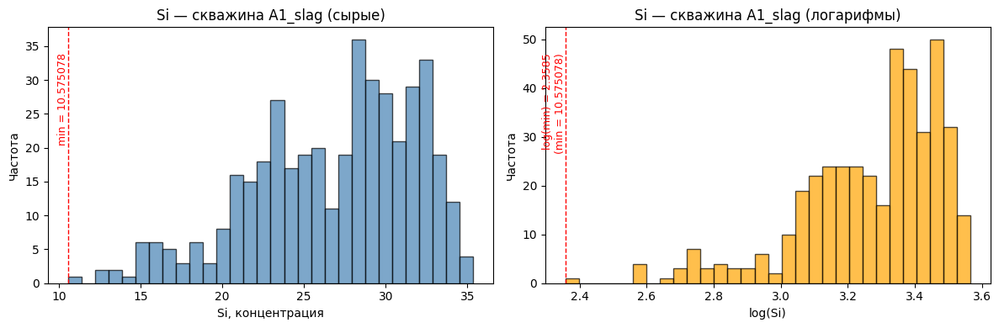

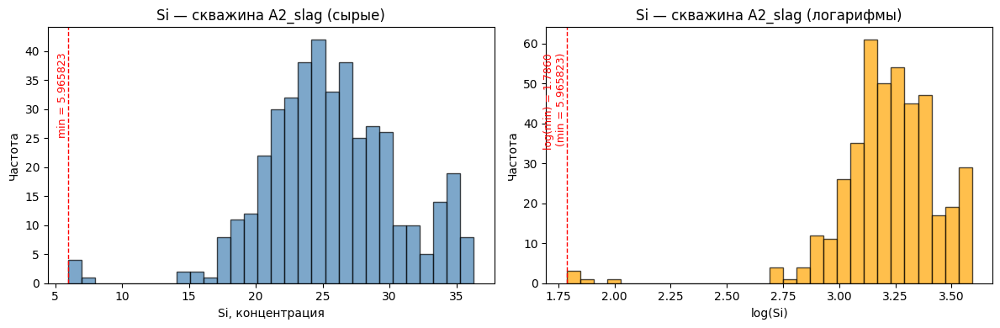

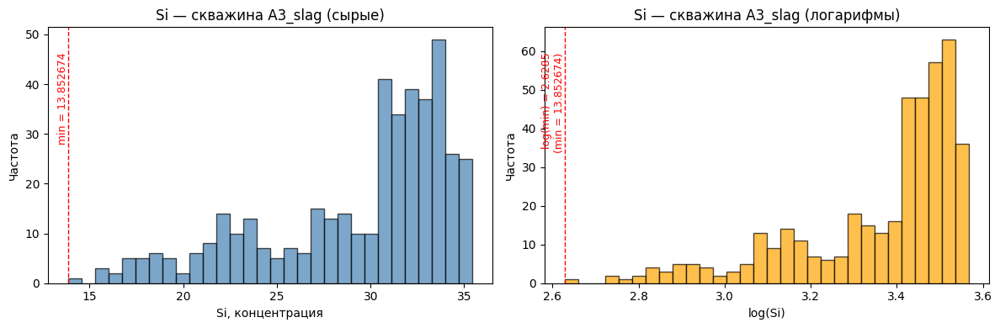

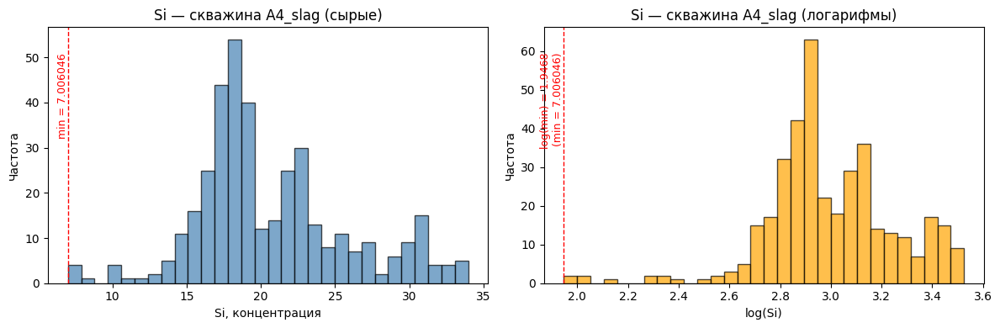

...

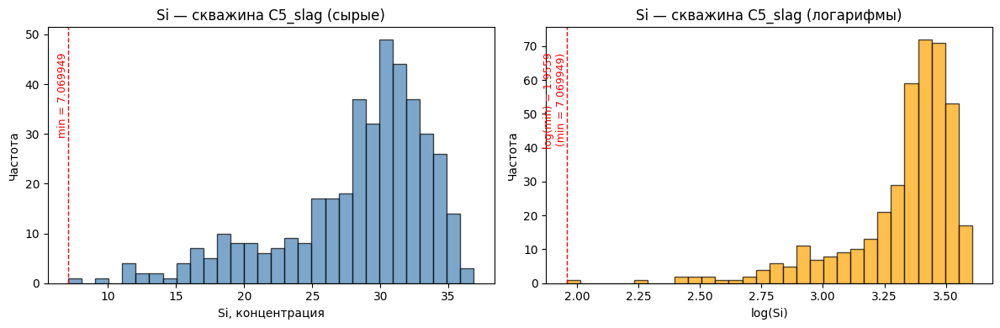

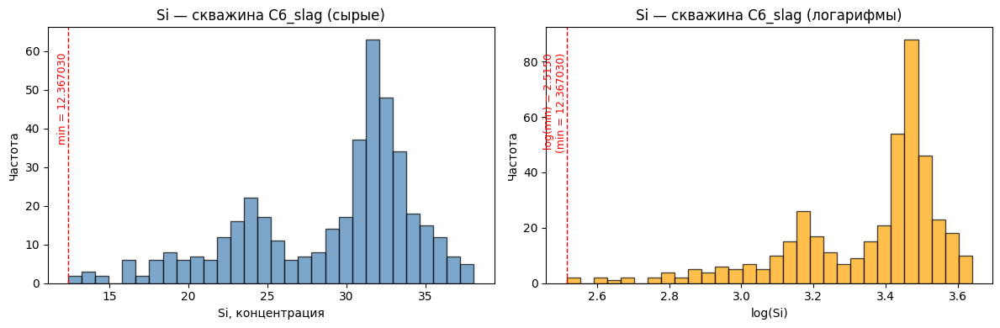

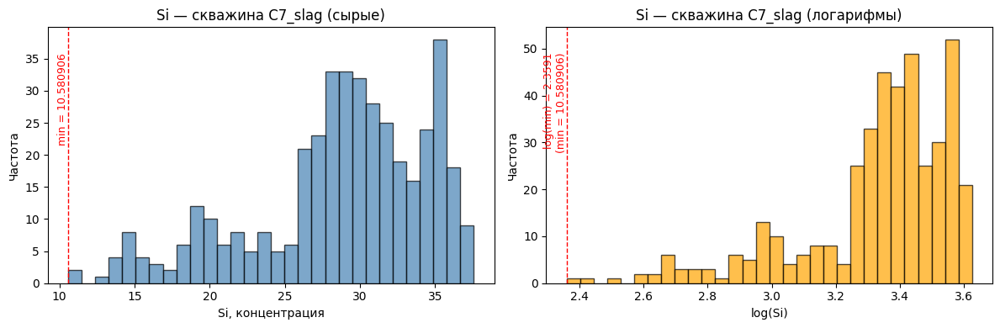

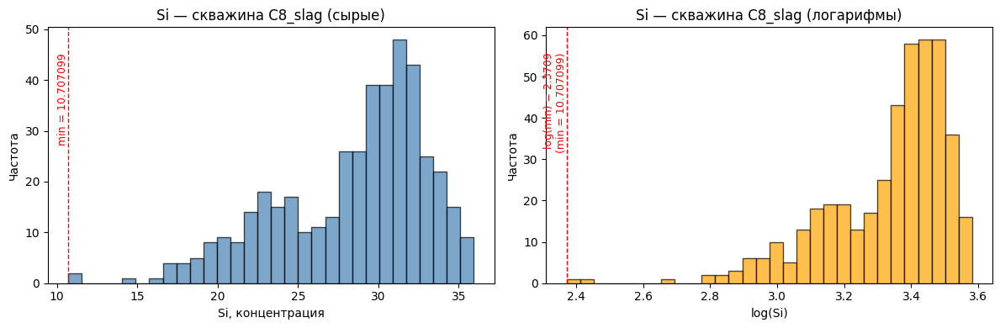

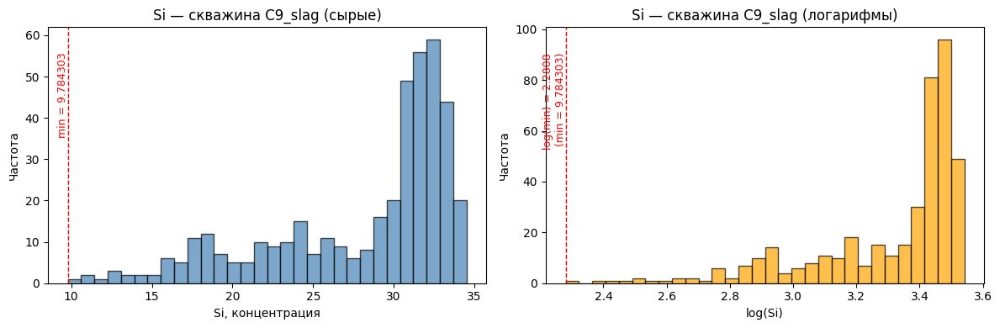

ЭЛЕМЕНТ: P
Всего скважин: 21
Скважин с минимумом > 0: 12


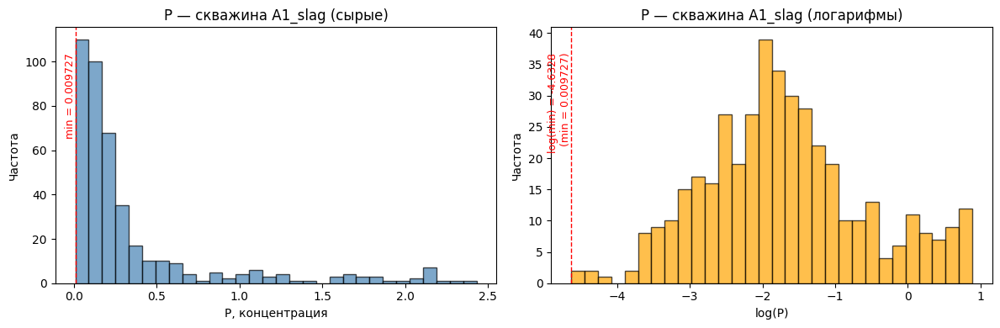

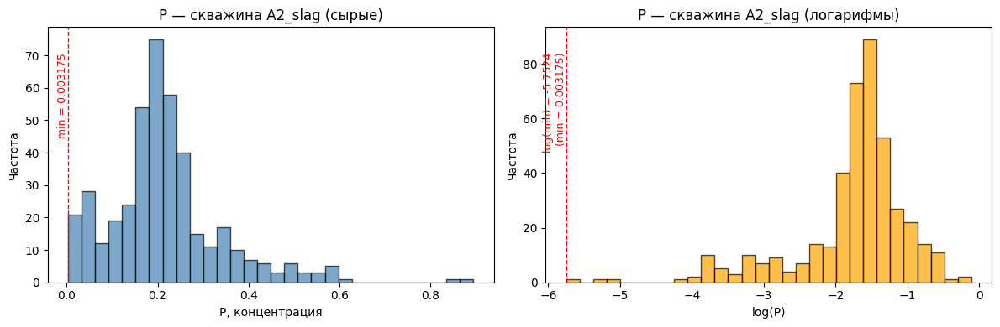

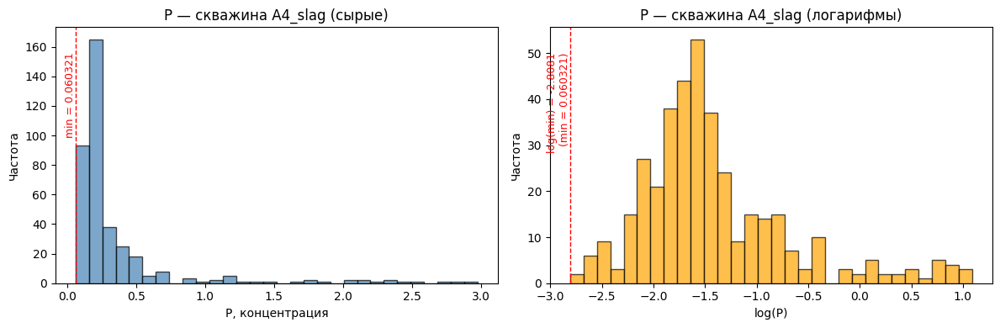

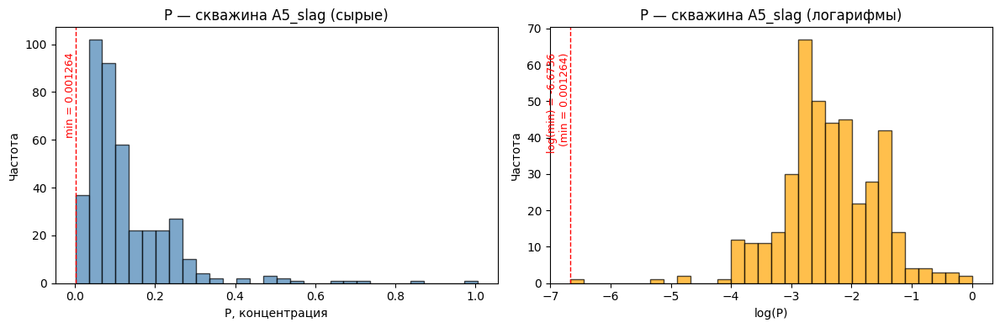

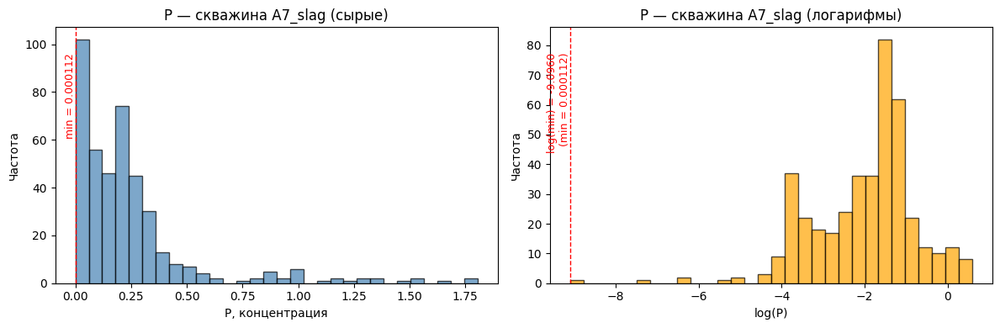

...

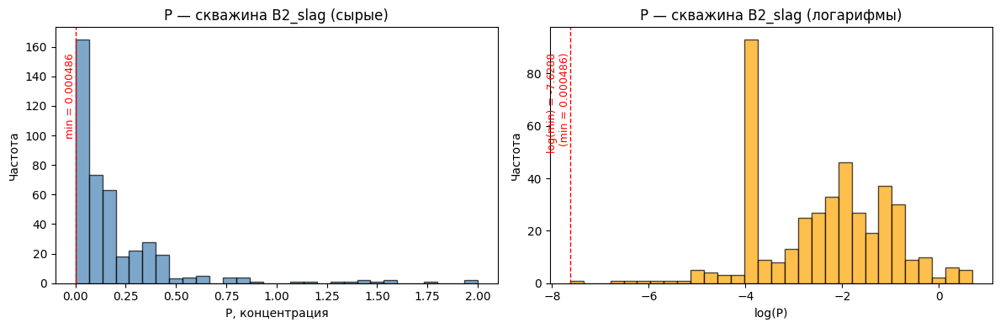

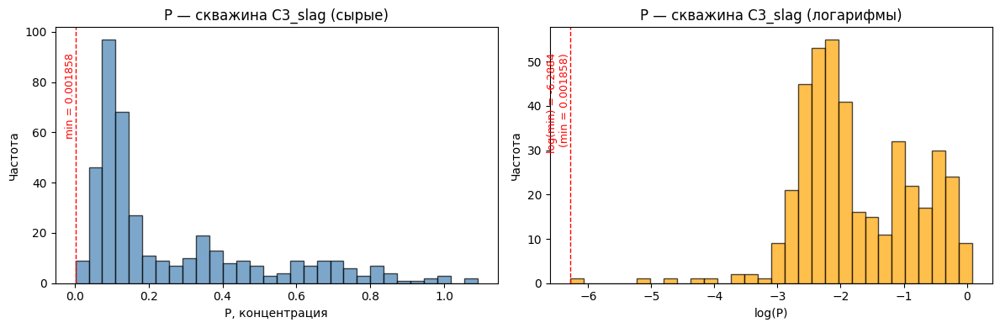

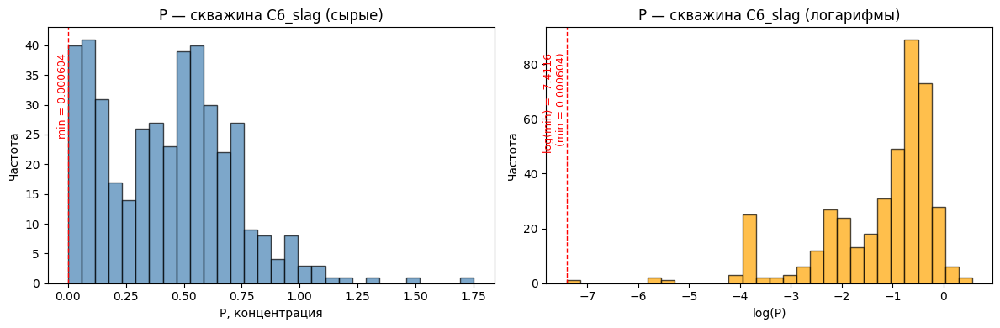

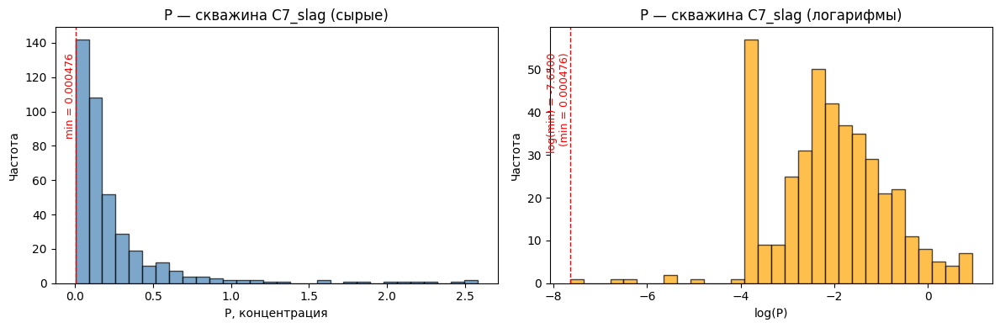

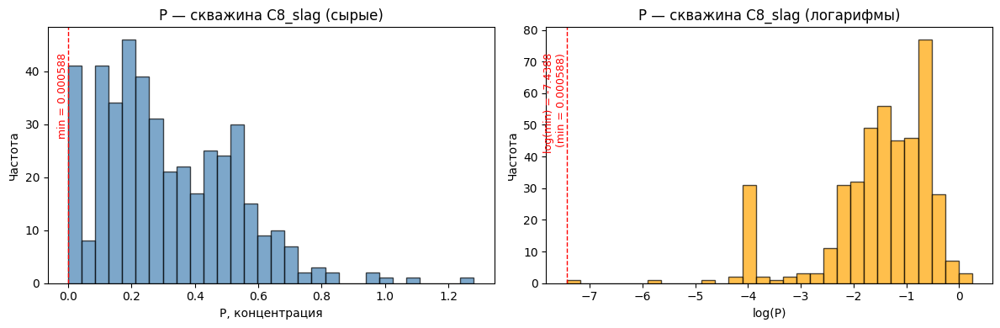

ЭЛЕМЕНТ: S
Всего скважин: 21
Скважин с минимумом > 0: 5


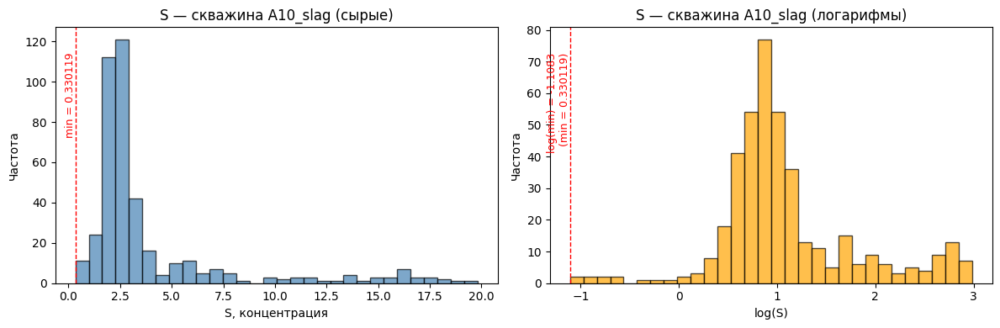

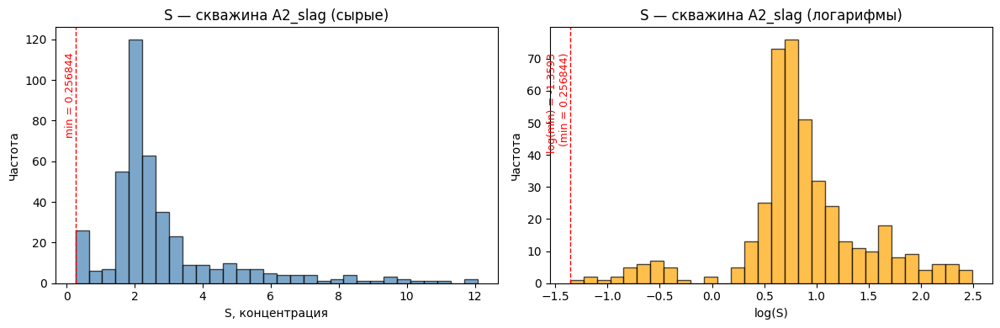

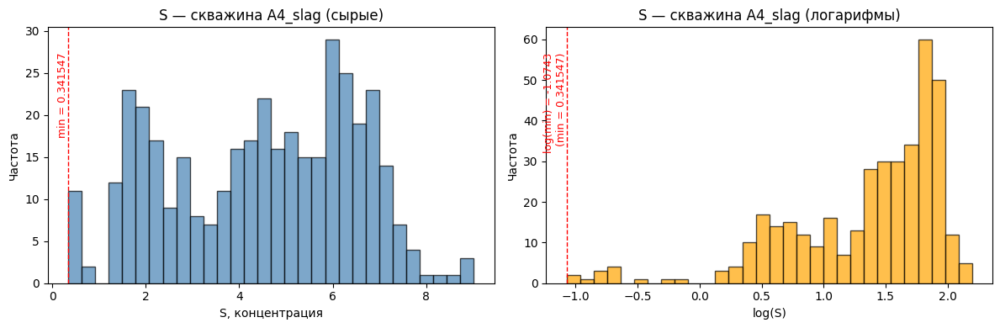

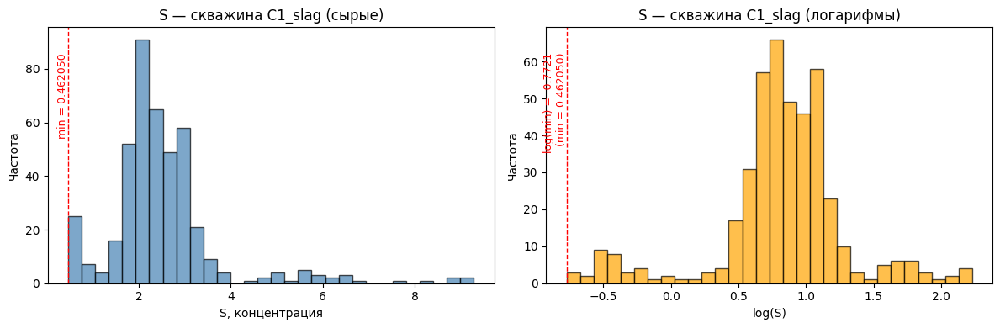

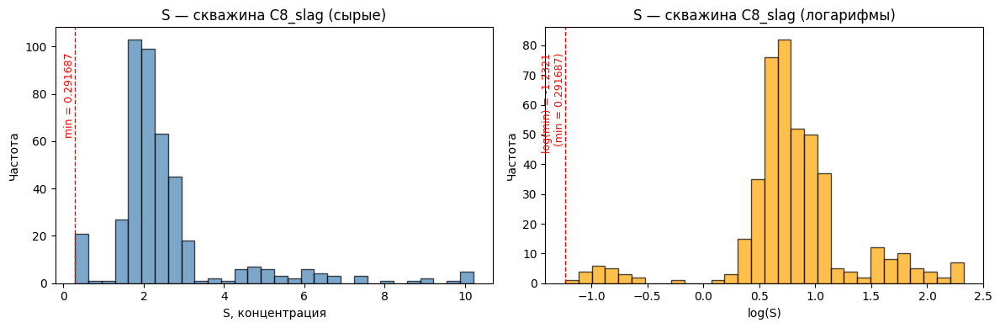

ЭЛЕМЕНТ: K
Всего скважин: 21
Скважин с минимумом > 0: 20


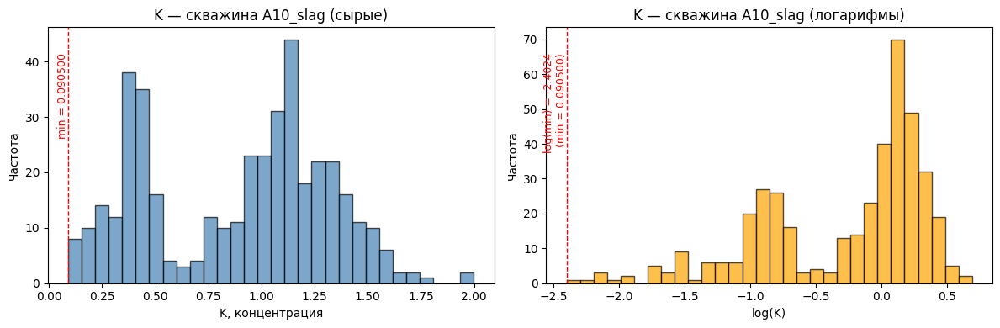

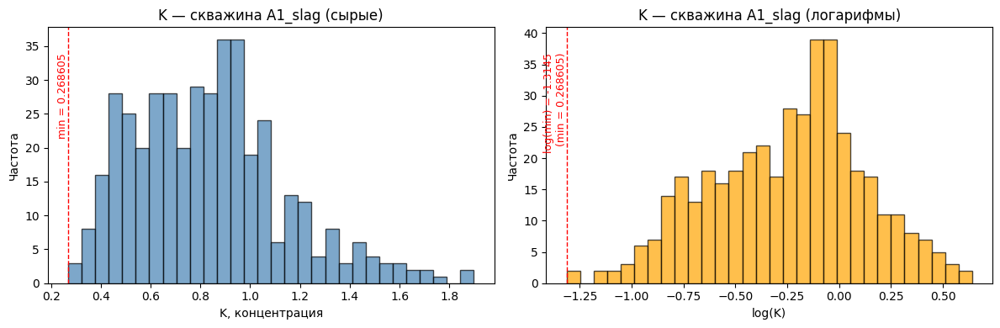

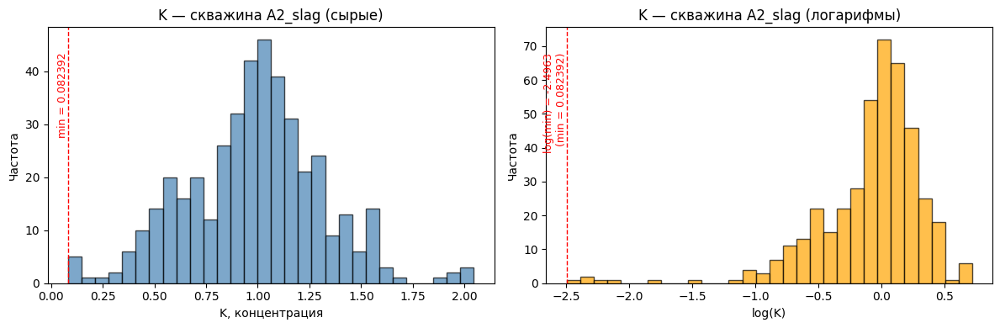

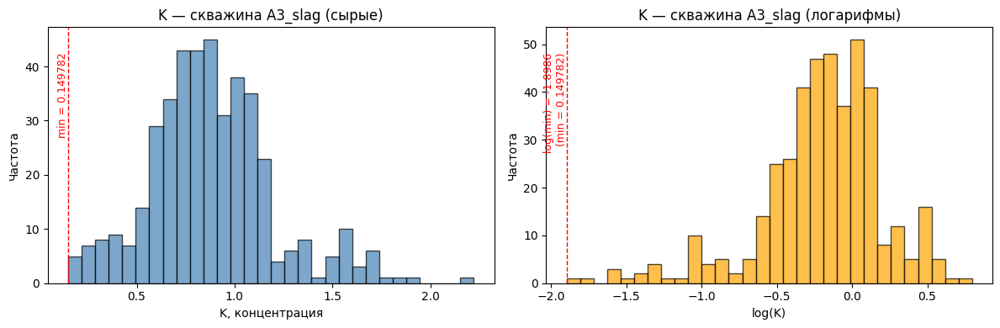

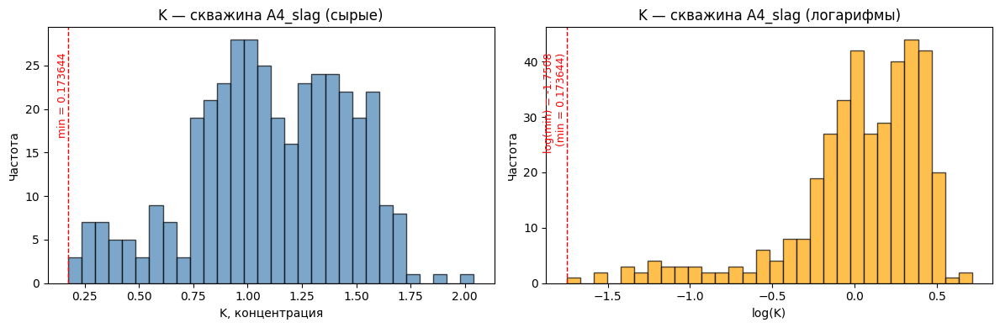

...

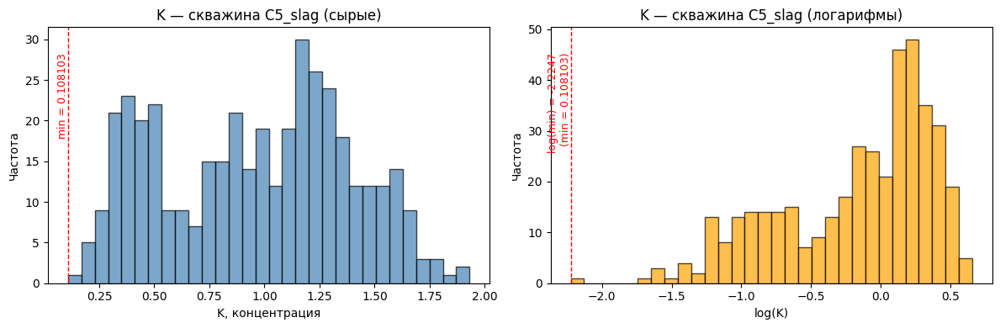

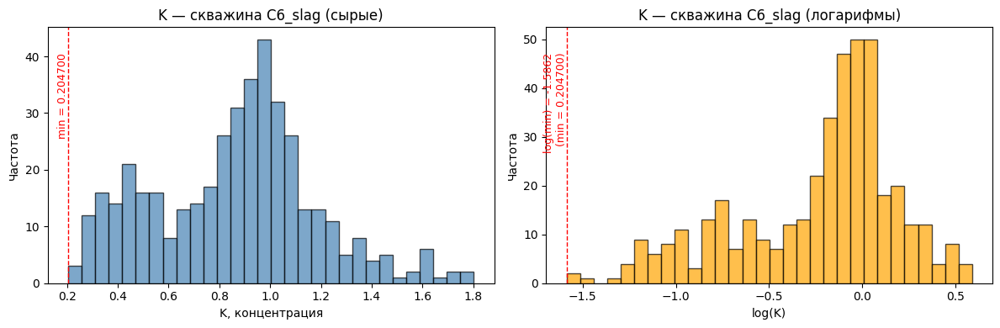

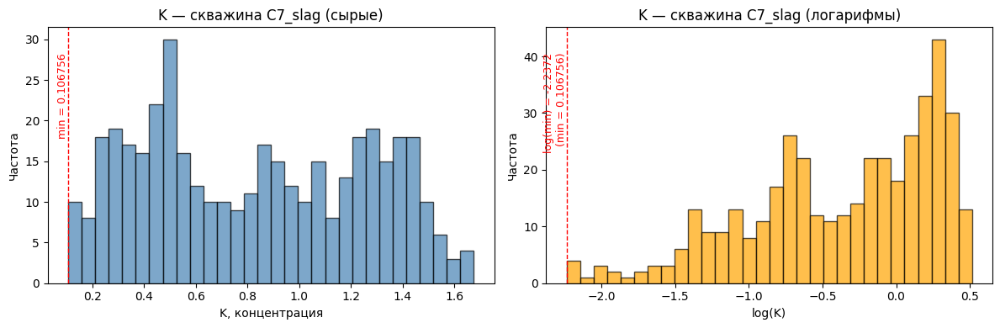

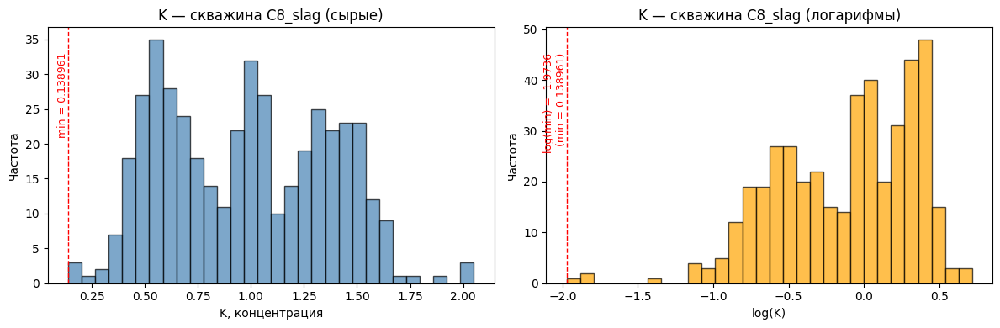

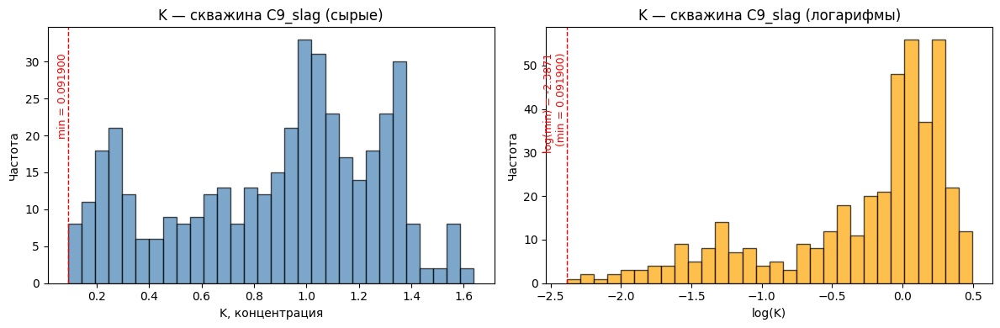

ЭЛЕМЕНТ: Ca
Всего скважин: 21
Скважин с минимумом > 0: 21


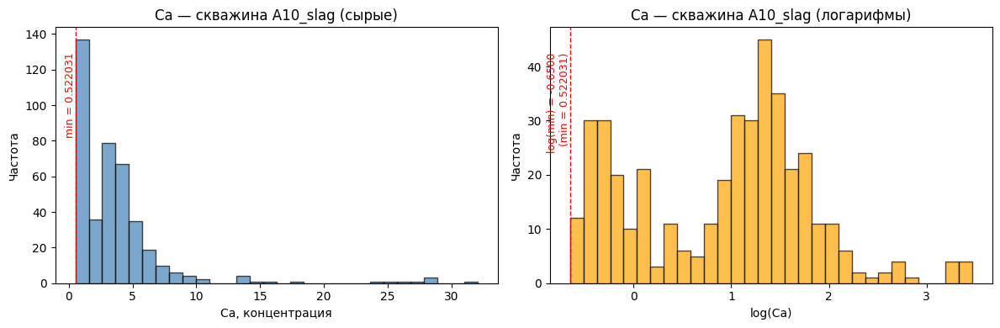

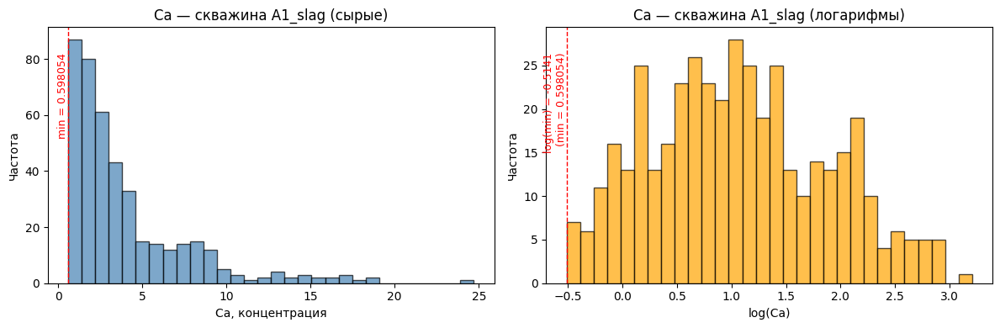

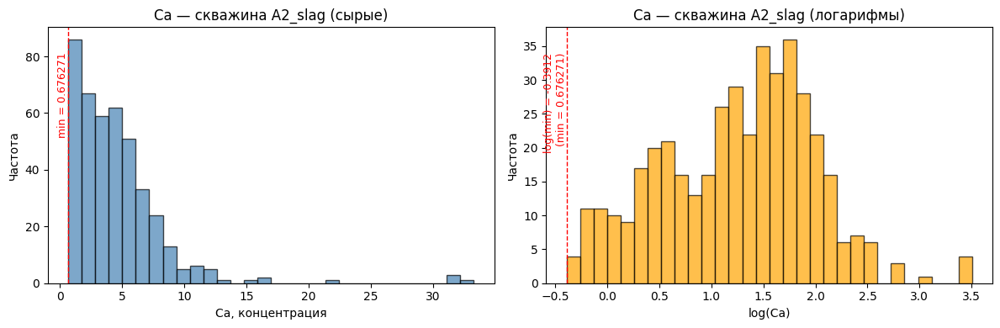

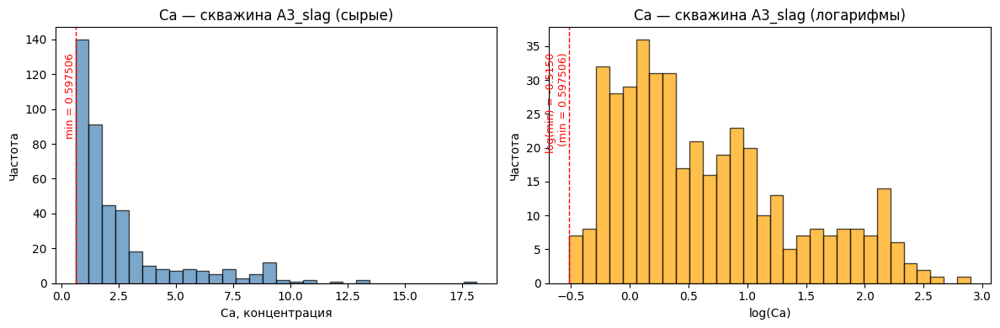

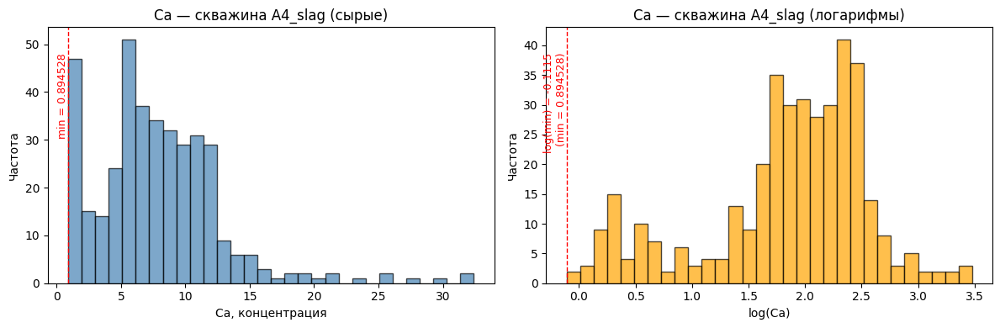

...

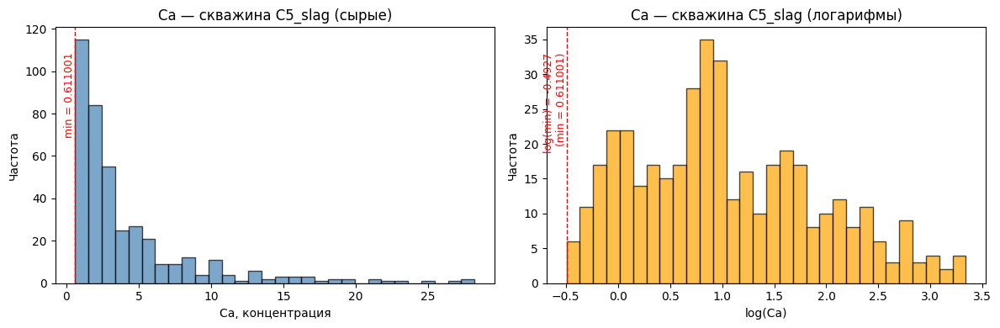

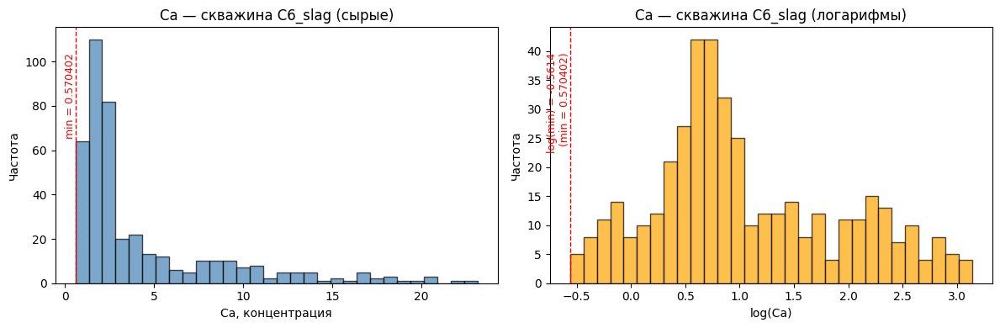

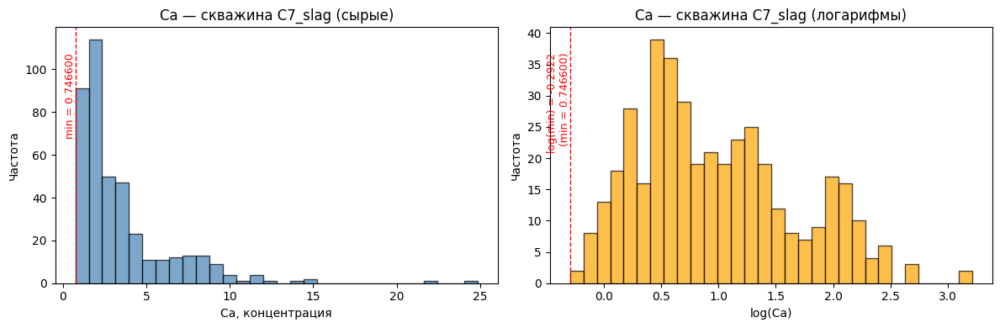

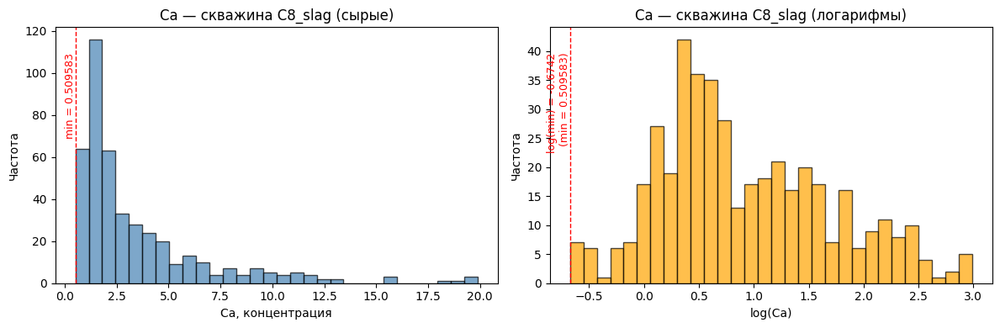

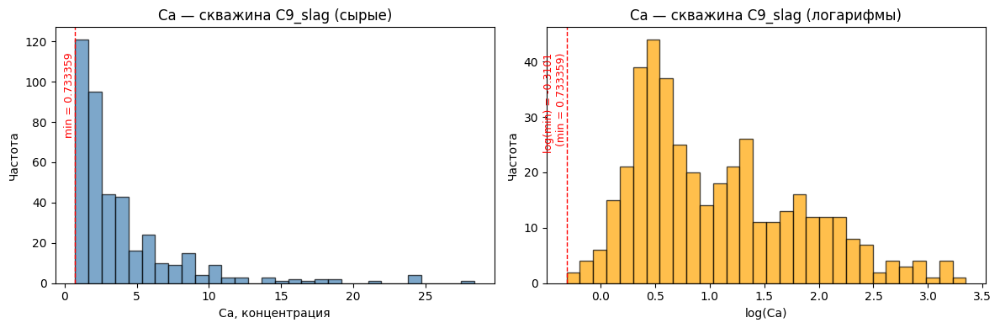

ЭЛЕМЕНТ: Ti
Всего скважин: 21
Скважин с минимумом > 0: 21


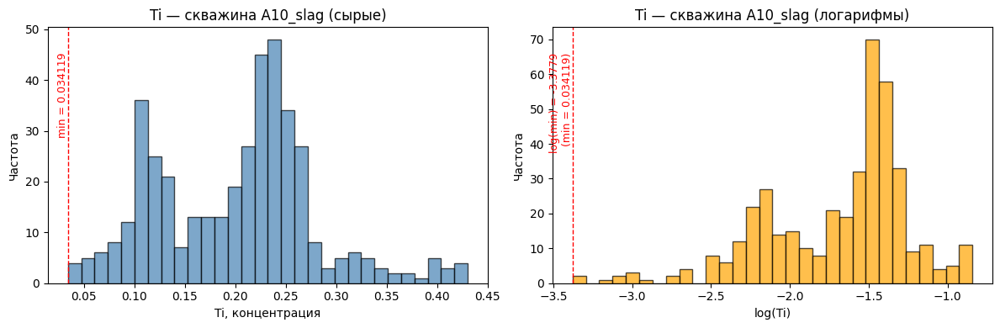

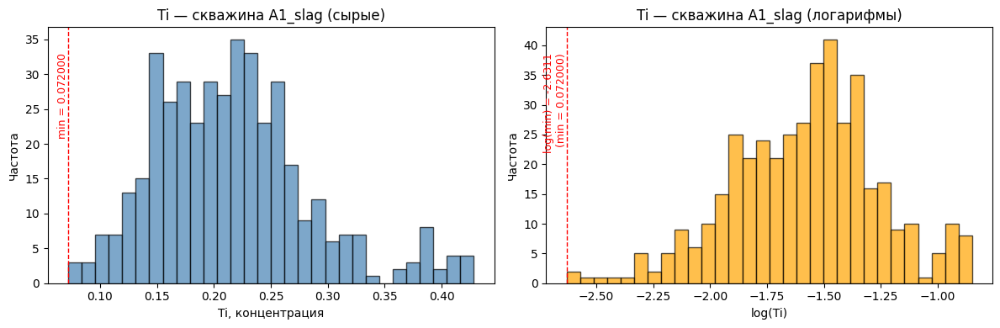

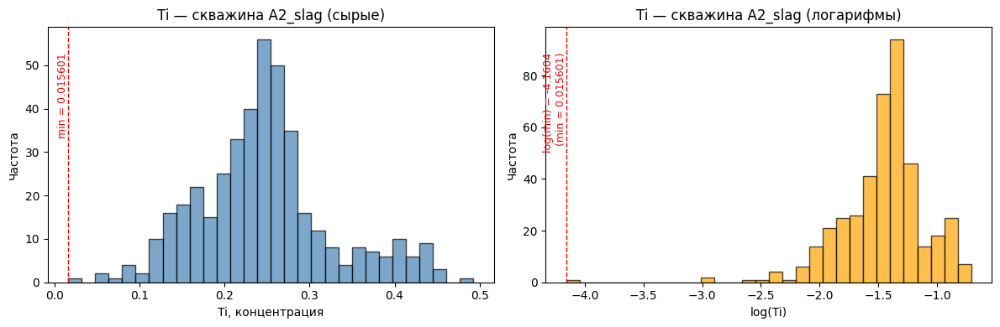

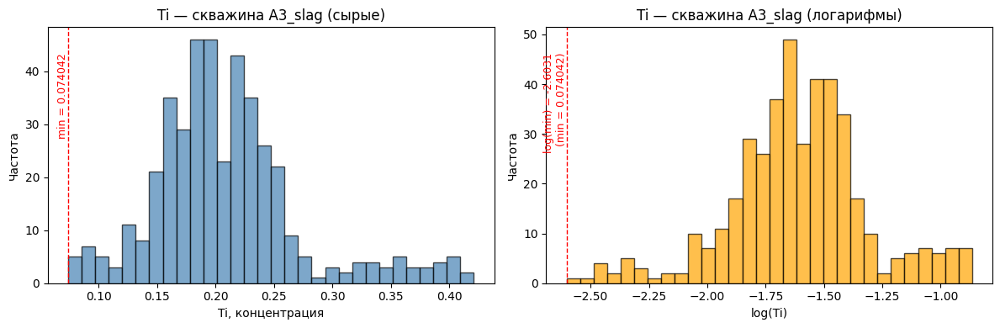

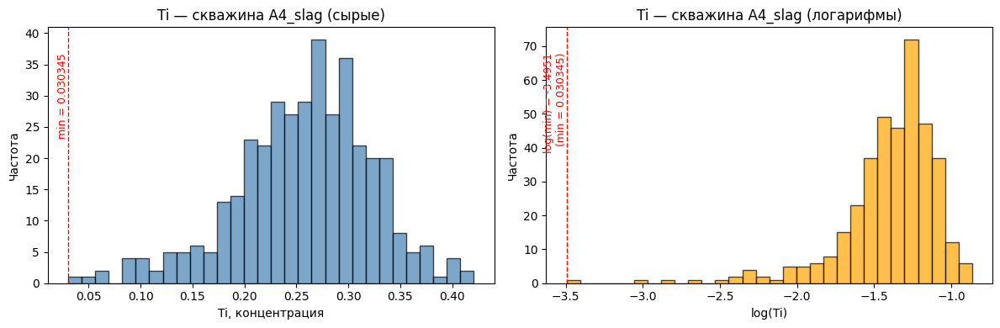

...

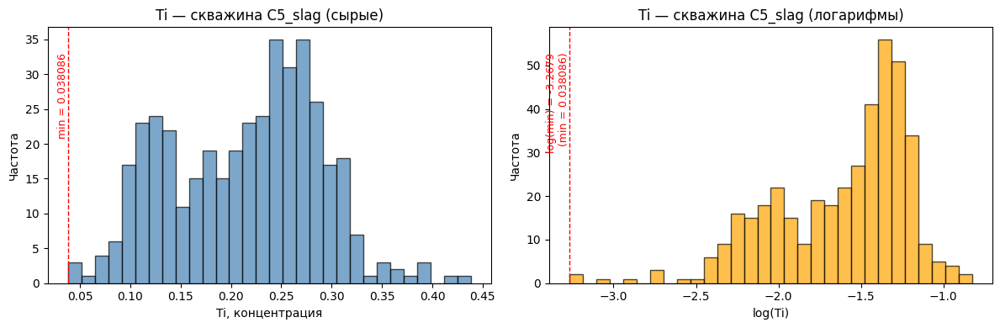

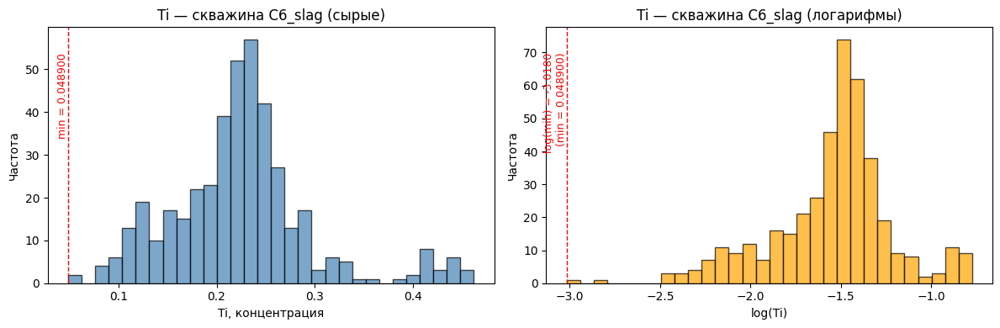

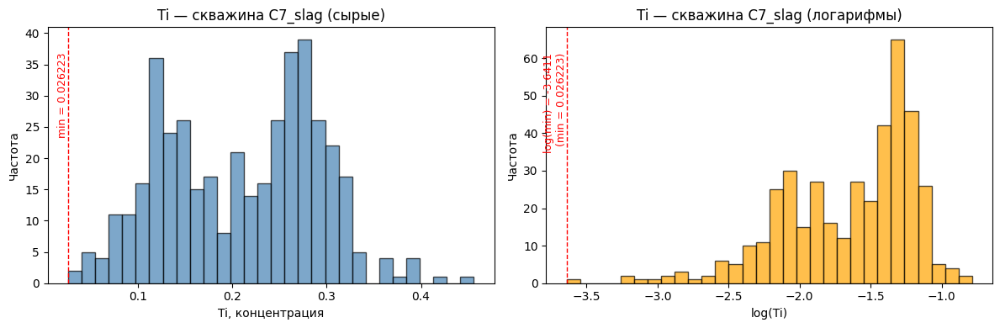

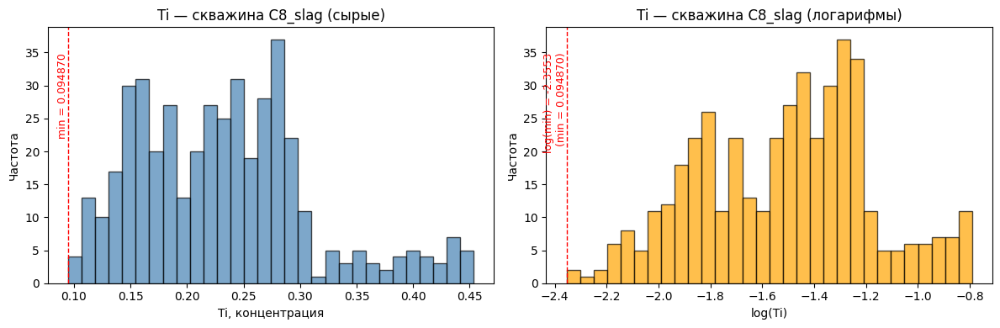

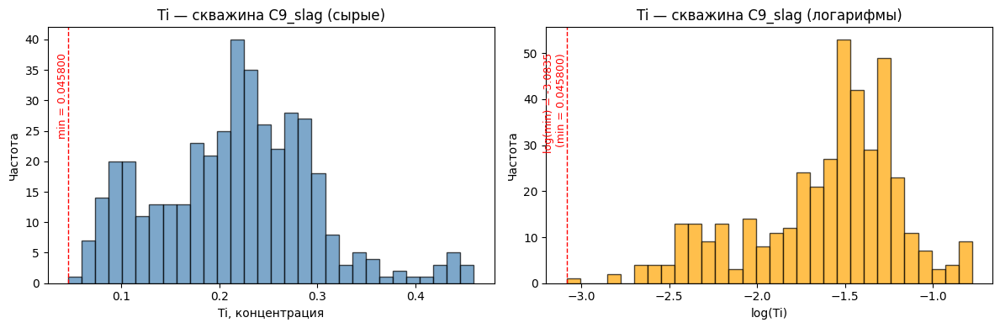

ЭЛЕМЕНТ: Mn
Всего скважин: 21
Скважин с минимумом > 0: 20


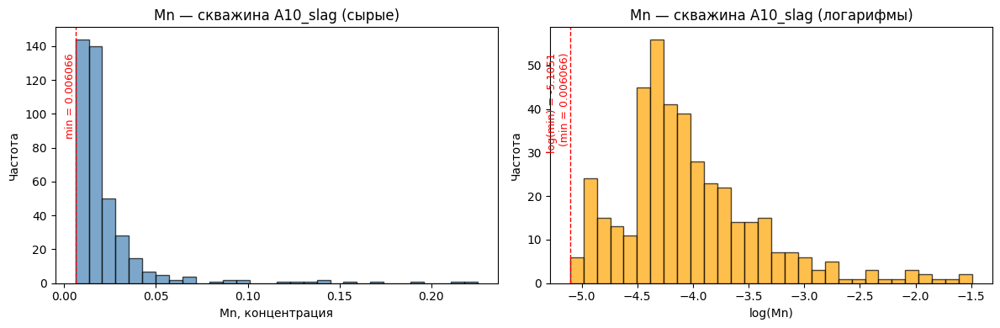

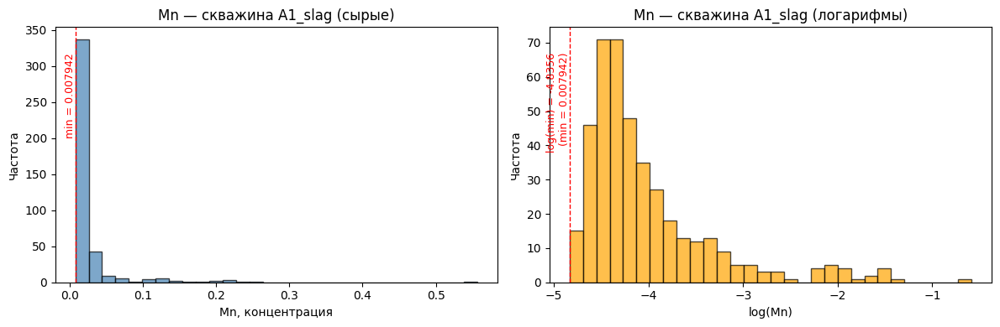

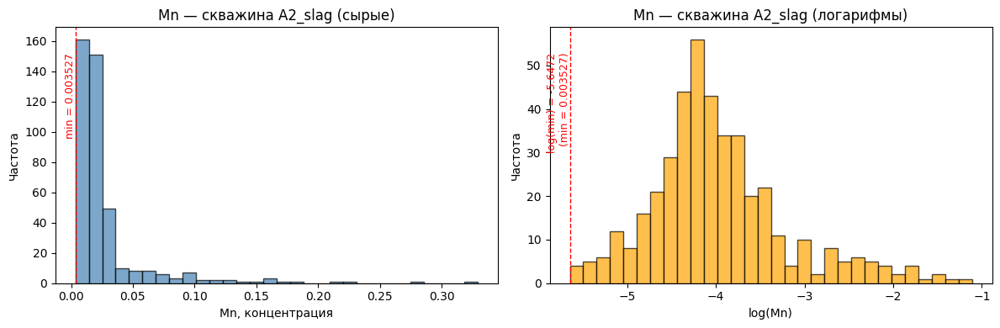

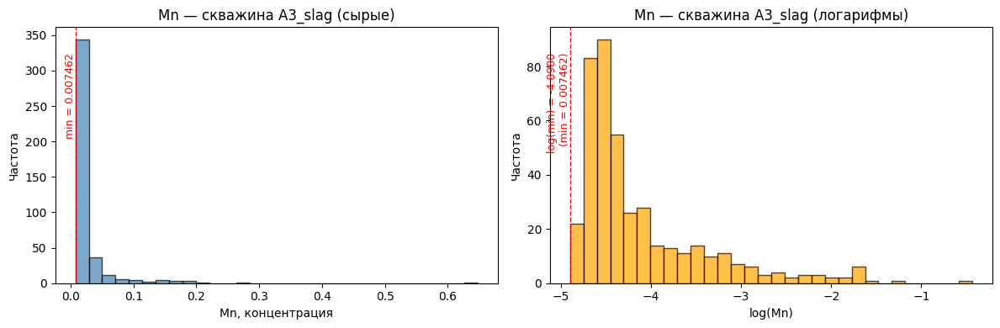

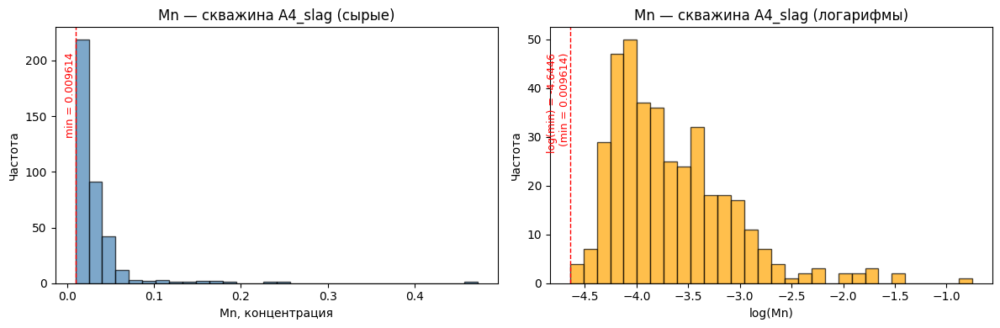

...

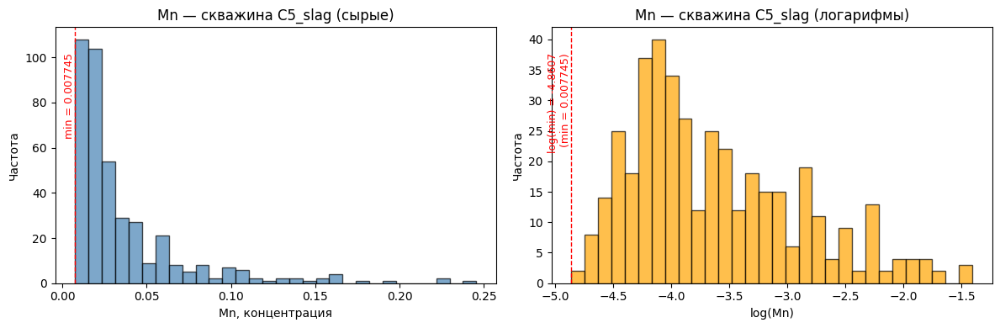

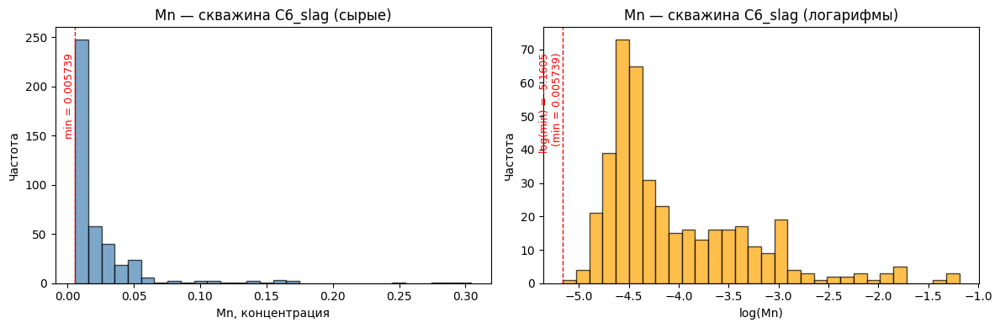

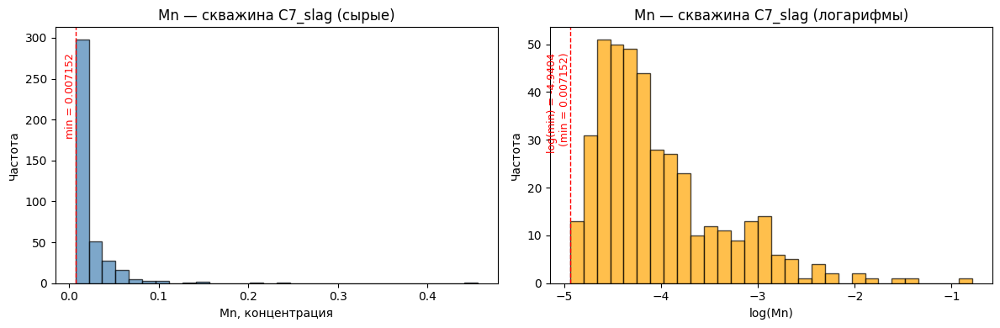

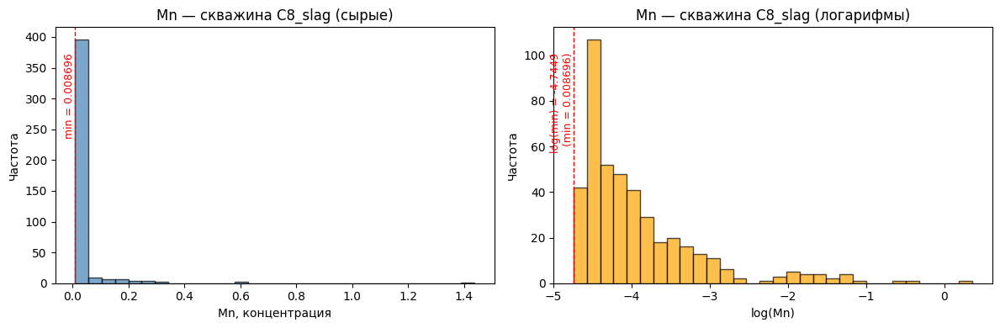

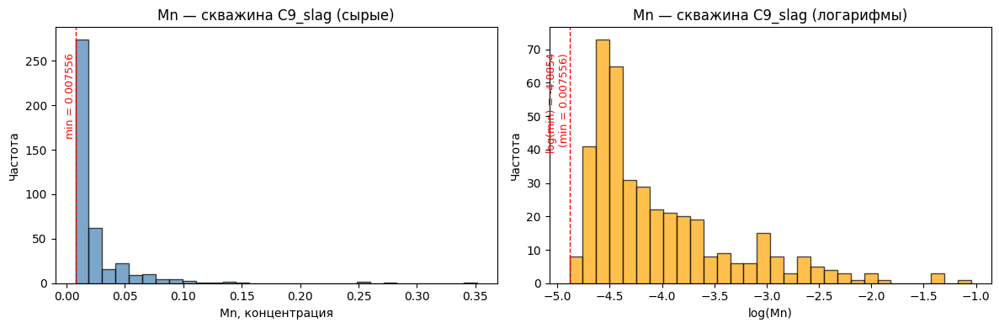

ЭЛЕМЕНТ: Fe
Всего скважин: 21
Скважин с минимумом > 0: 21


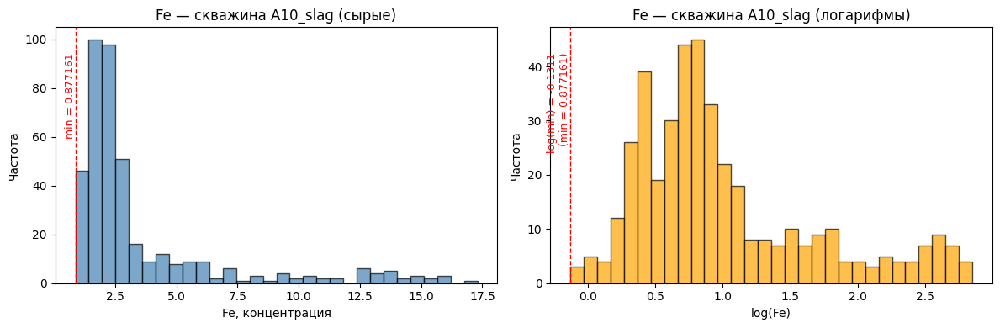

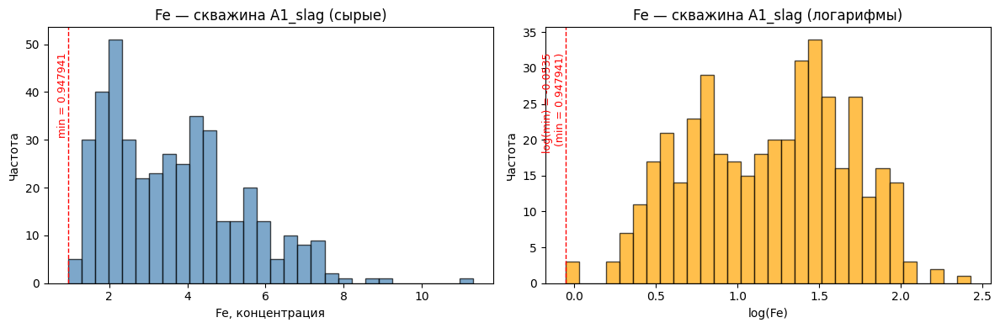

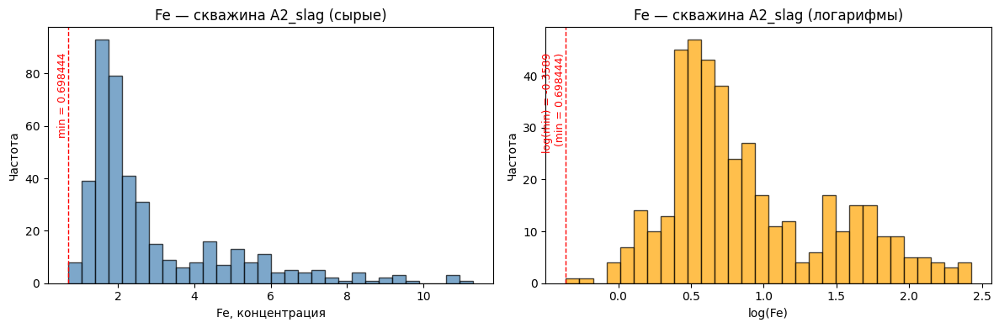

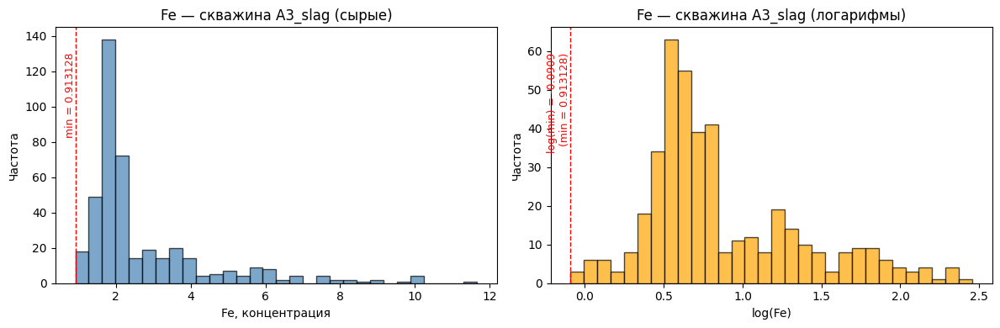

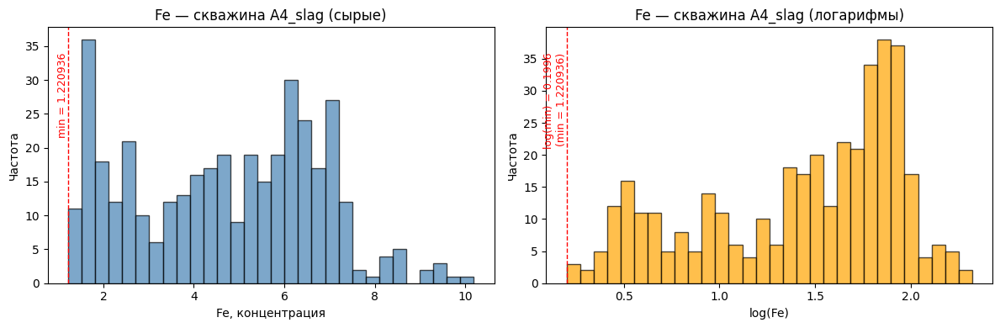

...

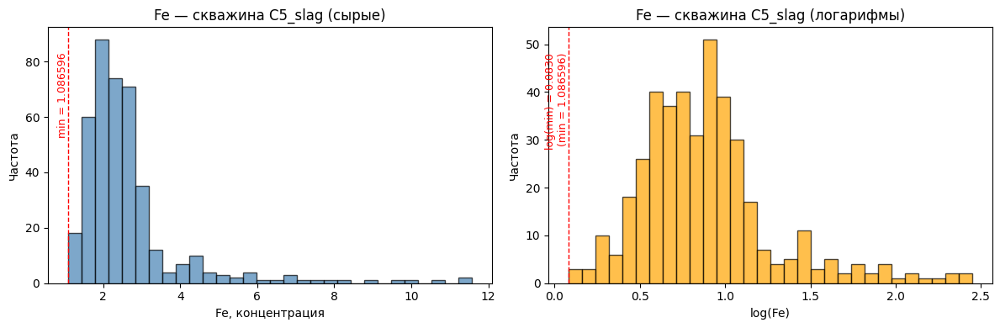

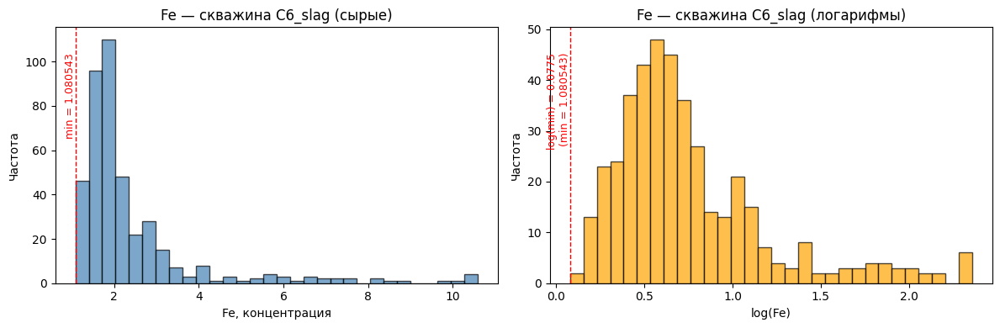

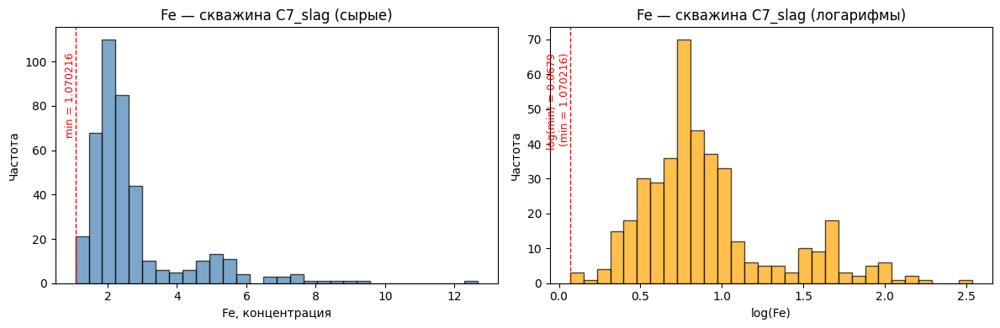

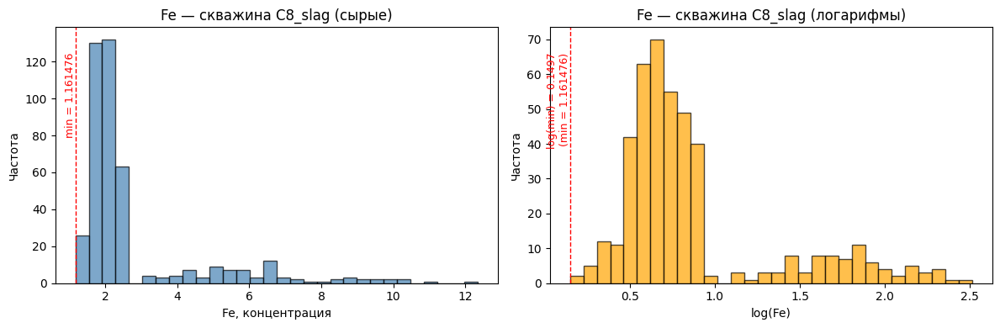

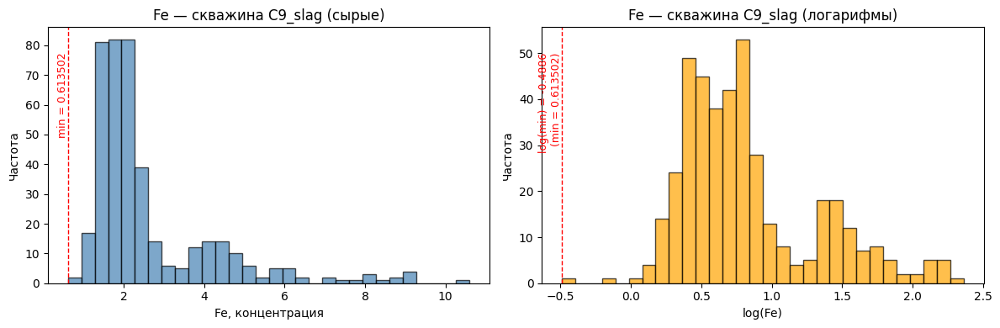

ЭЛЕМЕНТ: Ni
Всего скважин: 21
Скважин с минимумом > 0: 18


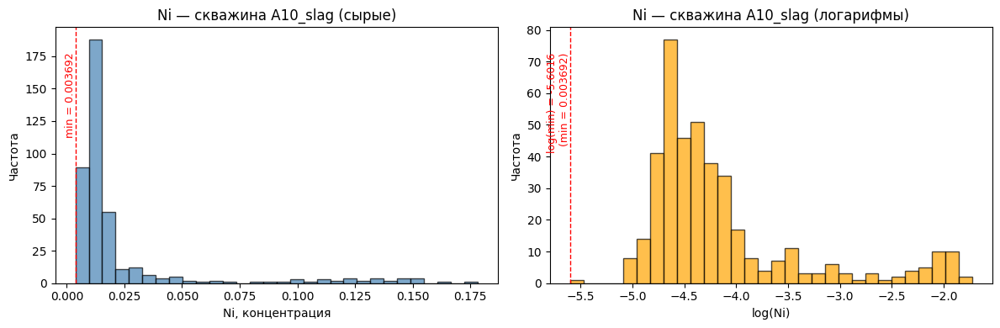

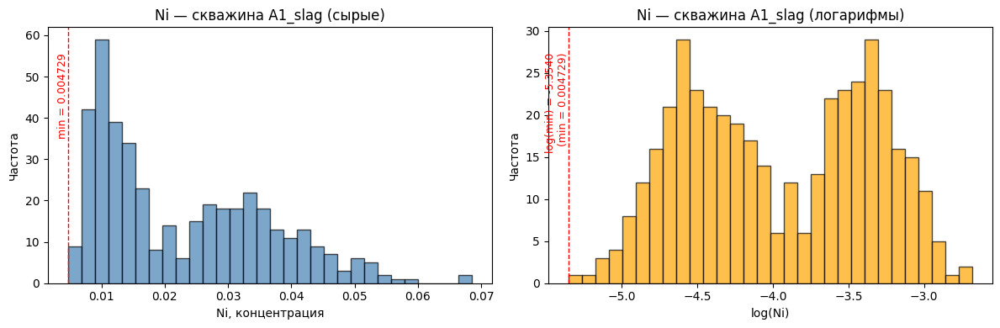

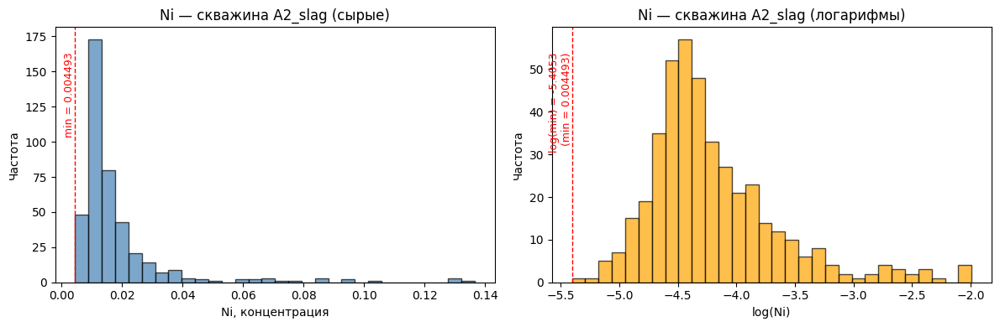

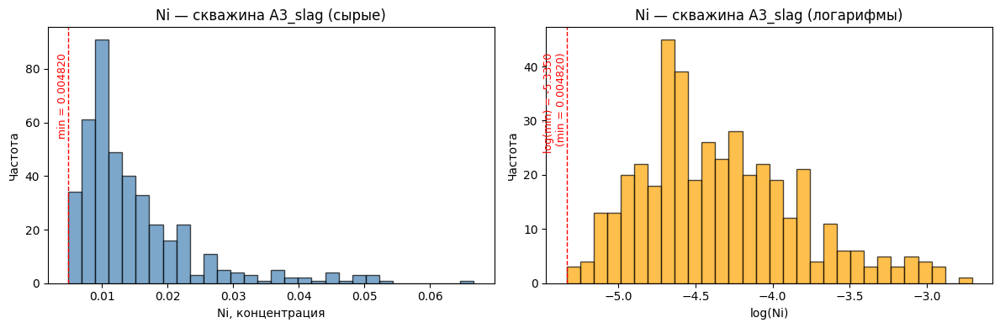

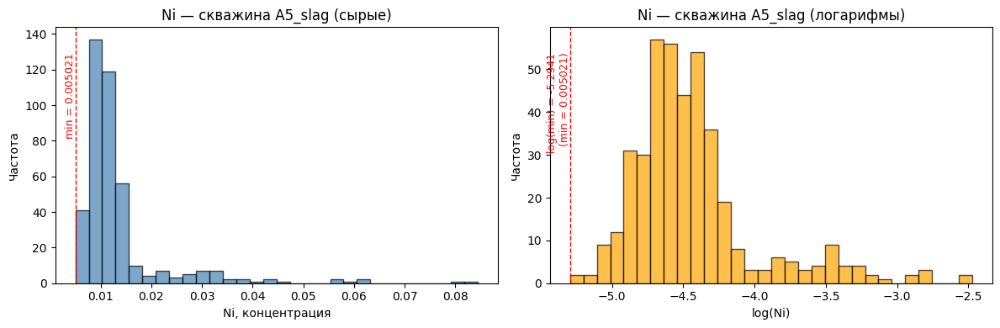

...

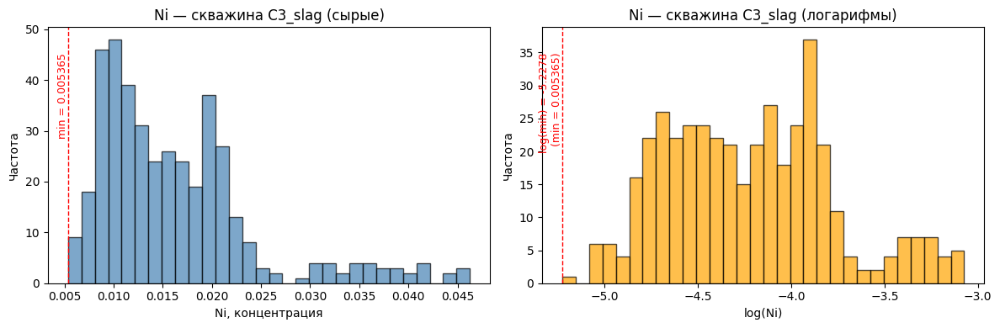

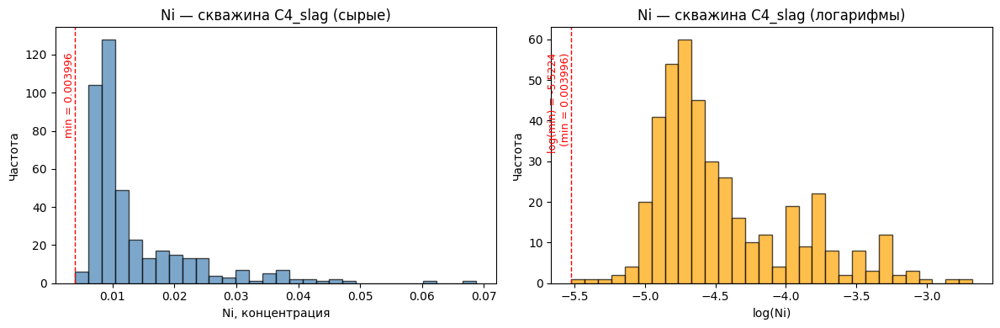

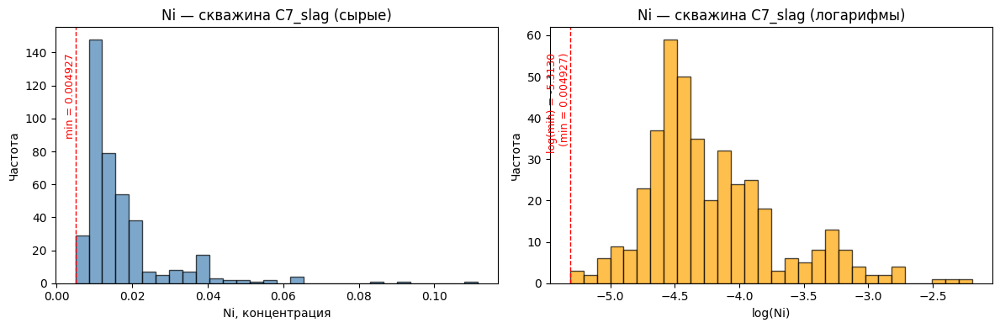

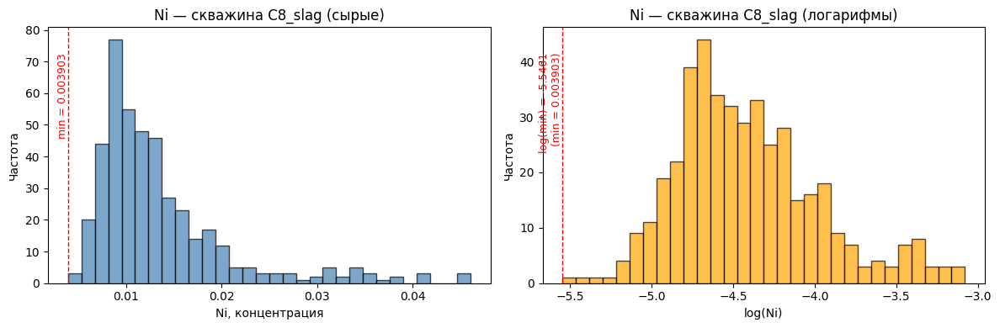

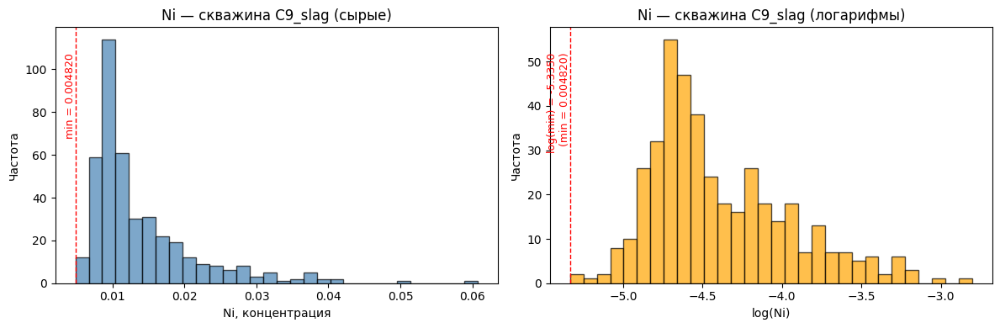

ЭЛЕМЕНТ: Cu
Всего скважин: 21
Скважин с минимумом > 0: 7


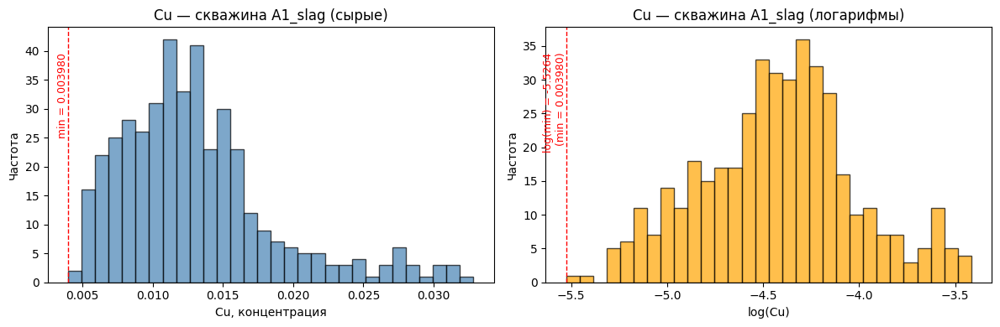

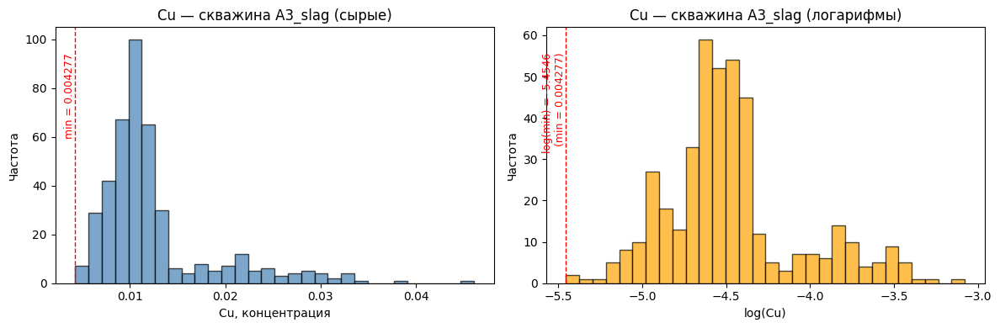

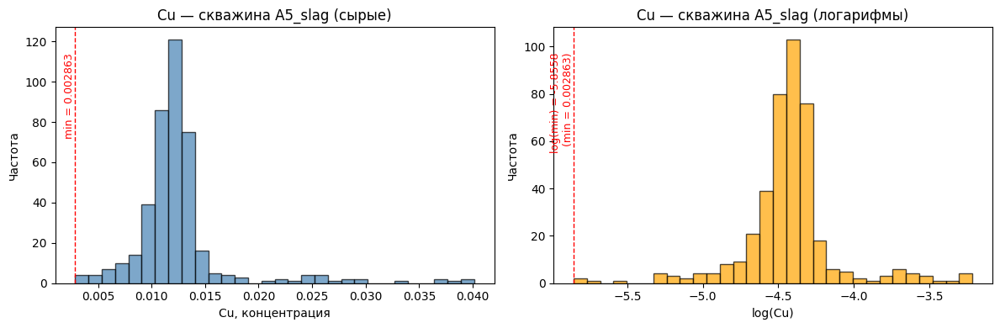

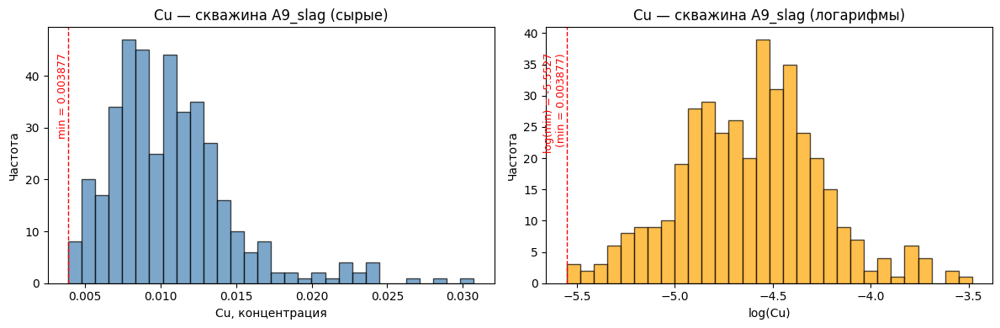

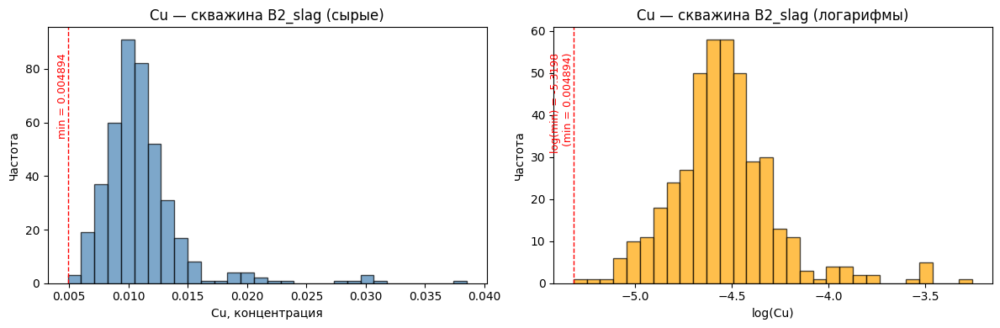

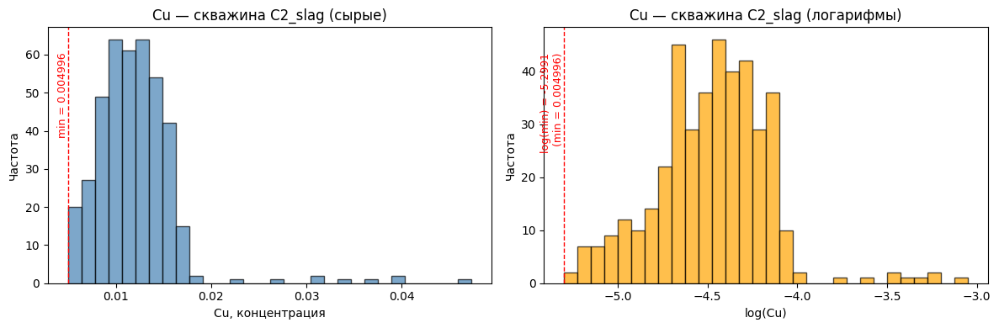

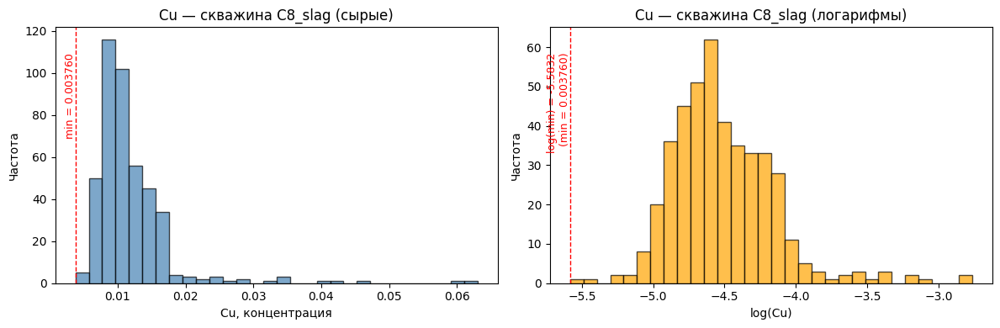

ЭЛЕМЕНТ: Zn
Всего скважин: 21
Скважин с минимумом > 0: 21


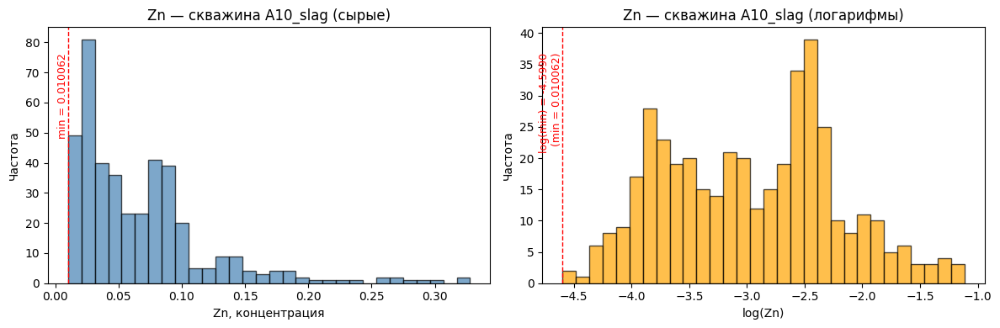

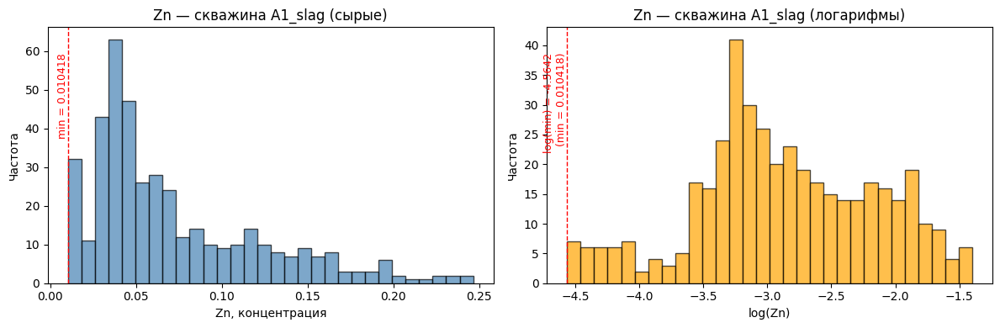

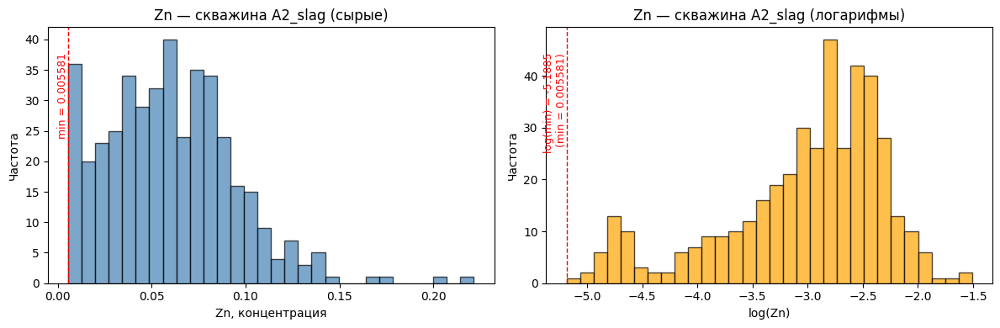

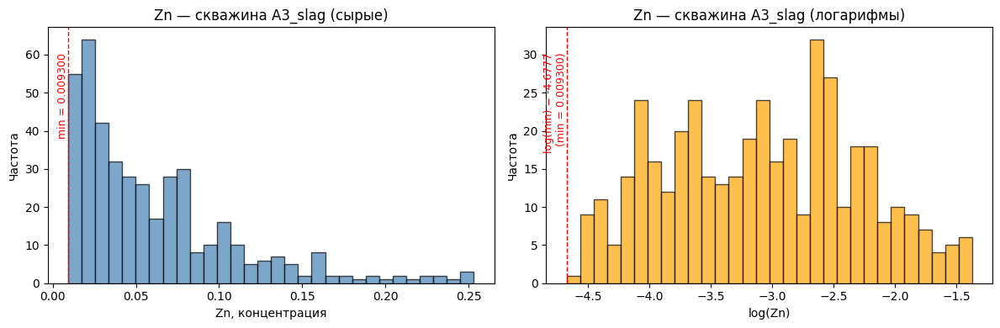

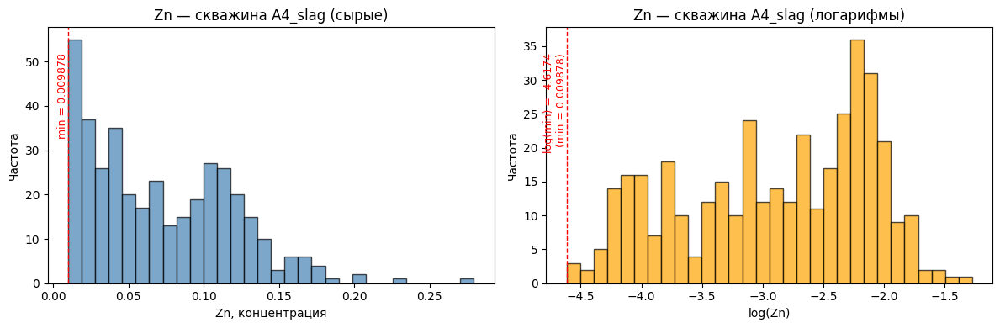

...

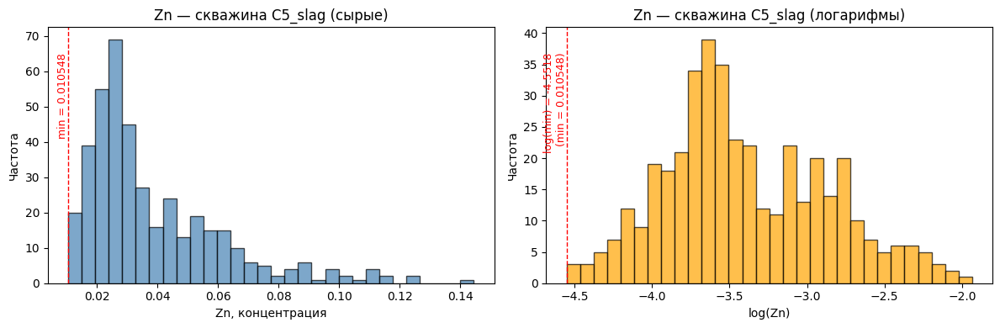

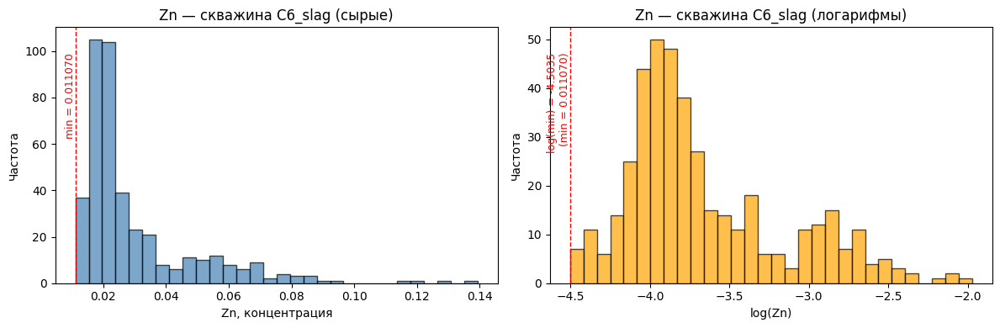

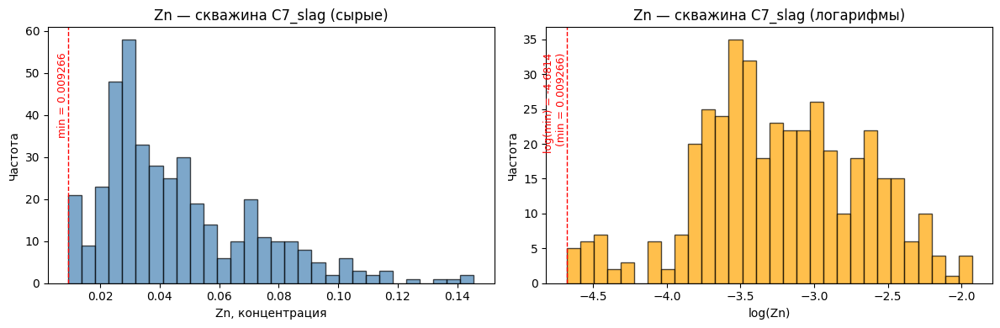

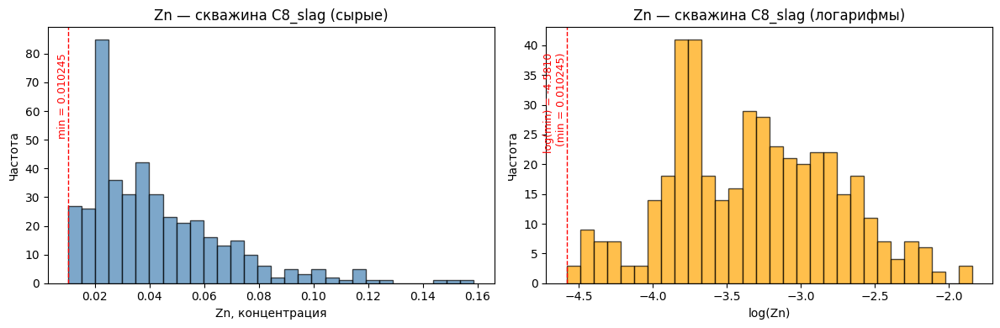

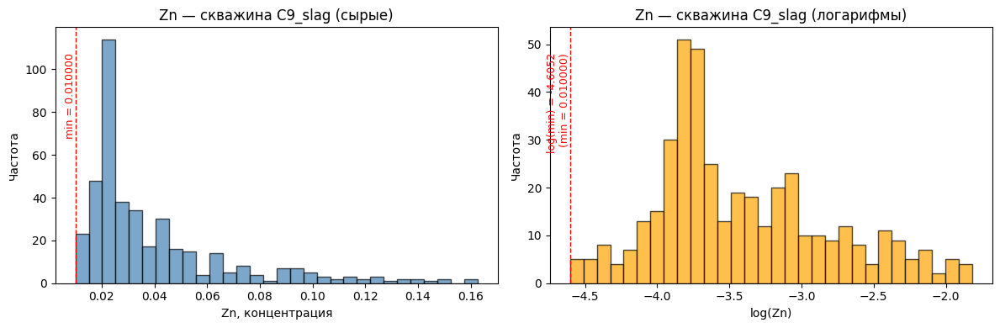

ЭЛЕМЕНТ: Se
Всего скважин: 21
Скважин с минимумом > 0: 0
  (Все скважины имеют минимум = 0 — артефактов нет)
ЭЛЕМЕНТ: Rb
Всего скважин: 21
Скважин с минимумом > 0: 15


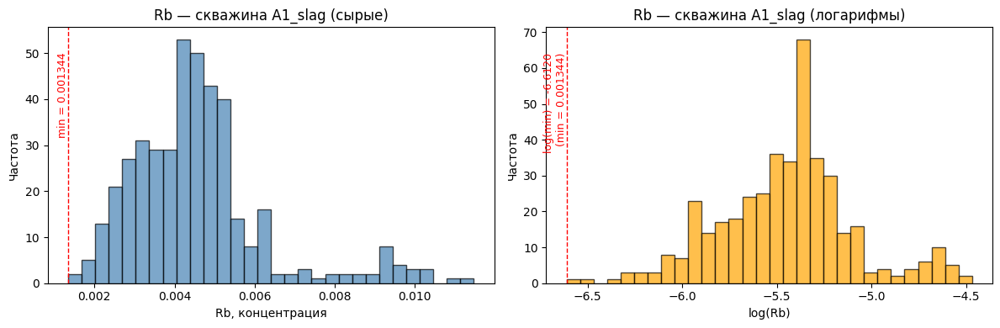

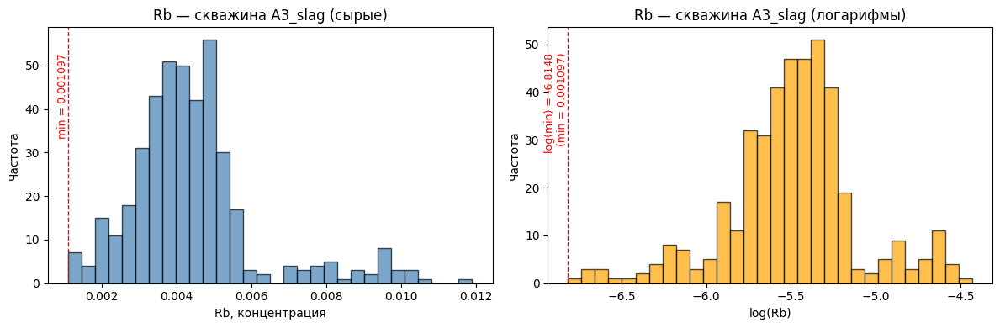

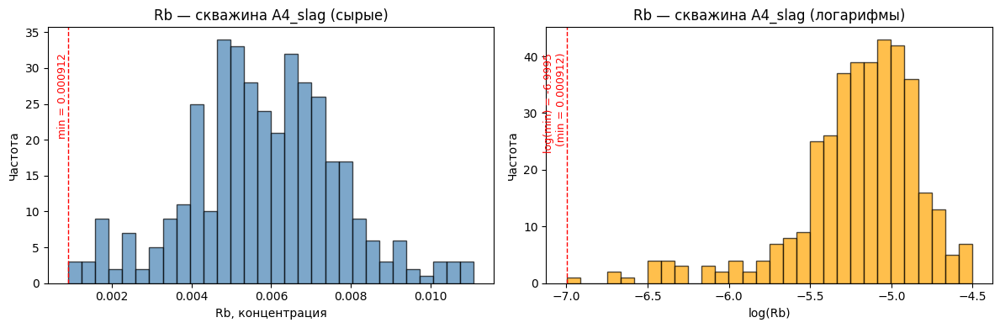

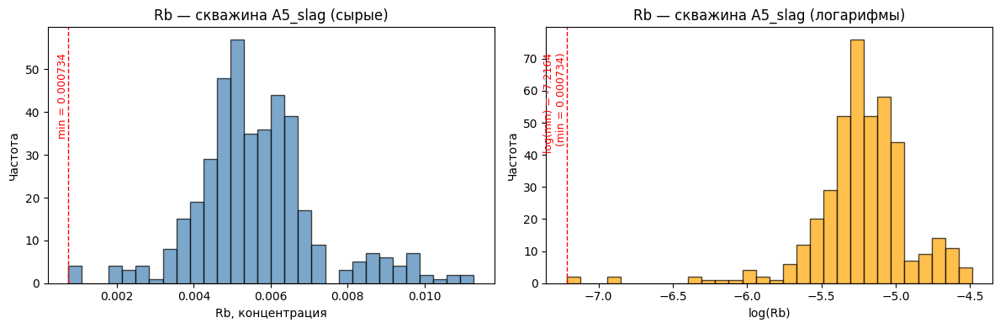

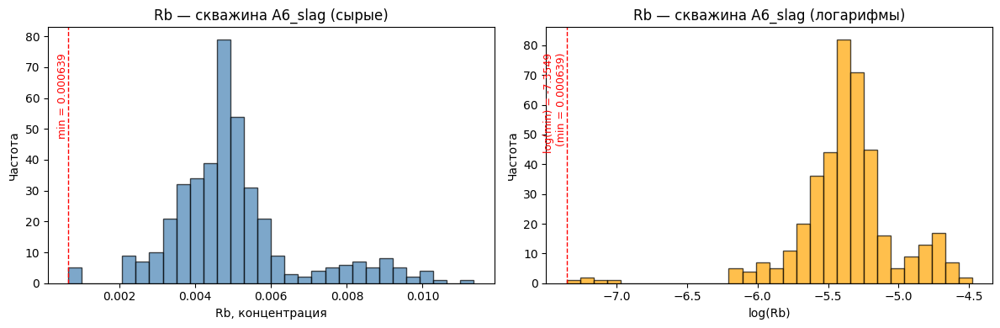

...

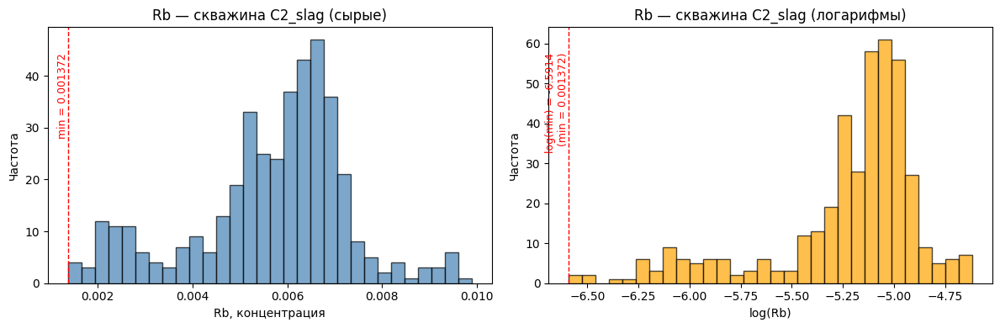

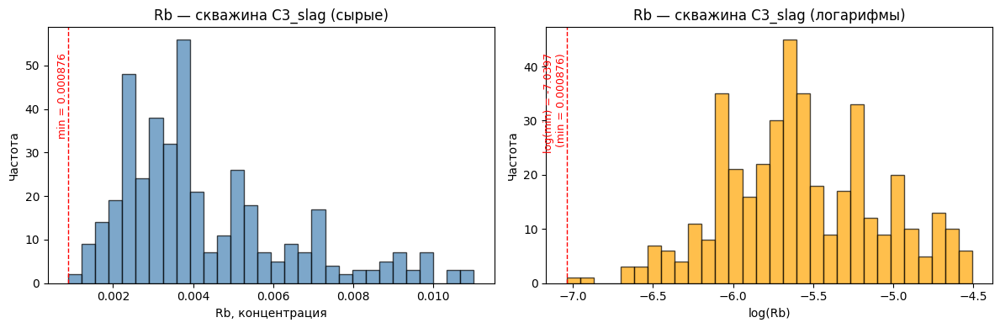

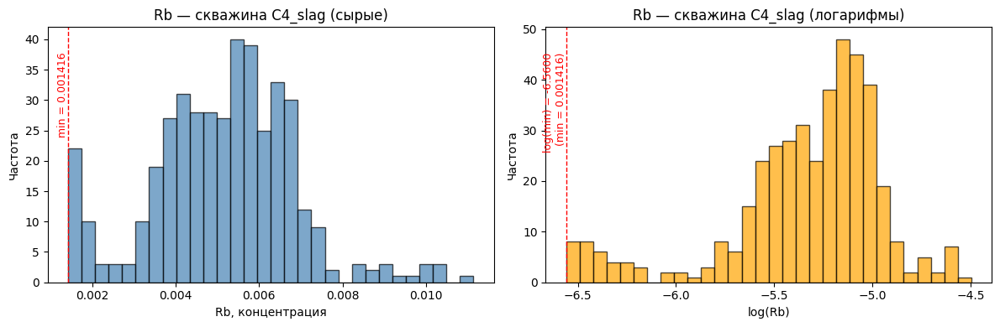

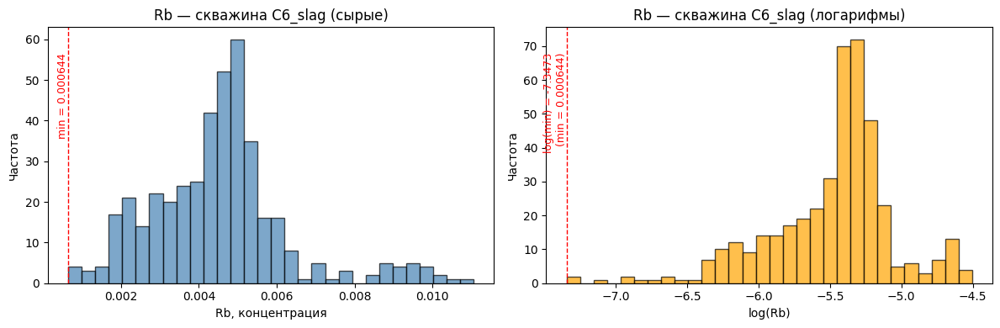

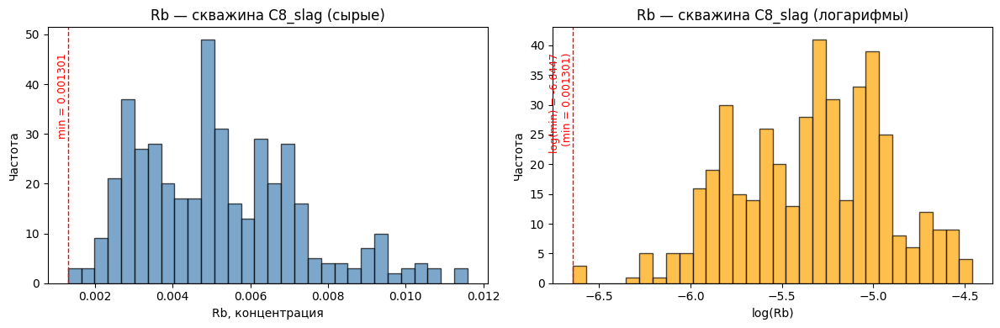

ЭЛЕМЕНТ: Sr
Всего скважин: 21
Скважин с минимумом > 0: 21


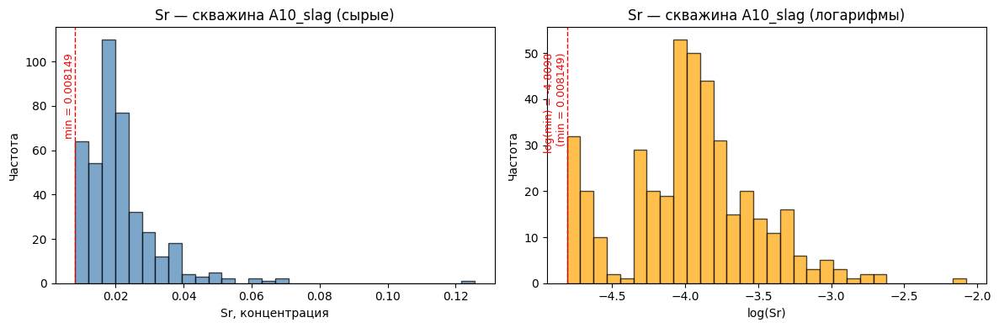

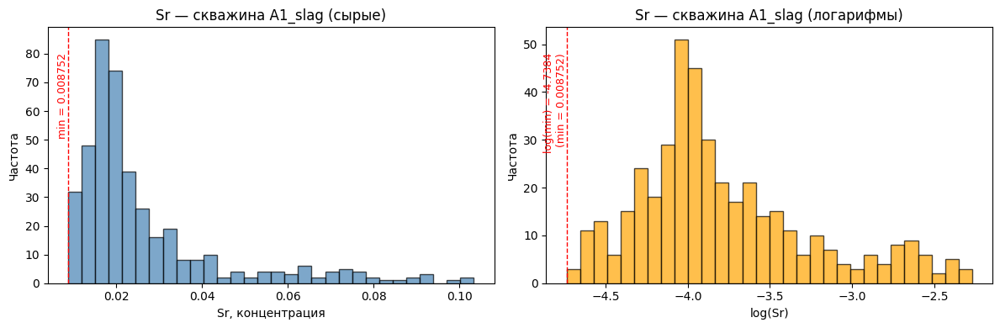

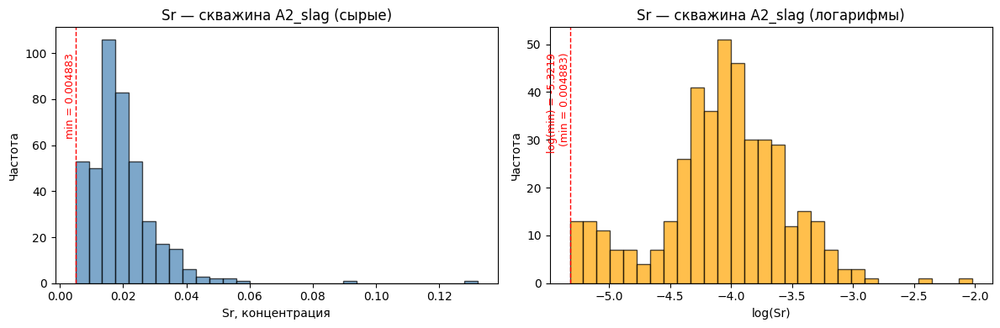

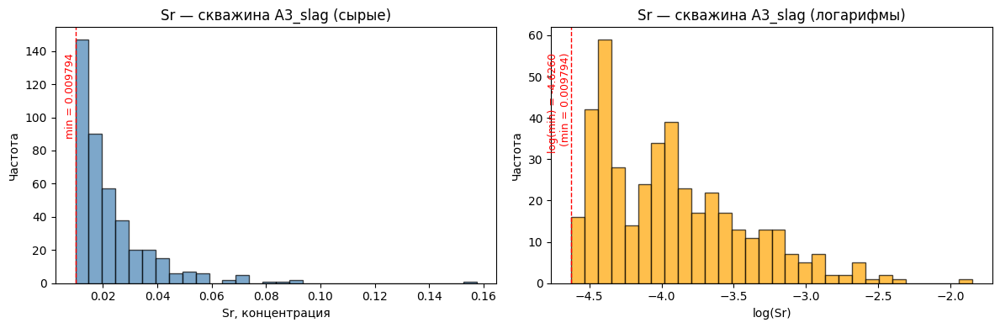

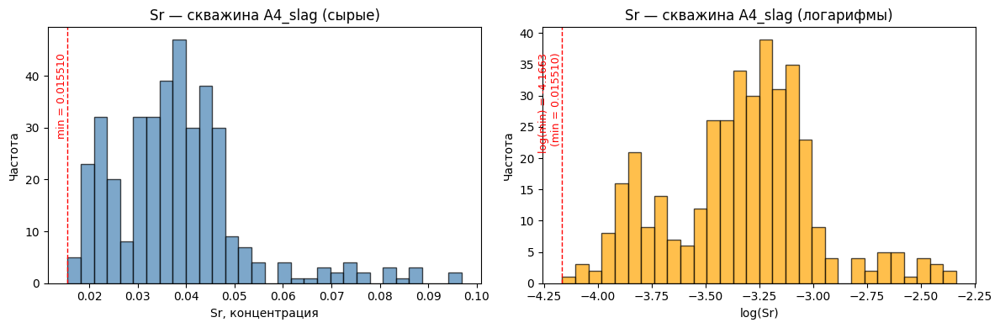

...

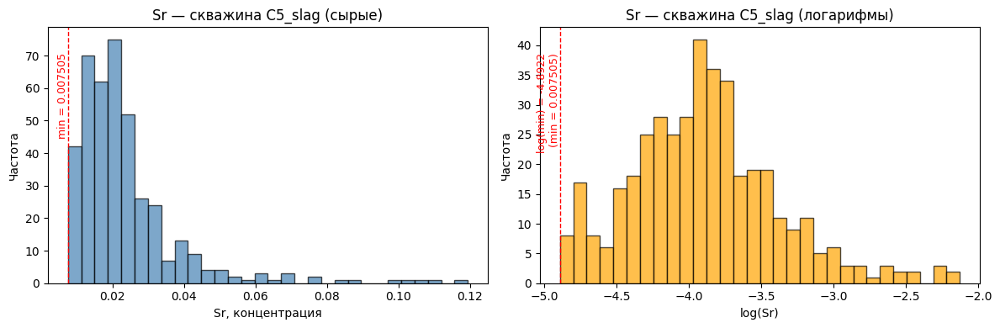

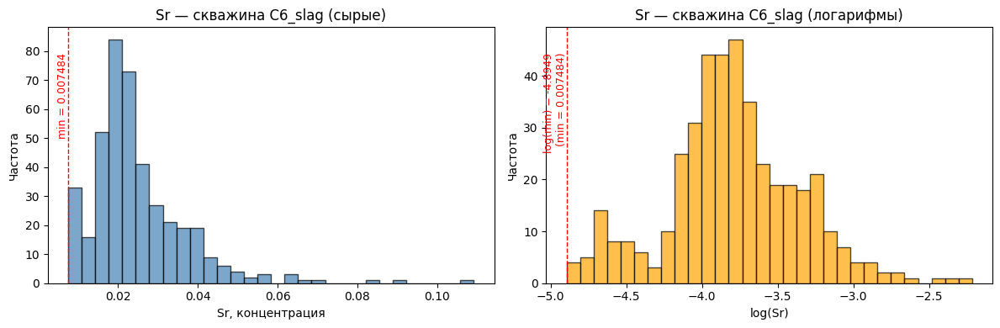

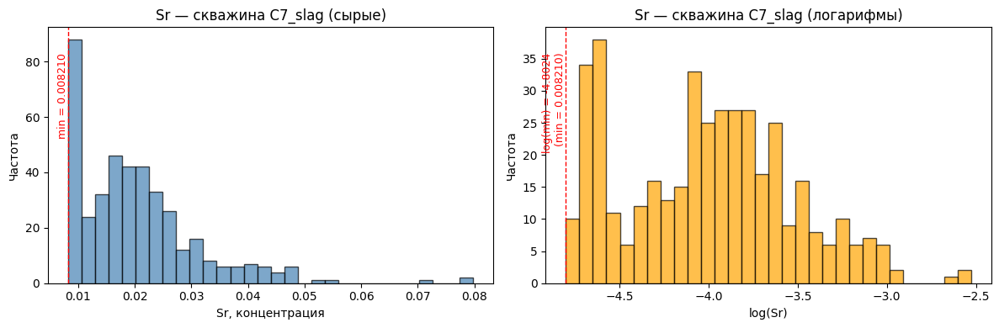

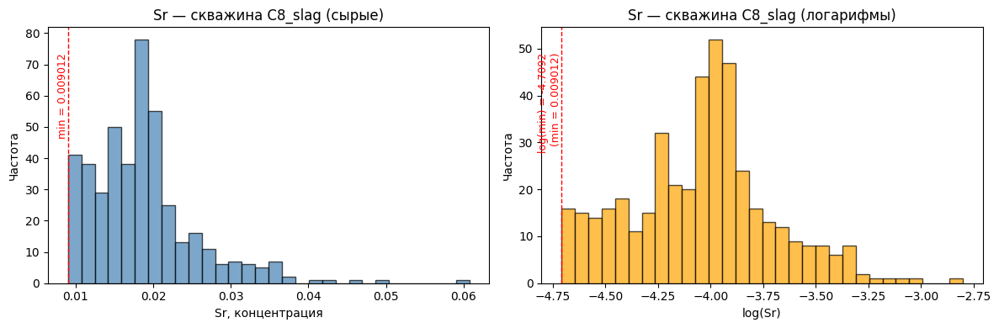

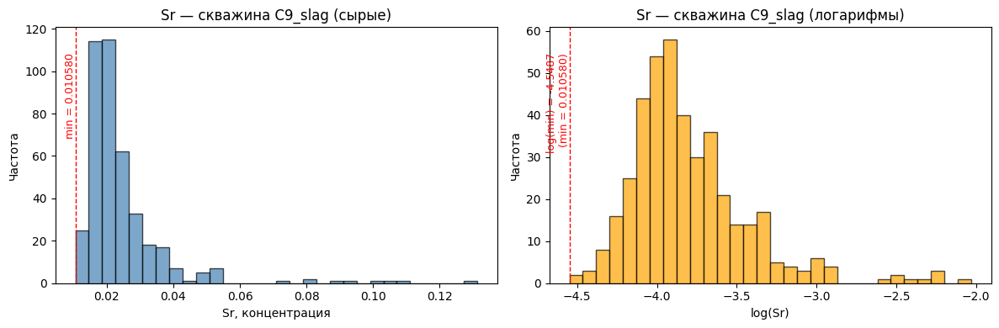

ЭЛЕМЕНТ: Zr
Всего скважин: 21
Скважин с минимумом > 0: 21


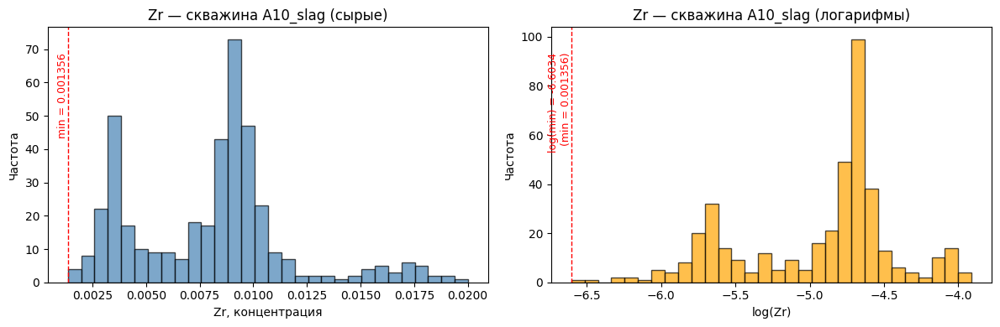

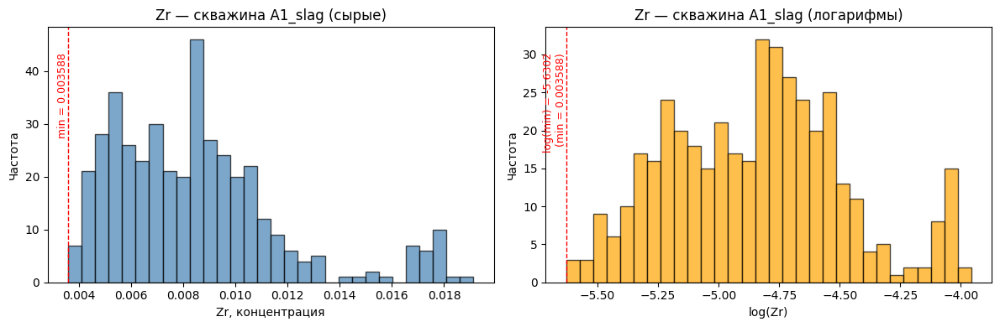

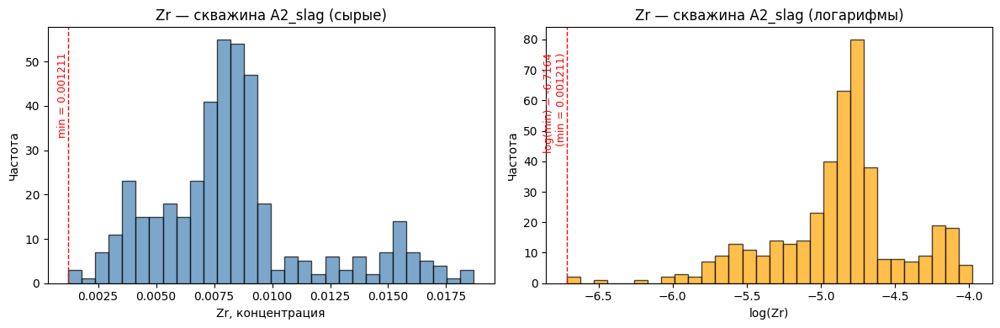

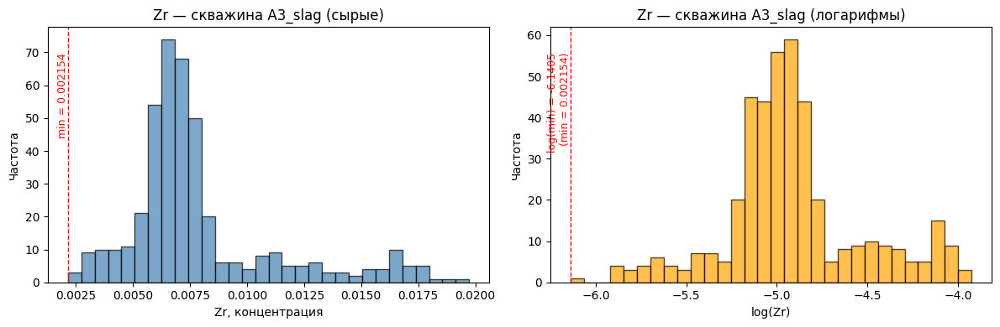

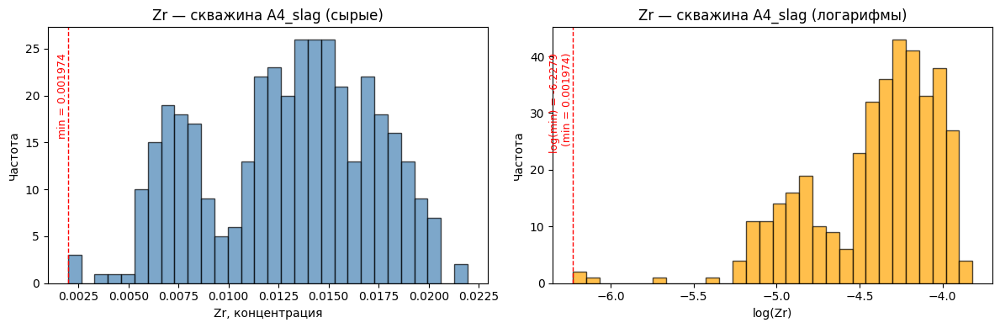

...

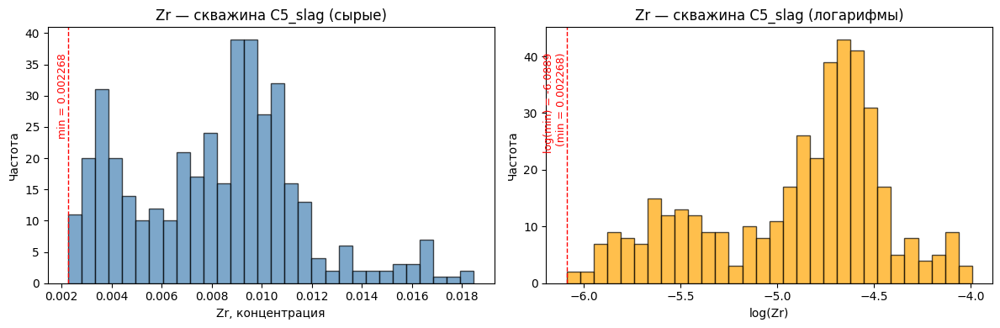

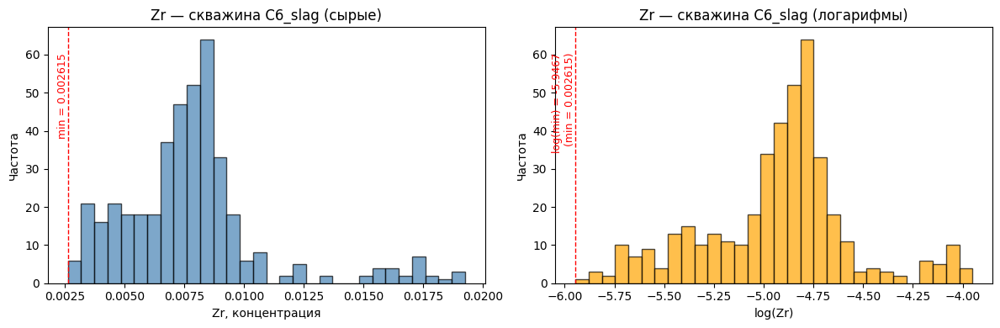

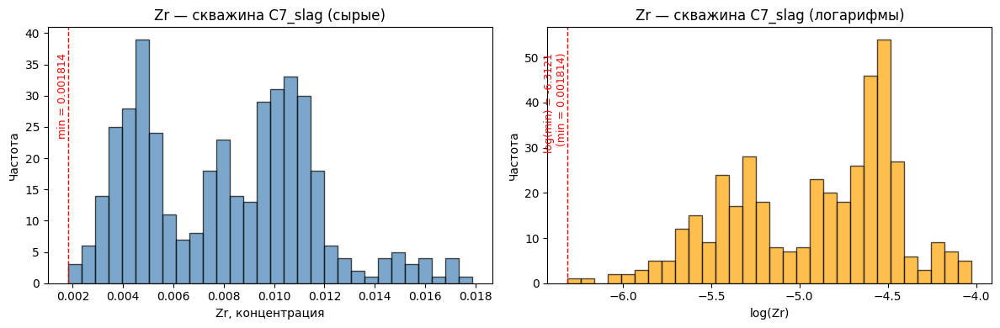

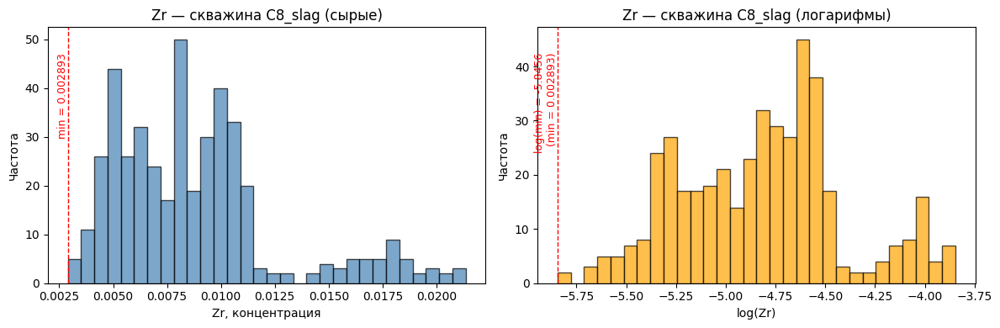

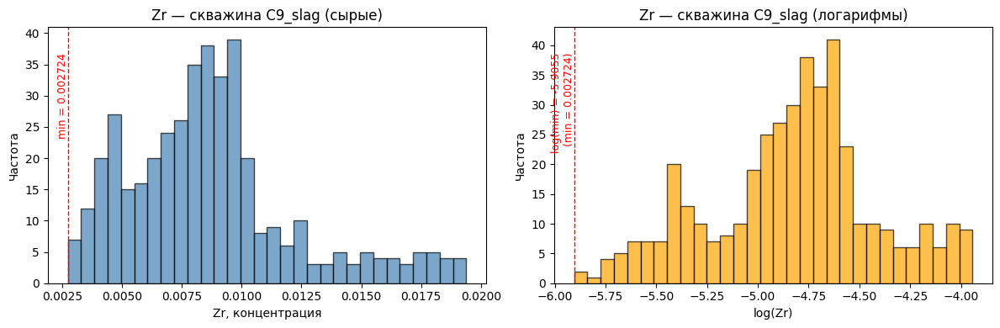

ЭЛЕМЕНТ: Mo
Всего скважин: 21
Скважин с минимумом > 0: 0
  (Все скважины имеют минимум = 0 — артефактов нет)


In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

elements = ['Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe', 
            'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo']

for element in elements:
    if element not in df_filtered.columns:
        print(f"Элемент {element} отсутствует в данных, пропускаем.")
        continue
    
    df_elem = df_filtered[['Well', element]].dropna()
    
    # Находим МИНИМУМ по каждой скважине (включая нули)
    min_by_well = df_elem.groupby('Well')[element].min()
    
    # Оставляем только те скважины, где минимум НЕ равен нулю
    min_nonzero = min_by_well[min_by_well > 0]
    
    
    print(f"ЭЛЕМЕНТ: {element}")
    print(f"Всего скважин: {len(min_by_well)}")
    print(f"Скважин с минимумом > 0: {len(min_nonzero)}")
    
    if len(min_nonzero) == 0:
        print(f"  (Все скважины имеют минимум = 0 — артефактов нет)")
        continue
    
    # Гистограммы для каждой скважины, где минимум не 0
    for well in min_nonzero.index:
        df_well = df_elem[df_elem['Well'] == well]
        values = df_well[element].values
        min_val = values[values > 0].min() if (values > 0).any() else np.nan
        
        # Строим гистограмму сырых значений и логарифмов
        fig, ax = plt.subplots(1, 2, figsize=(12, 4))
        
        # Сырые значения
        ax[0].hist(values, bins=30, color='steelblue', edgecolor='black', alpha=0.7)
        ax[0].set_xlabel(f'{element}, концентрация')
        ax[0].set_ylabel('Частота')
        ax[0].set_title(f'{element} — скважина {well} (сырые)')
        
        # Подпись минимума (ненулевого) на гистограмме
        if not np.isnan(min_val):
            ax[0].axvline(min_val, color='red', linestyle='--', linewidth=1)
            ax[0].text(min_val, ax[0].get_ylim()[1] * 0.9,
                       f'min = {min_val:.6f}',
                       color='red', fontsize=9, rotation=90, va='top', ha='right')
        
        # Логарифмы
        log_values = np.log(values)
        ax[1].hist(log_values, bins=30, color='orange', edgecolor='black', alpha=0.7)
        ax[1].set_xlabel(f'log({element})')
        ax[1].set_ylabel('Частота')
        ax[1].set_title(f'{element} — скважина {well} (логарифмы)')
        
        # Подпись минимума (в логарифмах)
        if not np.isnan(min_val) and min_val > 0:
            log_min = np.log(min_val)
            ax[1].axvline(log_min, color='red', linestyle='--', linewidth=1)
            ax[1].text(log_min, ax[1].get_ylim()[1] * 0.9,
                       f'log(min) = {log_min:.4f}\n(min = {min_val:.6f})',
                       color='red', fontsize=9, rotation=90, va='top', ha='right')
        
        plt.tight_layout()
        plt.savefig(f'hist_{element}_{well}.png', dpi=150, bbox_inches='tight')
        plt.show()
        plt.close()

**Обнуление фальшивых лод**

In [12]:
artifacts = {
    'Mg': [
        (['A1_slag'], 0.307400),
    ],
    'Ti': [
        (['C1_slag'], 0.07),
    ],
    'P': [
        (['C6_slag', 'C7_slag', 'C8_slag', 'B1_slag', 'B2_slag'], 0.02),
    ],
}

total_nulled = 0

for element, artifact_list in artifacts.items():
    if element not in df_filtered.columns:
        print(f"Элемент {element} отсутствует в данных, пропускаем.")
        continue

    print(f"ЭЛЕМЕНТ: {element}")
    
    for wells, value in artifact_list:
        # Маска: скважина из списка И значение совпадает с артефактным (с допуском)
        mask = (
            df_filtered['Well'].isin(wells) & 
            np.isclose(df_filtered[element], value, rtol=1e-4, atol=1e-8)
        )
        count = mask.sum()
        
        if count > 0:
            df_filtered.loc[mask, element] = 0
            print(f"  Скважины {wells}, значение {value}: обнулено {count} проб")
            total_nulled += count
        else:
            print(f"  Скважины {wells}, значение {value}: НЕ НАЙДЕНО (проверьте точность)")

print(f"ВСЕГО ОБНУЛЕНО: {total_nulled} проб")

ЭЛЕМЕНТ: Mg
  Скважины ['A1_slag'], значение 0.3074: обнулено 201 проб
ЭЛЕМЕНТ: Ti
  Скважины ['C1_slag'], значение 0.07: обнулено 56 проб
ЭЛЕМЕНТ: P
  Скважины ['C6_slag', 'C7_slag', 'C8_slag', 'B1_slag', 'B2_slag'], значение 0.02: обнулено 255 проб
ВСЕГО ОБНУЛЕНО: 512 проб


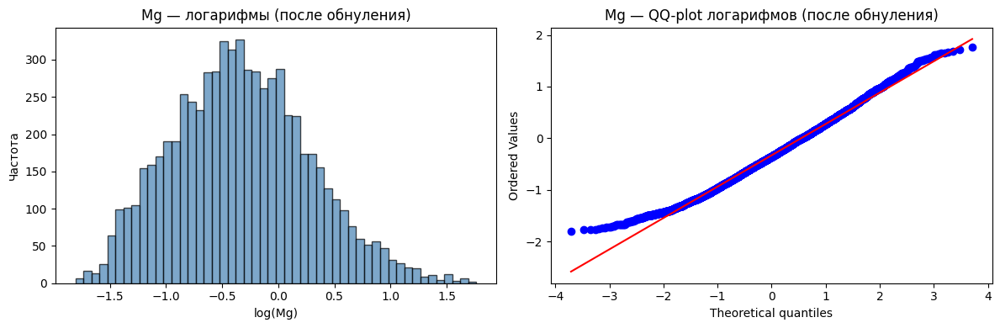

Mg: skew(log) = 0.28, kurt(log) = -0.17


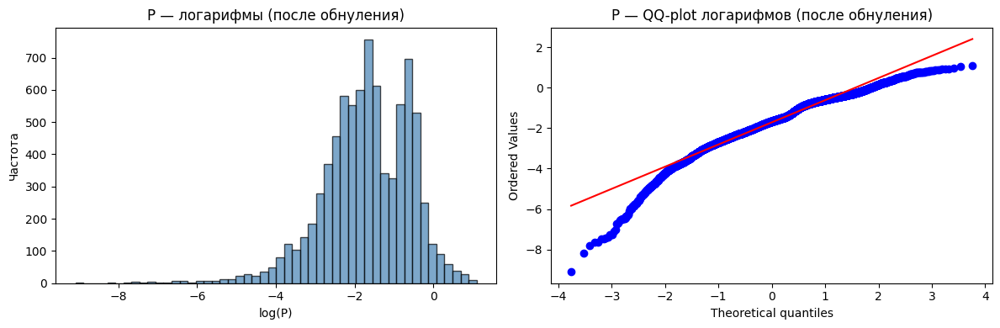

P: skew(log) = -0.82, kurt(log) = 1.97


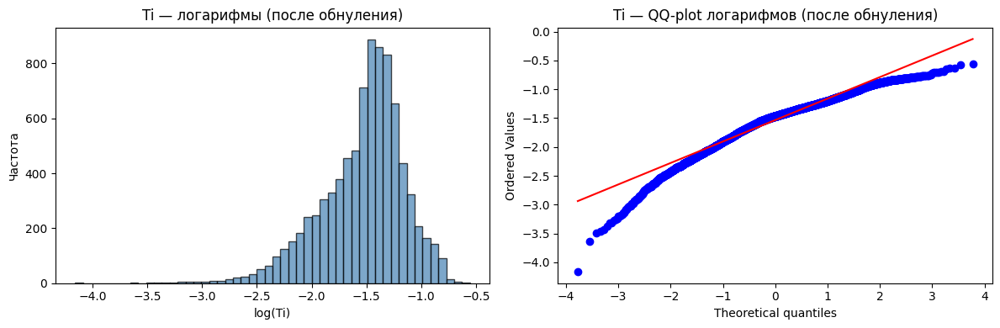

Ti: skew(log) = -0.89, kurt(log) = 1.53


In [13]:
# Элементы, для которых обнуляли артефакты
elements_check = ['Mg', 'P', 'Ti']

for element in elements_check:
    if element not in df_filtered.columns:
        continue
    
    df_elem = df_filtered[element].dropna()
    df_nonzero = df_elem[df_elem > 0]
    
    if len(df_nonzero) < 10:
        print(f"{element}: слишком мало ненулевых значений")
        continue
    
    log_values = np.log(df_nonzero)
    
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    
    # Гистограмма логарифмов
    axes[0].hist(log_values, bins=50, color='steelblue', edgecolor='black', alpha=0.7)
    axes[0].set_xlabel(f'log({element})')
    axes[0].set_ylabel('Частота')
    axes[0].set_title(f'{element} — логарифмы (после обнуления)')
    
    # QQ-plot логарифмов
    stats.probplot(log_values, dist="norm", plot=axes[1])
    axes[1].set_title(f'{element} — QQ-plot логарифмов (после обнуления)')
    
    plt.tight_layout()
    plt.savefig(f'after_clean_{element}.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()
    
    # Параметры скошенности
    from scipy.stats import skew, kurtosis
    print(f"{element}: skew(log) = {skew(log_values):.2f}, kurt(log) = {kurtosis(log_values):.2f}")

**Доля нулей после обнуления артефактов**

In [14]:
# Подсчёт нулей и процентов по каждому элементу
zero_counts = df_filtered[elements].isnull().sum() + (df_filtered[elements] == 0).sum()
total = len(df_filtered)

zero_table = pd.DataFrame({
    'Элемент': zero_counts.index,
    'Нулей': zero_counts.values,
    'Доля нулей, %': (zero_counts.values / total * 100).round(2)
}).sort_values('Доля нулей, %', ascending=False).reset_index(drop=True)

print("Таблица нулевых значений по элементам:")
print(zero_table.to_string(index=False))

# Общее количество
total_zeros = zero_counts.sum()
total_values = total * len(elements)
print(f"\nОбщее количество нулевых значений: {total_zeros}")
print(f"Процент нулевых значений (все элементы): {total_zeros / total_values * 100:.2f}%")

Таблица нулевых значений по элементам:
Элемент  Нулей  Доля нулей, %
     Mg   1966          22.75
      P    522           6.04
     Mo    434           5.02
     Se    198           2.29
     Ti     56           0.65
     Cu     40           0.46
      S     38           0.44
     Rb     18           0.21
     Ni      4           0.05
      K      2           0.02
     Mn      1           0.01
     Si      0           0.00
     Ca      0           0.00
     Al      0           0.00
     Zn      0           0.00
     Sr      0           0.00
     Zr      0           0.00
     Fe      0           0.00

Общее количество нулевых значений: 3279
Процент нулевых значений (все элементы): 2.11%


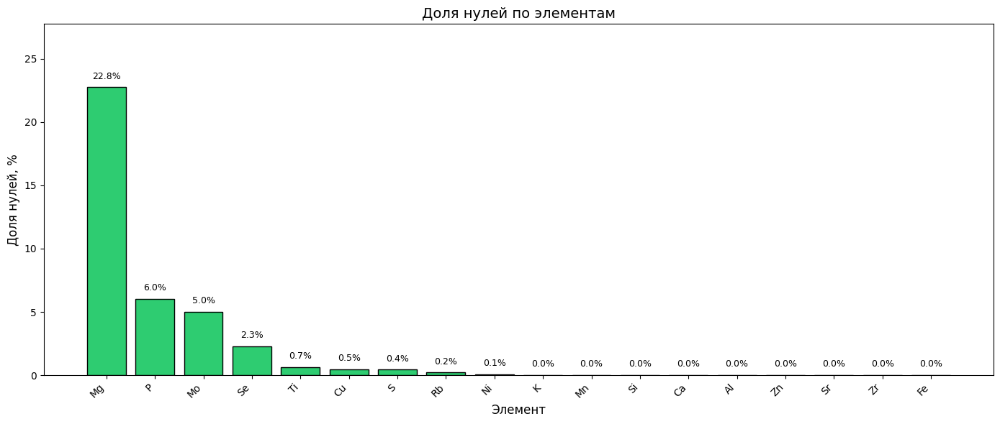

In [15]:
# График: доля нулей по элементам
fig, ax = plt.subplots(figsize=(14, 6))

# Цвета по группам 
def get_color(pct):
    if pct < 30:
        return '#2ecc71'  
    else:
        return '#e74c3c'  

colors = [get_color(p) for p in zero_table['Доля нулей, %']]

bars = ax.bar(zero_table['Элемент'], zero_table['Доля нулей, %'], color=colors, edgecolor='black')

# Подписи значений над столбцами
for bar, pct in zip(bars, zero_table['Доля нулей, %']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{pct:.1f}%', ha='center', va='bottom', fontsize=9)

# Пороговые линии
ax.axhline(y=30, color='red', linestyle='--', alpha=0.5)

ax.set_xlabel('Элемент', fontsize=12)
ax.set_ylabel('Доля нулей, %', fontsize=12)
ax.set_title('Доля нулей по элементам', fontsize=14)

ax.set_ylim(0, max(zero_table['Доля нулей, %']) + 5)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Подсчет значений ниже LOD**

In [16]:
# LOD для каждого элемента
lod = {
    'Mg': 0.1848625,
    'Al': 0.0927875,
    'Si': 0.2984125,
    'Ca': 0.077025,
    'S': 0.3082,
    'K': 0.0271375,
    'Ti': 0.003,
    'Mn': 0.0024375,
    'Fe': 0.09165,
    'Ni': 0.0032625,
    'Cu': 0.00335,
    'Zn': 0.0022375,
    'Rb': 0.0003125,
    'Sr': 0.0013125,
    'Zr': 0.00065,
    'Mo': 0.00105,
    'P': 0.016325,
    'Se': 0.0002375
}


In [17]:
below_lod = pd.Series({e: ((df_filtered[e] > 0) & (df_filtered[e] < lod[e])).sum() for e in elements})

print("Количество значений ниже LOD (без нулей):")
print(below_lod)

print(f"\nВсего ниже LOD: {below_lod.sum()}")
print(f"Процент: {(below_lod.sum() / (len(df_filtered) * len(elements))) * 100:.2f}%")


Количество значений ниже LOD (без нулей):
Mg     12
Al      0
Si      0
P     203
S      61
K       2
Ca      0
Ti      0
Mn    176
Fe      0
Ni      1
Cu     18
Zn      0
Se    145
Rb      0
Sr      0
Zr      0
Mo    701
dtype: int64

Всего ниже LOD: 1319
Процент: 0.85%


**Поиск минимальных значений по элементам**

In [18]:
min_values = pd.Series({e: df_filtered.loc[df_filtered[e] > 0, e].min() for e in elements})

print("Минимальные значения (исключая 0):")
print(min_values)

Минимальные значения (исключая 0):
Mg    0.164027
Al    0.383441
Si    5.231311
P     0.000112
S     0.178708
K     0.000100
Ca    0.344116
Ti    0.015601
Mn    0.000713
Fe    0.297874
Ni    0.002771
Cu    0.002350
Zn    0.005581
Se    0.000040
Rb    0.000392
Sr    0.004883
Zr    0.001211
Mo    0.000450
dtype: float64


**Минимальное или LOD, если он меньше**

In [19]:
result = pd.Series({e: min(min_values[e], lod[e]) for e in elements})

print("Минимум (меньше из минимального значения и LOD):")
print(result)

Минимум (меньше из минимального значения и LOD):
Mg    0.164027
Al    0.092787
Si    0.298413
P     0.000112
S     0.178708
K     0.000100
Ca    0.077025
Ti    0.003000
Mn    0.000713
Fe    0.091650
Ni    0.002771
Cu    0.002350
Zn    0.002237
Se    0.000040
Rb    0.000313
Sr    0.001313
Zr    0.000650
Mo    0.000450
dtype: float64


**Замена нулей на LOD/корень из 2**

In [20]:
lod_values = {
    'Mg': 0.130200,
    'Al': 0.013244,
    'Si': 0.026589,
    'P':  0.000358,
    'S':  0.075067,
    'K':  0.003822,
    'Ca': 0.000877,
    'Ti': 0.000446,
    'Mn': 0.001031,
    'Fe': 0.002603,
    'Ni': 0.000112,
    'Cu': 0.002408,
    'Zn': 0.002237,
    'Se': 0.000005,
    'Rb': 0.000313,
    'Sr': 0.001313,
    'Zr': 0.000092,
    'Mo': 0.000663,
}

# Замена нулей на LOD/√2
for el in elements:
    if el not in df_filtered.columns:
        continue
    replacement = lod_values[el] / np.sqrt(2)
    n_replaced = (df_filtered[el] == 0).sum()
    df_filtered[el] = df_filtered[el].replace(0, replacement)
    print(f"{el}: заменено {n_replaced} нулей на LOD/√2 = {replacement:.8f}")

# Проверка
print("\nНулей после замены (должно быть 0):")
print((df_filtered[elements] == 0).sum())

Mg: заменено 1966 нулей на LOD/√2 = 0.09206530
Al: заменено 0 нулей на LOD/√2 = 0.00936492
Si: заменено 0 нулей на LOD/√2 = 0.01880126
P: заменено 522 нулей на LOD/√2 = 0.00025314
S: заменено 38 нулей на LOD/√2 = 0.05308038
K: заменено 2 нулей на LOD/√2 = 0.00270256
Ca: заменено 0 нулей на LOD/√2 = 0.00062013
Ti: заменено 56 нулей на LOD/√2 = 0.00031537
Mn: заменено 1 нулей на LOD/√2 = 0.00072903
Fe: заменено 0 нулей на LOD/√2 = 0.00184060
Ni: заменено 4 нулей на LOD/√2 = 0.00007920
Cu: заменено 40 нулей на LOD/√2 = 0.00170271
Zn: заменено 0 нулей на LOD/√2 = 0.00158180
Se: заменено 198 нулей на LOD/√2 = 0.00000354
Rb: заменено 18 нулей на LOD/√2 = 0.00022132
Sr: заменено 0 нулей на LOD/√2 = 0.00092843
Zr: заменено 0 нулей на LOD/√2 = 0.00006505
Mo: заменено 434 нулей на LOD/√2 = 0.00046881

Нулей после замены (должно быть 0):
Mg    0
Al    0
Si    0
P     0
S     0
K     0
Ca    0
Ti    0
Mn    0
Fe    0
Ni    0
Cu    0
Zn    0
Se    0
Rb    0
Sr    0
Zr    0
Mo    0
dtype: int64


**Оценка межскважинной вариативности**

In [21]:
# Подготовка данных
elements_pca = ['Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe', 
                'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo']

# Извлекаем матрицу концентраций (пробы × 18 элементов)
X_raw = df_filtered[elements_pca].values
wells = df_filtered['Well'].values
n_samples, D = X_raw.shape
print(f"Матрица: {n_samples} проб, {D} элементов")

Матрица: 8643 проб, 18 элементов


In [22]:
X_raw = df_filtered[elements_pca].values

print("Форма:", X_raw.shape) 
print("Нулей:", (X_raw == 0).sum())
print("NaN:", np.isnan(X_raw).sum())
print("Отрицательных:", (X_raw < 0).sum())
print("Min по элементам:")
for i, el in enumerate(elements_pca):
    print(f"  {el}: {X_raw[:, i].min():.10f}")

Форма: (8643, 18)
Нулей: 0
NaN: 0
Отрицательных: 0
Min по элементам:
  Mg: 0.0920653029
  Al: 0.3834406400
  Si: 5.2313110500
  P: 0.0001121100
  S: 0.0530803847
  K: 0.0001000000
  Ca: 0.3441161000
  Ti: 0.0003153696
  Mn: 0.0007126200
  Fe: 0.2978739000
  Ni: 0.0000791960
  Cu: 0.0017027131
  Zn: 0.0055805400
  Se: 0.0000035355
  Rb: 0.0002213244
  Sr: 0.0048832500
  Zr: 0.0012108800
  Mo: 0.0004505000


ILR-матрица: (8643, 17)
Объяснённая дисперсия (PC1, PC2): 87.45%
Scores CLR: (8643, 18), Loadings CLR: (18, 17)


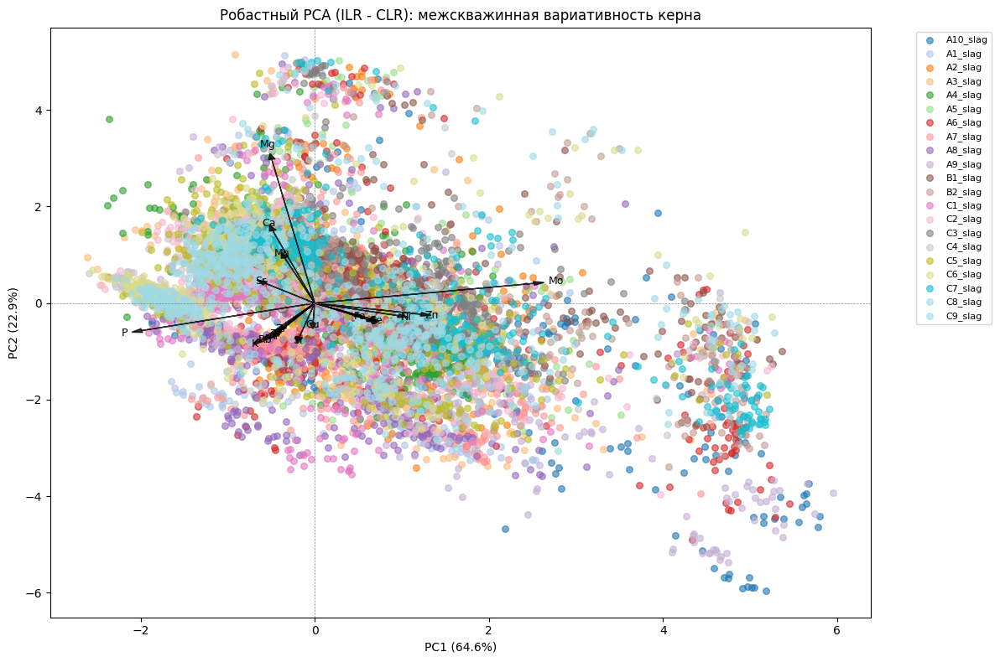

In [23]:
# Isometric Log-Ratio
def ilr_transformation(X):
    """
    ILR-преобразование
    Возвращает матрицу Z размерности (n_samples, D-1).
    """
    n, D = X.shape
    log_X = np.log(X)
    
    # Строим ортонормированный базис V (D × (D-1))
    # Формула (4) из статьи Filzmoser et al. (2009)
    V = np.zeros((D, D - 1))
    for i in range(1, D):  # i = 1, ..., D-1
        # v_i = sqrt(i/(i+1)) * (1/i, ..., 1/i, -1, 0, ..., 0)
        v = np.zeros(D)
        v[:i] = 1.0 / i
        v[i] = -1.0
        V[:, i - 1] = np.sqrt(i / (i + 1)) * v
    
    # Z = log(X) @ V  (размерность n × (D-1))
    Z = log_X @ V
    return Z, V

Z, V = ilr_transformation(X_raw)
print(f"ILR-матрица: {Z.shape}")

# РОБАСТНЫЙ PCA (через MCD-оценку ковариации)
# Оцениваем робастную ковариацию и центр
mcd = MinCovDet(random_state=42, support_fraction=0.75)
mcd.fit(Z)

# Центр и ковариационная матрица в ILR-пространстве
T_z = mcd.location_
C_z = mcd.covariance_

# Собственное разложение
U_z, S_z, Vt_z = svd(C_z)
# Сортируем по убыванию собственных значений (svd уже сортирует)
eigenvalues = S_z ** 2
explained_variance = eigenvalues / eigenvalues.sum()

print(f"Объяснённая дисперсия (PC1, PC2): {explained_variance[:2].sum():.2%}")

# Scores в ILR-пространстве (центрируем и проецируем)
Z_centered = Z - T_z
scores_ilr = Z_centered @ U_z  # (n × (D-1))

# Loadings в ILR-пространстве
loadings_ilr = U_z


# ОБРАТНОЕ ПРЕОБРАЗОВАНИЕ В CLR-ПРОСТРАНСТВО
# Формула (12) из статьи: Y* = Z* @ V^T
scores_clr = scores_ilr @ V.T  # (n × D)

# Формула (13): G_Y = V @ G_Z
loadings_clr = V @ loadings_ilr  # (D × (D-1))

print(f"Scores CLR: {scores_clr.shape}, Loadings CLR: {loadings_clr.shape}")

# Biplot с раскраской по скважинам)
fig, ax = plt.subplots(figsize=(12, 8))

# Уникальные скважины и цвета
unique_wells = np.unique(wells)
colors = plt.cm.tab20(np.linspace(0, 1, len(unique_wells)))

# Scatter plot: scores по PC1 и PC2, цвет = скважина
for i, well in enumerate(unique_wells):
    mask = wells == well
    ax.scatter(scores_clr[mask, 0], scores_clr[mask, 1], 
               label=well, alpha=0.6, s=30, color=colors[i])

# Стрелки loadings (вклад элементов)
scale_factor = 0.5 * np.max(np.abs(scores_clr[:, :2])) / np.max(np.abs(loadings_clr[:, :2]))
for j, element in enumerate(elements_pca):
    ax.arrow(0, 0, 
             loadings_clr[j, 0] * scale_factor, 
             loadings_clr[j, 1] * scale_factor,
             head_width=0.02 * scale_factor, head_length=0.03 * scale_factor,
             fc='black', ec='black', alpha=0.8)
    ax.text(loadings_clr[j, 0] * scale_factor * 1.1, 
            loadings_clr[j, 1] * scale_factor * 1.1,
            element, fontsize=9, ha='center', va='center')

ax.axhline(0, color='grey', linestyle='--', linewidth=0.5)
ax.axvline(0, color='grey', linestyle='--', linewidth=0.5)
ax.set_xlabel(f'PC1 ({explained_variance[0]:.1%})')
ax.set_ylabel(f'PC2 ({explained_variance[1]:.1%})')
ax.set_title('Робастный PCA (ILR - CLR): межскважинная вариативность керна')
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.savefig('robust_pca_interwell.png', dpi=300, bbox_inches='tight')
plt.show()

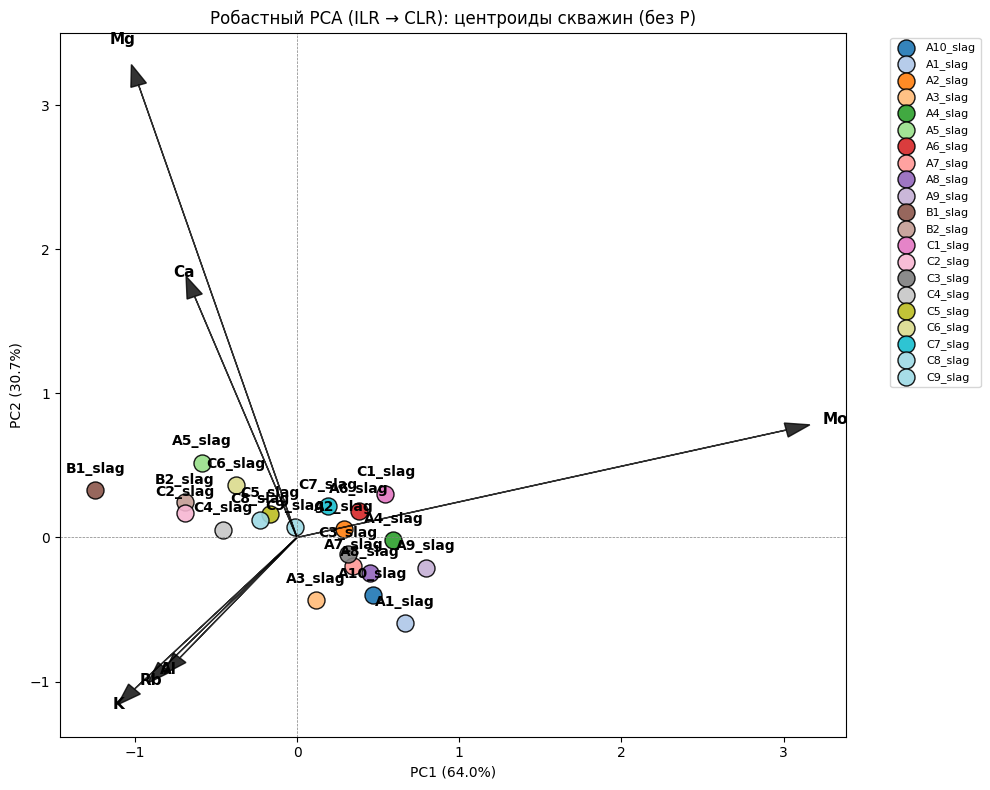

In [24]:
# Подготовка данных (БЕЗ P)
elements_pca = ['Mg', 'Al', 'Si', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe', 
                'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo']

X_raw = df_filtered[elements_pca].values.copy()
wells = df_filtered['Well'].values

# Замена отрицательных/нулей (если есть)
X_raw = np.where(X_raw <= 0, 1e-10, X_raw)

# ILR
def ilr_transformation(X):
    n, D = X.shape
    log_X = np.log(X)
    V = np.zeros((D, D - 1))
    for i in range(1, D):
        v = np.zeros(D)
        v[:i] = 1.0 / i
        v[i] = -1.0
        V[:, i - 1] = np.sqrt(i / (i + 1)) * v
    Z = log_X @ V
    return Z, V

Z, V = ilr_transformation(X_raw)

# Робастный PCA
mcd = MinCovDet(random_state=42, support_fraction=0.75)
mcd.fit(Z)
T_z = mcd.location_
C_z = mcd.covariance_
U_z, S_z, Vt_z = svd(C_z)
eigenvalues = S_z ** 2
explained_variance = eigenvalues / eigenvalues.sum()

Z_centered = Z - T_z
scores_ilr = Z_centered @ U_z
loadings_ilr = U_z

# Обратное преобразование
scores_clr = scores_ilr @ V.T
loadings_clr = V @ loadings_ilr

# Визуализация: центроиды скважин + топ-6 стрелок
fig, ax = plt.subplots(figsize=(10, 8))

# Центроиды скважин
unique_wells = np.unique(wells)
colors = plt.cm.tab20(np.linspace(0, 1, len(unique_wells)))

for i, well in enumerate(unique_wells):
    mask = wells == well
    # Центроид (среднее по скважине)
    centroid = scores_clr[mask, :2].mean(axis=0)
    ax.scatter(centroid[0], centroid[1], s=150, color=colors[i], 
               edgecolor='black', label=well, alpha=0.9)
    # Подпись скважины
    ax.text(centroid[0], centroid[1] + 0.1, well, fontsize=10, 
            ha='center', va='bottom', fontweight='bold')

# Топ-6 элементов по loadings
loadings_df = pd.DataFrame(loadings_clr[:, :2], index=elements_pca, columns=['PC1', 'PC2'])
# Топ по сумме абсолютных нагрузок
top6 = loadings_df.abs().sum(axis=1).nlargest(6).index.tolist()

scale_factor = 0.5 * np.max(np.abs(scores_clr[:, :2])) / np.max(np.abs(loadings_clr[:, :2]))
for element in top6:
    x = loadings_df.loc[element, 'PC1'] * scale_factor
    y = loadings_df.loc[element, 'PC2'] * scale_factor
    ax.arrow(0, 0, x, y, head_width=0.1, head_length=0.15, 
             fc='black', ec='black', alpha=0.8)
    ax.text(x * 1.1, y * 1.1, element, fontsize=11, 
            ha='center', va='center', fontweight='bold')

ax.axhline(0, color='grey', linestyle='--', linewidth=0.5)
ax.axvline(0, color='grey', linestyle='--', linewidth=0.5)
ax.set_xlabel(f'PC1 ({explained_variance[0]:.1%})')
ax.set_ylabel(f'PC2 ({explained_variance[1]:.1%})')
ax.set_title('Робастный PCA (ILR → CLR): центроиды скважин (без P)')
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.savefig('robust_pca_interwell_centroids.png', dpi=300, bbox_inches='tight')
plt.show()

**Керн+Шлам**

Отсутствуют в шламе: []
Отсутствуют в керне: []


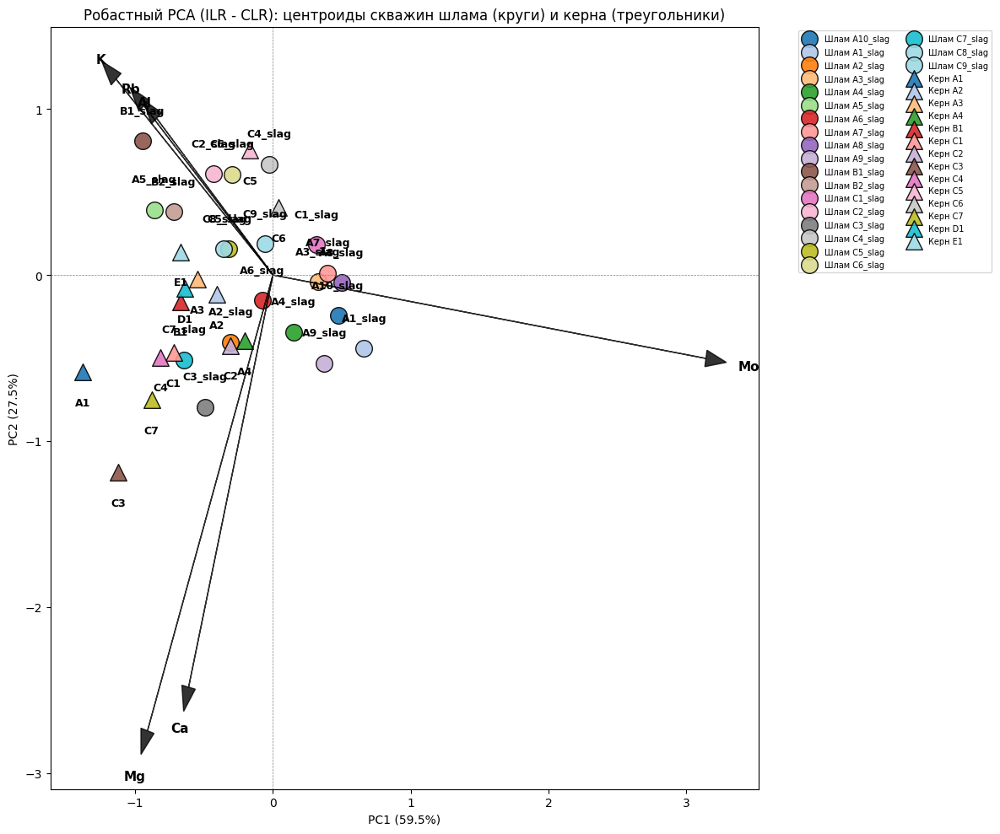

In [25]:
# Загрузка данных
df_kern = pd.read_csv('Data/data_kern_ratios_04_11.csv')

# Список элементов (без P)
elements_pca = ['Mg', 'Al', 'Si', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe', 
                'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo']

# Проверка колонок в шламе
missing_s = [el for el in elements_pca if el not in df_filtered.columns]
missing_kern = [el for el in elements_pca if el not in df_kern.columns]
print(f"Отсутствуют в шламе: {missing_s}")
print(f"Отсутствуют в керне: {missing_kern}")

# Подготовка данных
# Шлам
X_s = df_filtered[elements_pca].values.copy()
wells_s = df_filtered['Well'].values

# Керн
X_kern = df_kern[elements_pca].values.copy()
wells_kern = df_kern['Well'].values

# Объединяем керн и шлам
X_all = np.vstack([X_s, X_kern])
wells_all = np.concatenate([wells_s, wells_kern])
source = np.array(['s'] * len(X_s) + ['kern'] * len(X_kern))
def ilr_transformation(X):
    n, D = X.shape
    log_X = np.log(X)
    V = np.zeros((D, D - 1))
    for i in range(1, D):
        v = np.zeros(D)
        v[:i] = 1.0 / i
        v[i] = -1.0
        V[:, i - 1] = np.sqrt(i / (i + 1)) * v
    Z = log_X @ V
    return Z, V

Z, V = ilr_transformation(X_all)

# Робастный PCA
mcd = MinCovDet(random_state=42, support_fraction=0.75)
mcd.fit(Z)
T_z = mcd.location_
C_z = mcd.covariance_
U_z, S_z, Vt_z = svd(C_z)
eigenvalues = S_z ** 2
explained_variance = eigenvalues / eigenvalues.sum()

Z_centered = Z - T_z
scores_ilr = Z_centered @ U_z
loadings_ilr = U_z

# Обратное преобразование в CLR
scores_clr = scores_ilr @ V.T
loadings_clr = V @ loadings_ilr

# Визуализация: центроиды скважин керна и шлама
fig, ax = plt.subplots(figsize=(12, 10))

# Шлам - круги
unique_wells_s = np.unique(wells_s)
colors_s = plt.cm.tab20(np.linspace(0, 1, len(unique_wells_s)))

for i, well in enumerate(unique_wells_s):
    mask = (wells_all == well) & (source == 's')
    if mask.sum() == 0:
        continue
    centroid = scores_clr[mask, :2].mean(axis=0)
    ax.scatter(centroid[0], centroid[1], s=200, color=colors_s[i], 
               edgecolor='black', marker='o', label=f'Шлам {well}', alpha=0.9)
    ax.text(centroid[0], centroid[1] + 0.15, well, fontsize=9,
            ha='center', va='bottom', fontweight='bold')

# Керн - треугольники
unique_wells_kern = np.unique(wells_kern)
colors_kern = plt.cm.tab20(np.linspace(0, 1, len(unique_wells_kern)))

for i, well in enumerate(unique_wells_kern):
    mask = (wells_all == well) & (source == 'kern')
    if mask.sum() == 0:
        continue
    centroid = scores_clr[mask, :2].mean(axis=0)
    ax.scatter(centroid[0], centroid[1], s=200, color=colors_kern[i],
               edgecolor='black', marker='^', label=f'Керн {well}', alpha=0.9)
    ax.text(centroid[0], centroid[1] - 0.15, well, fontsize=9,
            ha='center', va='top', fontweight='bold')

# Топ-6 элементов
loadings_df = pd.DataFrame(loadings_clr[:, :2], index=elements_pca, columns=['PC1', 'PC2'])
top6 = loadings_df.abs().sum(axis=1).nlargest(6).index.tolist()

scale_factor = 0.5 * np.max(np.abs(scores_clr[:, :2])) / np.max(np.abs(loadings_clr[:, :2]))
for element in top6:
    x = loadings_df.loc[element, 'PC1'] * scale_factor
    y = loadings_df.loc[element, 'PC2'] * scale_factor
    ax.arrow(0, 0, x, y, head_width=0.1, head_length=0.15,
             fc='black', ec='black', alpha=0.8)
    ax.text(x * 1.1, y * 1.1, element, fontsize=11,
            ha='center', va='center', fontweight='bold')

ax.axhline(0, color='grey', linestyle='--', linewidth=0.5)
ax.axvline(0, color='grey', linestyle='--', linewidth=0.5)
ax.set_xlabel(f'PC1 ({explained_variance[0]:.1%})')
ax.set_ylabel(f'PC2 ({explained_variance[1]:.1%})')
ax.set_title('Робастный PCA (ILR - CLR): центроиды скважин шлама (круги) и керна (треугольники)')
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=7, ncol=2)
plt.tight_layout()
plt.savefig('robust_pca_s_vs_kern_centroids.png', dpi=300, bbox_inches='tight')
plt.show()

In [26]:
df_kern.describe()

,Mg,Al,Si,P,S,K,Ca,Ti,Mn,Fe,...,(Al+K+Ti)/Si,(Al+K+Ti)/S,(Ti+Rb+Zr)/S,S/Ti,Ni/Al,Zn/Al,Se/Si,(Ca+Mg)/Al,Se/Ti,(10*Rb+Ti+10*Zr)/Se*1000
count,3027.000000,3027.000000,3027.000000,3027.000000,3027.000000,3027.000000,3027.000000,3027.000000,3027.000000,3027.000000,...,3027.000000,3027.000000,3027.000000,3027.000000,3027.000000,3027.000000,3.027000e+03,3027.000000,3.027000e+03,3.027000e+03
mean,1.660134,5.195206,24.638411,0.211514,4.533735,0.876336,5.604635,0.229965,0.026433,3.090829,...,0.344506,2.320515,0.091748,1064.334687,0.004184,0.010963,6.945166e-05,4.880240,1.278406e-01,1.694625e+07
std,2.014103,2.990943,9.197958,1.075671,3.900829,0.706178,8.783346,0.173835,0.212432,3.064538,...,1.464604,3.545821,0.101601,6223.523173,0.011956,0.020968,4.875486e-04,43.596174,6.602737e-01,5.698045e+07
min,0.092065,0.013244,0.018801,0.000253,0.053080,0.002703,0.000620,0.000315,0.000729,0.001841,...,0.005591,0.031331,0.000020,0.351618,0.000005,0.000107,9.160193e-08,0.005983,5.518915e-07,3.207551e+03
25%,0.624333,2.960447,19.206132,0.000253,1.744800,0.292045,0.164947,0.146061,0.004568,1.069214,...,0.152882,0.839315,0.030617,8.049328,0.000780,0.002859,7.706299e-06,0.186015,1.106988e-03,1.785587e+05
50%,1.098606,4.832442,25.847865,0.000253,3.320700,0.758501,0.965055,0.210350,0.010020,2.207147,...,0.254491,1.588238,0.060481,17.540025,0.001983,0.005562,3.164397e-05,0.422598,3.918206e-03,4.316585e+05
75%,1.794279,7.004151,31.693682,0.046846,6.261347,1.334118,7.835092,0.304518,0.021049,4.185922,...,0.422688,3.044203,0.130588,34.810192,0.004350,0.012048,6.164753e-05,2.268234,9.713896e-03,1.507808e+06
max,18.477263,15.490503,42.677071,11.844915,30.200699,3.364525,41.428715,6.406212,10.686036,30.203559,...,48.478316,158.216248,2.872509,95762.866277,0.226067,0.617903,1.776665e-02,2323.908905,1.246759e+01,1.829284e+09


**Создание новых признаков по соотношениям элементов**

In [27]:
# Карбонатность
df_filtered['(Ca+Mg)/(Al+Si)'] = (df_filtered['Ca'] + df_filtered['Mg']) / (df_filtered['Al'] + df_filtered['Si'])
df_filtered['Sr/Ca'] = df_filtered['Sr'] / df_filtered['Ca']
df_filtered['Mn/Ca'] = df_filtered['Mn'] / df_filtered['Ca']

# Терригенное вещество
df_filtered['(Al+K)/(Ca+Mg+Si)'] = (df_filtered['Al'] + df_filtered['K']) / (df_filtered['Ca'] + df_filtered['Mg'] + df_filtered['Si'])
df_filtered['Zr/Al'] = df_filtered['Zr'] / df_filtered['Al']
df_filtered['Zr/Si'] = df_filtered['Zr'] / df_filtered['Si']
df_filtered['K/Al'] = df_filtered['K'] / df_filtered['Al']
df_filtered['Ti/(Zr+Ti)'] = df_filtered['Ti'] / (df_filtered['Zr'] + df_filtered['Ti'])

# Морская биопродуктивность и кислородный режим
df_filtered['Si/Al'] = df_filtered['Si'] / df_filtered['Al']
df_filtered['P/Al'] = df_filtered['P'] / df_filtered['Al']
df_filtered['Ni/Fe'] = df_filtered['Ni'] / df_filtered['Fe']
df_filtered['Ni/(Si+Ca+Mg)'] = df_filtered['Ni'] / (df_filtered['Si'] + df_filtered['Ca'] + df_filtered['Mg'])
df_filtered['S/(Rb+Zr)'] = df_filtered['S'] / (df_filtered['Rb'] + df_filtered['Zr'])
df_filtered['Mo/Al'] = df_filtered['Mo'] / df_filtered['Al']
df_filtered['Mo/(Mn+Mo)'] = df_filtered['Mo'] / (df_filtered['Mn'] + df_filtered['Mo'])
df_filtered['Mn/Al'] = df_filtered['Mn'] / df_filtered['Al']

# Сульфидность
df_filtered['Fe/S'] = df_filtered['Fe'] / df_filtered['S']
df_filtered['Ni/S'] = df_filtered['Ni'] / df_filtered['S']

# Железистость
df_filtered['Fe/(Ca+Mg+Al)'] = df_filtered['Fe'] / (df_filtered['Ca'] + df_filtered['Mg'] + df_filtered['Al'])
df_filtered['Ti/(Si+Ca+Mg)'] = df_filtered['Ti'] / (df_filtered['Si'] + df_filtered['Ca'] + df_filtered['Mg'])
df_filtered['Fe/(Mn+Fe)'] = df_filtered['Fe'] / (df_filtered['Mn'] + df_filtered['Fe'])

# Прочие
df_filtered['(Al+K+Ti)/Si'] = (df_filtered['Al'] + df_filtered['K'] + df_filtered['Ti']) / df_filtered['Si']
df_filtered['(Al+K+Ti)/S'] = (df_filtered['Al'] + df_filtered['K'] + df_filtered['Ti']) / df_filtered['S']
df_filtered['(Ti+Rb+Zr)/S'] = (df_filtered['Ti'] + df_filtered['Rb'] + df_filtered['Zr']) / df_filtered['S']
df_filtered['S/Ti'] = df_filtered['S'] / df_filtered['Ti']
df_filtered['Ni/Al'] = df_filtered['Ni'] / df_filtered['Al']
df_filtered['Zn/Al'] = df_filtered['Zn'] / df_filtered['Al']
df_filtered['Se/Si'] = df_filtered['Se'] / df_filtered['Si']
df_filtered['(Ca+Mg)/Al'] = (df_filtered['Ca'] + df_filtered['Mg']) / df_filtered['Al']
df_filtered['Se/Ti'] = df_filtered['Se'] / df_filtered['Ti']
df_filtered['(10*Rb+Ti+10*Zr)/Se*1000'] = (10 * df_filtered['Rb'] + df_filtered['Ti'] + 10 * df_filtered['Zr']) / df_filtered['Se'] * 1000

In [28]:
df_filtered.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8643 entries, 0 to 8642
Data columns (total 54 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Mg                        8643 non-null   float64
 1   Al                        8643 non-null   float64
 2   Si                        8643 non-null   float64
 3   P                         8643 non-null   float64
 4   S                         8643 non-null   float64
 5   K                         8643 non-null   float64
 6   Ca                        8643 non-null   float64
 7   Ti                        8643 non-null   float64
 8   Mn                        8643 non-null   float64
 9   Fe                        8643 non-null   float64
 10  Ni                        8643 non-null   float64
 11  Cu                        8643 non-null   float64
 12  Zn                        8643 non-null   float64
 13  Se                        8643 non-null   float64
 14  Rb      

In [34]:
df_filtered.to_csv('Data/data_slag_ratios_17_11.csv', index=False)

**Сопоставление корреляционных матриц керна и шлама**

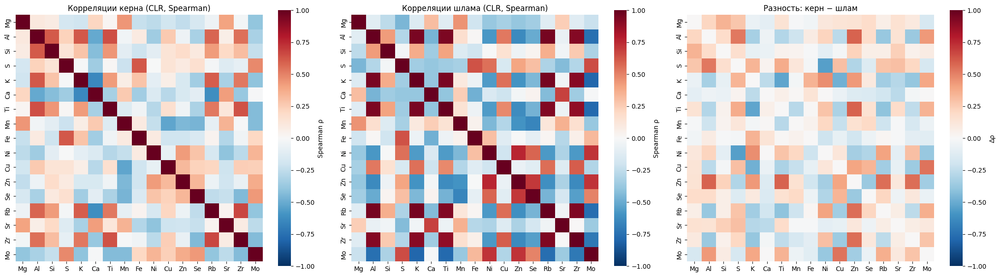

Наблюдаемая разница (норма Фробениуса): 4.2516
p-value: 0.0000
Корреляционные матрицы значимо различаются (p < 0.05).


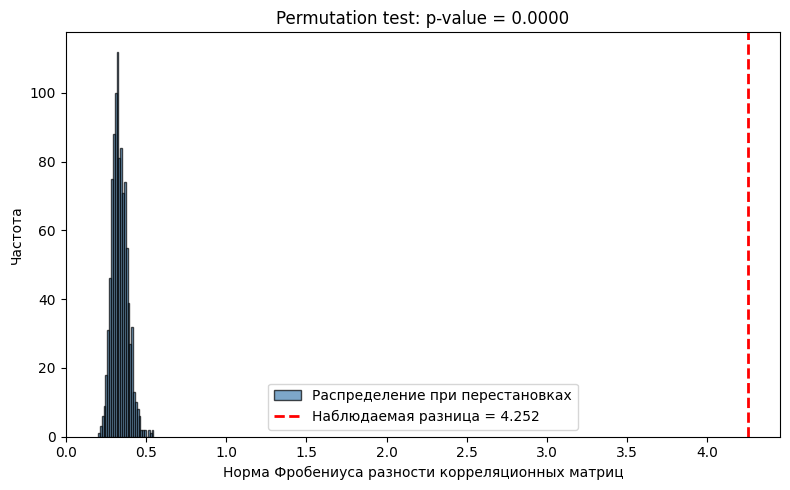


Топ-30 пар с наибольшим изменением корреляции:
 pair  corr_kern  corr_slag      diff  abs_diff
Ti–Zn  -0.039873  -0.627241  0.587368  0.587368
Al–Zn  -0.053076  -0.640184  0.587108  0.587108
Zn–Rb  -0.055014  -0.613420  0.558406  0.558406
Zn–Zr  -0.075680  -0.633129  0.557449  0.557449
 S–Ni  -0.001589   0.550182 -0.551771  0.551771
Cu–Mo   0.240037  -0.301988  0.542025  0.542025
 Al–S   0.233845  -0.295019  0.528864  0.528864
 K–Ti   0.426214   0.952055 -0.525841  0.525841
 K–Cu   0.066736   0.548723 -0.481987  0.481987
 K–Ni  -0.100010  -0.568072  0.468062  0.468062
Al–Mo  -0.320749  -0.755418  0.434669  0.434669
 K–Zn  -0.161138  -0.595448  0.434310  0.434310
Ti–Rb   0.524703   0.926348 -0.401645  0.401645
Ni–Rb  -0.170694  -0.571768  0.401074  0.401074
Cu–Zn   0.324423  -0.066590  0.391013  0.391013
 K–Zr   0.526005   0.913377 -0.387372  0.387372
 K–Mo  -0.402217  -0.789569  0.387352  0.387352
Ni–Mo   0.343220   0.721554 -0.378334  0.378334
Al–Rb   0.583958   0.960896 -0.376938  0

In [29]:
elements_pca = ['Mg', 'Al', 'Si', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe', 
                'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo']

X_kern_raw = df_kern[elements_pca].values.copy()
X_s_raw = df_filtered[elements_pca].values.copy()

# CLR-ПРЕОБРАЗОВАНИЕ (отдельно для каждой пробы)
def clr_transformation(X):
    """
    CLR для каждой пробы (строки) независимо.
    X: (n_samples, n_elements)
    Возвращает: (n_samples, n_elements) CLR-координаты
    """
    log_X = np.log(X)
    geometric_mean = np.mean(log_X, axis=1, keepdims=True)
    return log_X - geometric_mean

clr_kern = clr_transformation(X_kern_raw)
clr_slag = clr_transformation(X_s_raw)

# КОРРЕЛЯЦИОННЫЕ МАТРИЦЫ (Spearman — устойчив к выбросам)
corr_kern = pd.DataFrame(clr_kern, columns=elements_pca).corr(method='spearman')
corr_slag = pd.DataFrame(clr_slag, columns=elements_pca).corr(method='spearman')

# ВИЗУАЛИЗАЦИЯ: три heatmap
fig, axes = plt.subplots(1, 3, figsize=(22, 6))

sns.heatmap(corr_kern, ax=axes[0], cmap='RdBu_r', vmin=-1, vmax=1,
            square=True, cbar_kws={'label': 'Spearman ρ'})
axes[0].set_title('Корреляции керна (CLR, Spearman)', fontsize=12)

sns.heatmap(corr_slag, ax=axes[1], cmap='RdBu_r', vmin=-1, vmax=1,
            square=True, cbar_kws={'label': 'Spearman ρ'})
axes[1].set_title('Корреляции шлама (CLR, Spearman)', fontsize=12)

diff = corr_kern - corr_slag
sns.heatmap(diff, ax=axes[2], cmap='RdBu_r', vmin=-1, vmax=1,
            square=True, cbar_kws={'label': 'Δρ'})
axes[2].set_title('Разность: керн − шлам', fontsize=12)

plt.tight_layout()
plt.savefig('corr_comparison_kern_vs_slag.png', dpi=300, bbox_inches='tight')
plt.show()


# PERMUTATION TEST ДЛЯ СРАВНЕНИЯ КОРРЕЛЯЦИОННЫХ МАТРИЦ
def permutation_test_corr(X1, X2, n_perm=1000, method='spearman', random_state=42):
    """
    Сравнивает корреляционные матрицы двух групп через permutation test.
    
    Нулевая гипотеза: корреляционные матрицы двух групп одинаковы.
    Статистика: норма Фробениуса разности матриц.
    
    Возвращает: observed_diff, p_value, perm_diffs
    """
    rng = np.random.default_rng(random_state)
    n1, n2 = len(X1), len(X2)
    combined = np.vstack([X1, X2])
    
    # Наблюдаемая разница
    corr1 = pd.DataFrame(X1).corr(method=method).values
    corr2 = pd.DataFrame(X2).corr(method=method).values
    observed_diff = np.linalg.norm(corr1 - corr2, 'fro')
    
    # Перестановки
    perm_diffs = []
    for _ in range(n_perm):
        idx = rng.permutation(n1 + n2)
        perm1 = combined[idx[:n1]]
        perm2 = combined[idx[n1:]]
        corr_p1 = pd.DataFrame(perm1).corr(method=method).values
        corr_p2 = pd.DataFrame(perm2).corr(method=method).values
        perm_diffs.append(np.linalg.norm(corr_p1 - corr_p2, 'fro'))
    
    perm_diffs = np.array(perm_diffs)
    p_value = np.mean(perm_diffs >= observed_diff)
    return observed_diff, p_value, perm_diffs

obs_diff, p_val, perm_diffs = permutation_test_corr(clr_kern, clr_slag, n_perm=1000)

print(f"Наблюдаемая разница (норма Фробениуса): {obs_diff:.4f}")
print(f"p-value: {p_val:.4f}")
if p_val < 0.05:
    print("Корреляционные матрицы значимо различаются (p < 0.05).")
else:
    print("→Корреляционные матрицы статистически неразличимы (p ≥ 0.05).")

# ВИЗУАЛИЗАЦИЯ PERMUTATION TEST
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(perm_diffs, bins=30, color='steelblue', edgecolor='black', alpha=0.7,
        label='Распределение при перестановках')
ax.axvline(obs_diff, color='red', linestyle='--', linewidth=2,
           label=f'Наблюдаемая разница = {obs_diff:.3f}')
ax.set_xlabel('Норма Фробениуса разности корреляционных матриц')
ax.set_ylabel('Частота')
ax.set_title(f'Permutation test: p-value = {p_val:.4f}')
ax.legend()
plt.tight_layout()
plt.savefig('permutation_test_corr.png', dpi=300, bbox_inches='tight')
plt.show()


# СРАВНЕНИЕ С СИНТЕТИКОЙ
# X_syn_raw = ...  # (n_syn, n_elements)
# clr_syn = clr_transformation(X_syn_raw)
# corr_syn = pd.DataFrame(clr_syn, columns=elements_pca).corr(method='spearman')
#
# # Сравнение керн vs синтетика
# obs_syn_kern, p_syn_kern, _ = permutation_test_corr(clr_kern, clr_syn)
# # Сравнение синтетика vs шлам
# obs_syn_slag, p_syn_slag, _ = permutation_test_corr(clr_syn, clr_slag)
#
# print(f"Керн vs синтетика: p = {p_syn_kern:.4f}")
# print(f"Синтетика vs шлам: p = {p_syn_slag:.4f}")

# ТАБЛИЦА САМЫХ ИЗМЕНИВШИХСЯ ПАР ЭЛЕМЕНТОВ

def top_changed_pairs(corr1, corr2, elements, top_n=10):
    """Возвращает топ-N пар элементов с наибольшим изменением корреляции."""
    diff = corr1 - corr2
    pairs = []
    for i in range(len(elements)):
        for j in range(i + 1, len(elements)):
            pairs.append({
                'pair': f"{elements[i]}–{elements[j]}",
                'corr_kern': corr1.iloc[i, j],
                'corr_slag': corr2.iloc[i, j],
                'diff': diff.iloc[i, j],
                'abs_diff': abs(diff.iloc[i, j])
            })
    df_pairs = pd.DataFrame(pairs).sort_values('abs_diff', ascending=False)
    return df_pairs.head(top_n)

top_pairs = top_changed_pairs(corr_kern, corr_slag, elements_pca, top_n=30)
print("\nТоп-30 пар с наибольшим изменением корреляции:")
print(top_pairs.to_string(index=False))


In [32]:
def replace_nonpositive(X, eps=1e-6):
    """
    Заменяет все значения <= 0 на очень маленькое положительное число.
    Это нужно, чтобы избежать ошибки при взятии логарифма (log(0) = -inf).
    """
    X = X.copy()
    X[X <= 0] = eps
    return X

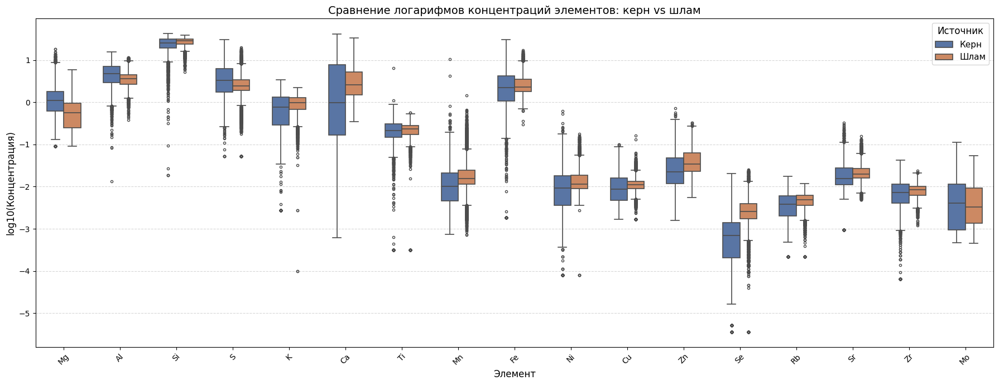

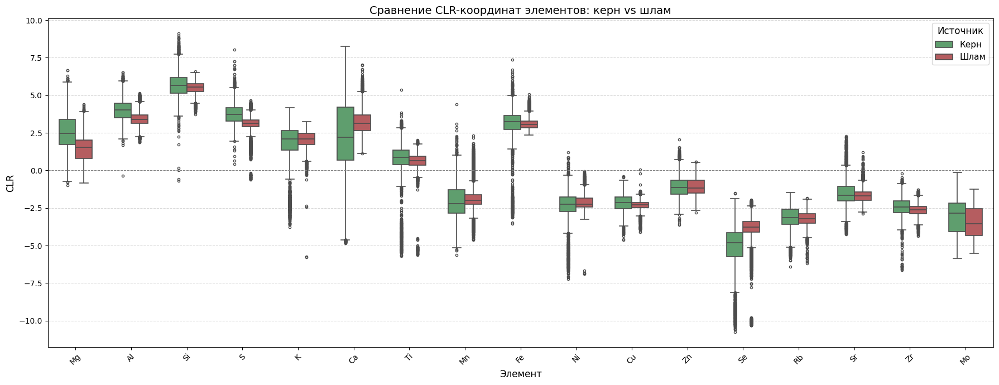

Результаты Mann-Whitney U с FDR-поправкой (по логарифмам):
Element       p_value   p_corrected  significant
     Se  0.000000e+00  0.000000e+00         True
     Mg 6.018338e-216 5.115587e-215         True
     Mn 7.782083e-146 4.409847e-145         True
     Zn 4.982404e-143 2.117522e-142         True
     Al 1.463364e-122 4.975437e-122         True
     Ni  8.781609e-99  2.488122e-98         True
     Ca  1.031226e-98  2.504407e-98         True
     Rb  8.765175e-74  1.862600e-73         True
     Sr  6.125742e-67  1.157085e-66         True
     Cu  4.265942e-57  7.252101e-57         True
      K  1.137766e-45  1.758366e-45         True
      S  3.419603e-45  4.844438e-45         True
     Si  3.910292e-43  5.113459e-43         True
     Zr  1.847351e-28  2.243212e-28         True
     Fe  8.916331e-23  1.010518e-22         True
     Ti  1.141763e-04  1.213123e-04         True
     Mo  7.554052e-03  7.554052e-03         True


In [33]:
elements_pca = ['Mg', 'Al', 'Si', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe', 
                'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo']

X_kern_raw = replace_nonpositive(df_kern[elements_pca].values.copy())
X_s_raw = replace_nonpositive(df_filtered[elements_pca].values.copy())

# ЛОГАРИФМЫ КОНЦЕНТРАЦИЙ (log10 для удобства интерпретации)
log_kern = np.log10(X_kern_raw)
log_slag = np.log10(X_s_raw)

df_log_kern = pd.DataFrame(log_kern, columns=elements_pca)
df_log_kern['Source'] = 'Керн'

df_log_slag = pd.DataFrame(log_slag, columns=elements_pca)
df_log_slag['Source'] = 'Шлам'

df_log = pd.concat([df_log_kern, df_log_slag], ignore_index=True)

# CLR-КООРДИНАТЫ (наиболее корректно для композиций)
def clr_transformation(X):
    log_X = np.log(X)
    geometric_mean = np.mean(log_X, axis=1, keepdims=True)
    return log_X - geometric_mean

clr_kern = clr_transformation(X_kern_raw)
clr_slag = clr_transformation(X_s_raw)

df_clr_kern = pd.DataFrame(clr_kern, columns=elements_pca)
df_clr_kern['Source'] = 'Керн'

df_clr_slag = pd.DataFrame(clr_slag, columns=elements_pca)
df_clr_slag['Source'] = 'Шлам'

df_clr = pd.concat([df_clr_kern, df_clr_slag], ignore_index=True)


# ВИЗУАЛИЗАЦИЯ: БОКСПЛОТЫ ЛОГАРИФМОВ
fig, ax = plt.subplots(figsize=(18, 7))

# Melt для seaborn
df_log_melt = df_log.melt(id_vars='Source', var_name='Element', value_name='log10(Концентрация)')

sns.boxplot(data=df_log_melt, x='Element', y='log10(Концентрация)', hue='Source',
            palette={'Керн': '#4C72B0', 'Шлам': '#DD8452'},
            width=0.6, linewidth=1.2, fliersize=3, ax=ax)

ax.set_title('Сравнение логарифмов концентраций элементов: керн vs шлам', fontsize=14)
ax.set_xlabel('Элемент', fontsize=12)
ax.set_ylabel('log10(Концентрация)', fontsize=12)
ax.tick_params(axis='x', rotation=45)
ax.legend(title='Источник', fontsize=11, title_fontsize=12)
ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('boxplot_log_kern_vs_slag.png', dpi=300, bbox_inches='tight')
plt.show()

# ВИЗУАЛИЗАЦИЯ: БОКСПЛОТЫ CLR-КООРДИНАТ
fig, ax = plt.subplots(figsize=(18, 7))

df_clr_melt = df_clr.melt(id_vars='Source', var_name='Element', value_name='CLR')

sns.boxplot(data=df_clr_melt, x='Element', y='CLR', hue='Source',
            palette={'Керн': '#55A868', 'Шлам': '#C44E52'},
            width=0.6, linewidth=1.2, fliersize=3, ax=ax)

ax.axhline(0, color='grey', linestyle='--', linewidth=0.8)
ax.set_title('Сравнение CLR-координат элементов: керн vs шлам', fontsize=14)
ax.set_xlabel('Элемент', fontsize=12)
ax.set_ylabel('CLR', fontsize=12)
ax.tick_params(axis='x', rotation=45)
ax.legend(title='Источник', fontsize=11, title_fontsize=12)
ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('boxplot_clr_kern_vs_slag.png', dpi=300, bbox_inches='tight')
plt.show()

# СТАТИСТИЧЕСКИЙ ТЕСТ: Mann-Whitney U с FDR

from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

results = []
for el in elements_pca:
    stat, p = mannwhitneyu(df_log_kern[el], df_log_slag[el], alternative='two-sided')
    results.append({'Element': el, 'p_value': p})

df_tests = pd.DataFrame(results)
_, pvals_corrected, _, _ = multipletests(df_tests['p_value'], method='fdr_bh')
df_tests['p_corrected'] = pvals_corrected
df_tests['significant'] = df_tests['p_corrected'] < 0.05

print("Результаты Mann-Whitney U с FDR-поправкой (по логарифмам):")
print(df_tests.sort_values('p_corrected').to_string(index=False))

Сравнение средних и медиан (в логарифмах log10):
Element  Diff_Mean_log  Diff_Median_log  Ratio_Median
     Se       0.785926         0.559340      3.625270
     Ca       0.718907         0.429859      2.690659
     Mg      -0.319021        -0.292234      0.510230
     Zn       0.187147         0.196244      1.571245
     Mn       0.295899         0.193011      1.559593
      S      -0.098640        -0.138260      0.727344
     Al      -0.083730        -0.128185      0.744415
      K       0.351374         0.116640      1.308098
     Rb       0.178958         0.107192      1.279948
     Cu       0.119652         0.105077      1.273728
     Sr       0.085138         0.104143      1.270991
     Ni       0.321181         0.093134      1.239177
     Mo       0.022287        -0.086875      0.818701
     Zr       0.109378         0.070147      1.175295
     Si       0.092998         0.049548      1.120851
     Ti       0.196939         0.039616      1.095510
     Fe       0.275296         0.

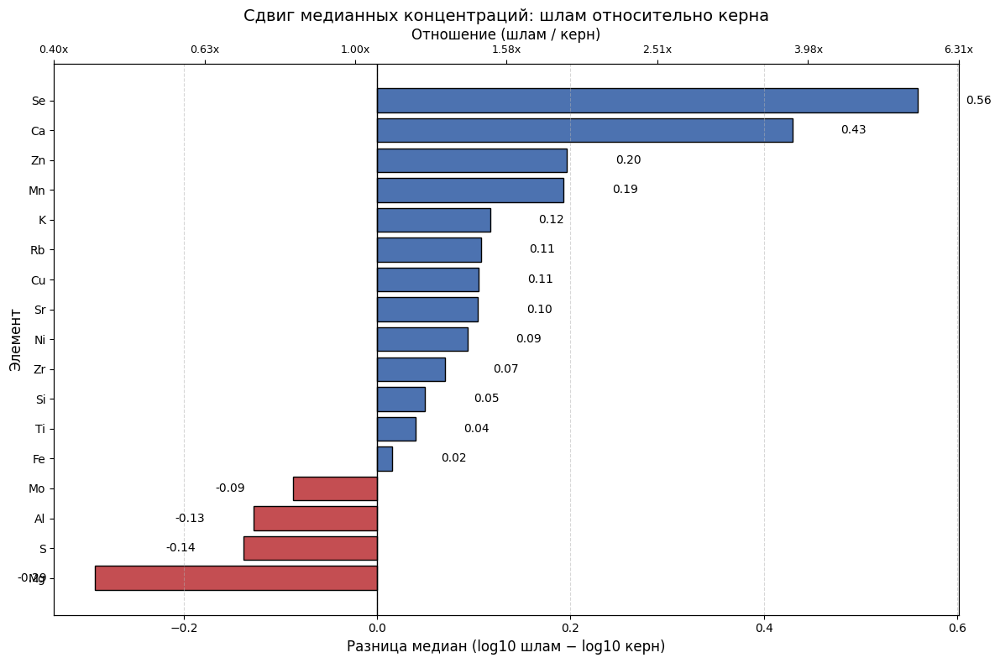

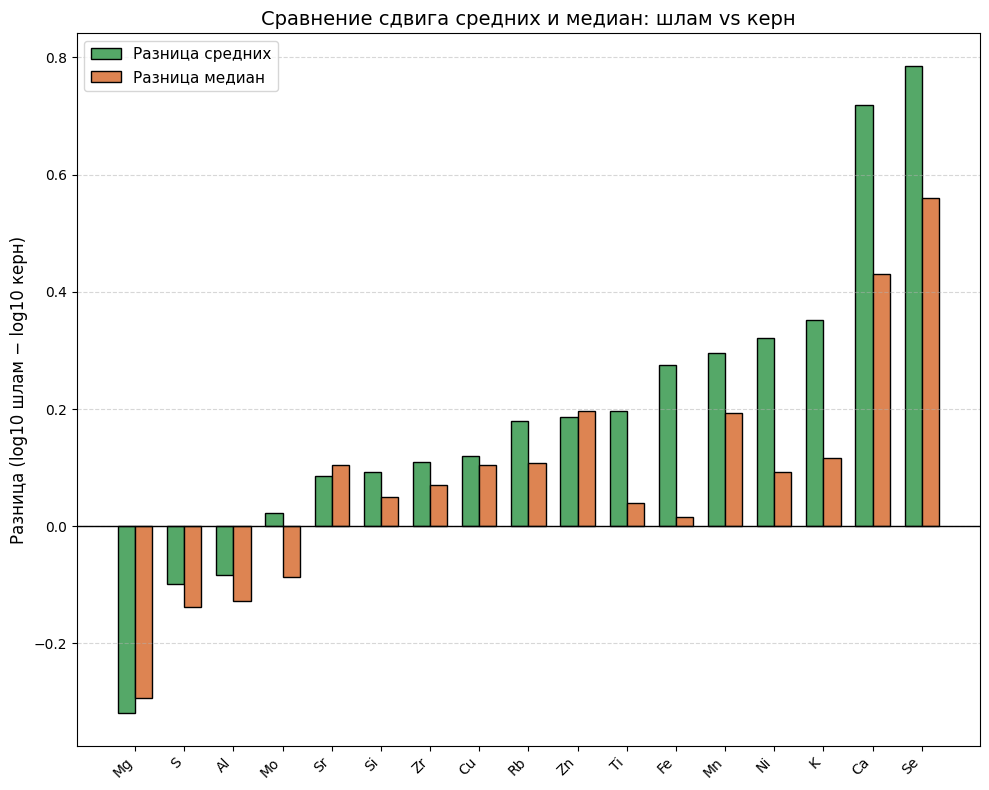

In [34]:
results = []

for el in elements_pca:
    # Данные в логарифмическом масштабе (log10)
    log_k = df_log_kern[el].dropna()
    log_s = df_log_slag[el].dropna()
    
    # Средние и медианы логарифмов
    mean_k = log_k.mean()
    mean_s = log_s.mean()
    median_k = log_k.median()
    median_s = log_s.median()
    
    # Разница (шлам минус керн)
    diff_mean = mean_s - mean_k
    diff_median = median_s - median_k
    
    # Перевод в проценты (во сколько раз): 10^diff
    # Например, diff_median = 0.3 означает, что шлам в 10^0.3 ≈ 2 раза больше
    ratio_mean = 10 ** diff_mean
    ratio_median = 10 ** diff_median
    
    results.append({
        'Element': el,
        'Mean_Kern': mean_k,
        'Mean_Slag': mean_s,
        'Diff_Mean_log': diff_mean,
        'Ratio_Mean': ratio_mean,
        'Median_Kern': median_k,
        'Median_Slag': median_s,
        'Diff_Median_log': diff_median,
        'Ratio_Median': ratio_median
    })

df_effect = pd.DataFrame(results)

# Сортируем по абсолютной разнице медиан для наглядности
df_effect['abs_diff_median'] = df_effect['Diff_Median_log'].abs()
df_effect = df_effect.sort_values('abs_diff_median', ascending=False).drop(columns='abs_diff_median')

print("Сравнение средних и медиан (в логарифмах log10):")
print(df_effect[['Element', 'Diff_Mean_log', 'Diff_Median_log', 'Ratio_Median']].to_string(index=False))

# Сохраняем в CSV для статьи
df_effect.to_csv('effect_sizes_kern_vs_slag.csv', index=False)

# 2. ВИЗУАЛИЗАЦИЯ: РАЗНИЦА МЕДИАН (В ЛОГАРИФМАХ)
fig, ax = plt.subplots(figsize=(12, 8))

# Сортируем для графика
df_plot = df_effect.sort_values('Diff_Median_log')

colors = ['#C44E52' if x < 0 else '#4C72B0' for x in df_plot['Diff_Median_log']]

bars = ax.barh(df_plot['Element'], df_plot['Diff_Median_log'], color=colors, edgecolor='black')

# Добавляем значения на столбцы
for bar, val in zip(bars, df_plot['Diff_Median_log']):
    x_pos = bar.get_width()
    ax.text(x_pos + (0.05 if x_pos >= 0 else -0.05), bar.get_y() + bar.get_height()/2, 
            f'{val:.2f}', va='center', ha='left' if x_pos >= 0 else 'right', fontsize=10)

ax.axvline(0, color='black', linewidth=1)
ax.set_xlabel('Разница медиан (log10 шлам − log10 керн)', fontsize=12)
ax.set_ylabel('Элемент', fontsize=12)
ax.set_title('Сдвиг медианных концентраций: шлам относительно керна', fontsize=14)

# Добавляем сетку
ax.grid(axis='x', linestyle='--', alpha=0.5)

# Добавляем вспомогательную ось сверху (во сколько раз)
ax2 = ax.twiny()
ax2.set_xlim(ax.get_xlim())
ax2_ticks = ax.get_xticks()
ax2.set_xticks(ax2_ticks)
ax2.set_xticklabels([f'{10**x:.2f}x' for x in ax2_ticks], fontsize=9)
ax2.set_xlabel('Отношение (шлам / керн)', fontsize=12)

plt.tight_layout()
plt.savefig('effect_size_median_shift.png', dpi=300, bbox_inches='tight')
plt.show()


# ВИЗУАЛИЗАЦИЯ: СРАВНЕНИЕ СРЕДНИХ И МЕДИАН (ТОЧЕЧНЫЙ ГРАФИК)

fig, ax = plt.subplots(figsize=(10, 8))

# Сортируем по среднему
df_plot2 = df_effect.sort_values('Diff_Mean_log')

x = np.arange(len(df_plot2))
width = 0.35

ax.bar(x - width/2, df_plot2['Diff_Mean_log'], width, label='Разница средних', color='#55A868', edgecolor='black')
ax.bar(x + width/2, df_plot2['Diff_Median_log'], width, label='Разница медиан', color='#DD8452', edgecolor='black')

ax.set_xticks(x)
ax.set_xticklabels(df_plot2['Element'], rotation=45, ha='right')
ax.axhline(0, color='black', linewidth=1)
ax.set_ylabel('Разница (log10 шлам − log10 керн)', fontsize=12)
ax.set_title('Сравнение сдвига средних и медиан: шлам vs керн', fontsize=14)
ax.legend(fontsize=11)
ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('effect_size_mean_vs_median.png', dpi=300, bbox_inches='tight')
plt.show()

In [35]:
df_kern.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3027 entries, 0 to 3026
Data columns (total 55 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Mg                        3027 non-null   float64
 1   Al                        3027 non-null   float64
 2   Si                        3027 non-null   float64
 3   P                         3027 non-null   float64
 4   S                         3027 non-null   float64
 5   K                         3027 non-null   float64
 6   Ca                        3027 non-null   float64
 7   Ti                        3027 non-null   float64
 8   Mn                        3027 non-null   float64
 9   Fe                        3027 non-null   float64
 10  Ni                        3027 non-null   float64
 11  Cu                        3027 non-null   float64
 12  Zn                        3027 non-null   float64
 13  Se                        3027 non-null   float64
 14  Rb      

In [36]:
df_kern

,Mg,Al,Si,P,S,K,Ca,Ti,Mn,Fe,...,(Al+K+Ti)/Si,(Al+K+Ti)/S,(Ti+Rb+Zr)/S,S/Ti,Ni/Al,Zn/Al,Se/Si,(Ca+Mg)/Al,Se/Ti,(10*Rb+Ti+10*Zr)/Se*1000
0,1.821148,7.515664,18.611483,0.299690,10.465318,0.942543,1.469765,0.000315,0.023969,5.472308,...,0.454479,0.808243,0.000947,33184.291859,0.000414,0.001111,7.813456e-06,0.437874,0.461110,6.620676e+05
1,1.266357,7.461183,16.904798,0.000253,14.653735,0.883390,0.000620,0.140444,0.008495,6.964299,...,0.501930,0.579034,0.010003,104.338334,0.000392,0.001638,1.897213e-05,0.169809,0.002284,6.293976e+05
2,1.724880,7.150965,18.068731,0.000253,13.442425,0.930935,0.054942,0.000315,0.022970,5.942331,...,0.447304,0.601247,0.000663,42624.348002,0.000150,0.001217,9.988526e-06,0.248892,0.572281,4.782789e+05
3,1.646439,8.260792,21.260196,0.000253,10.257598,1.235161,0.000620,0.184038,0.014205,4.126949,...,0.455311,0.943690,0.018802,55.736303,0.000451,0.001071,8.489103e-06,0.199383,0.000981,1.508714e+06
4,1.847176,7.757235,19.837340,0.000253,10.623499,1.059210,0.478515,0.000315,0.022656,5.052294,...,0.444453,0.829930,0.000674,33685.867876,0.000401,0.001747,1.440012e-05,0.299809,0.905794,2.406468e+05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3022,2.129802,4.410461,8.497462,1.992644,10.053492,0.514109,4.325427,0.000315,0.107449,13.178634,...,0.579571,0.489868,0.000524,31878.441397,0.000222,0.001368,4.160694e-07,1.463618,0.011211,1.408511e+07
3023,1.863934,12.555305,24.545034,0.084607,1.785869,1.701369,0.058194,0.397704,0.020486,2.164767,...,0.597040,8.205742,0.230496,4.490447,0.000044,0.000716,1.440427e-07,0.153093,0.000009,1.518913e+08
3024,1.705032,12.769895,24.812063,0.000253,1.558093,1.863352,0.000620,0.397608,0.020115,2.041525,...,0.605788,9.646959,0.264159,3.918661,0.000062,0.000676,1.424925e-07,0.133568,0.000009,1.519910e+08
3025,1.680073,12.810209,25.421817,0.038680,1.082697,1.895027,0.000620,0.408698,0.014690,1.656151,...,0.594526,13.959528,0.391753,2.649136,0.000047,0.000641,1.390748e-07,0.131200,0.000009,1.593009e+08


In [37]:
df_filtered

,Mg,Al,Si,P,S,K,Ca,Ti,Mn,Fe,...,(Al+K+Ti)/Si,(Al+K+Ti)/S,(Ti+Rb+Zr)/S,S/Ti,Ni/Al,Zn/Al,Se/Si,(Ca+Mg)/Al,Se/Ti,(10*Rb+Ti+10*Zr)/Se*1000
0,1.633068,8.473423,20.276745,0.260095,0.646682,1.429253,2.271782,0.404823,0.042342,7.315714,...,0.508341,15.939043,0.667905,1.597445,0.000660,0.002057,4.438582e-05,0.460835,0.002223,7.509068e+05
1,1.582932,8.230786,19.558397,0.235244,0.717571,1.405148,3.129859,0.396280,0.038844,7.212908,...,0.512936,13.980793,0.588291,1.810768,0.000608,0.002147,2.045157e-05,0.572581,0.001009,1.637220e+06
2,1.501035,7.912201,19.137236,0.239178,0.880392,1.390252,3.811154,0.389325,0.040521,6.974907,...,0.506436,11.008485,0.471647,2.261326,0.000854,0.002406,1.847463e-07,0.671392,0.000009,1.833987e+08
3,1.388715,8.601034,19.682370,0.272472,0.579918,1.437040,2.518553,0.401560,0.044145,7.445750,...,0.530405,18.001901,0.739973,1.444162,0.000804,0.001920,1.796295e-07,0.454279,0.000009,1.915400e+08
4,1.249136,8.902730,20.359426,0.279381,0.498194,1.493036,2.097046,0.398255,0.041284,7.271689,...,0.530173,21.666316,0.853171,1.250942,0.000933,0.001954,1.964692e-05,0.375860,0.001004,1.665370e+06
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8638,0.853000,3.526420,26.702723,0.170925,2.501228,0.879375,5.221831,0.215257,0.022370,2.165175,...,0.173055,1.847513,0.091125,11.619716,0.003102,0.010387,1.351592e-04,1.722662,0.016767,9.473970e+04
8639,0.371300,3.359940,27.947829,0.190394,2.591162,0.865338,4.837500,0.222337,0.017747,1.900205,...,0.159140,1.716455,0.090315,11.654229,0.003737,0.009459,1.578563e-04,1.550266,0.019843,7.688219e+04
8640,0.363700,3.319123,27.412331,0.186870,2.573861,0.821233,4.771904,0.225783,0.018030,1.842603,...,0.159276,1.696338,0.092643,11.399701,0.003066,0.009089,1.469973e-04,1.547277,0.017847,8.746728e+04
8641,0.319500,3.252488,29.058218,0.392234,2.511021,0.791165,3.544972,0.184518,0.015671,1.856484,...,0.145507,1.683845,0.078009,13.608562,0.004043,0.013013,1.689230e-04,1.188159,0.026602,6.074370e+04


**Реализация Copula**

In [38]:
df_slag = df_filtered.copy()

**Обычная копула**

In [39]:
elements = ['Mg', 'Al', 'Si', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe', 
            'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo']

X_kern_raw = df_kern[elements].values
X_slag_raw = df_slag[elements].values


def clr_transform(X):
    """CLR-преобразование (безопасное для нулей)."""
    X = np.where(X <= 0, 1e-6, X) 
    log_X = np.log(X)
    return log_X - np.mean(log_X, axis=1, keepdims=True)

# def inverse_clr(clr_data):
#    """Обратное CLR-преобразование в проценты (сумма = 100)."""
#   exp_data = np.exp(clr_data)
#    return exp_data / np.sum(exp_data, axis=1, keepdims=True) * 100 


def inverse_clr_preserve_scale(clr_data, reference_df, elements):
    """
    Обратное CLR-преобразование с сохранением оригинального масштаба.
    clr_data: сгенерированные CLR-координаты
    reference_df: датафрейм, из которого берутся медианы для масштабирования (например, df_slag)
    elements: список колонок
    """
    # 1. Стандартное обратное преобразование (получаем пропорции)
    exp_data = np.exp(clr_data)
    proportions = exp_data / np.sum(exp_data, axis=1, keepdims=True)
    
    # 2. Считаем медианы реальных данных для каждого элемента
    # (лучше брать шлам, так как мы подгоняем синтетику под него)
    ref_medians = reference_df[elements].median().values
    
    # 3. Масштабируем пропорции так, чтобы медиана каждого элемента 
    scaled_data = proportions * ref_medians
    
    return scaled_data




# ОЧИСТКА ВЫБРОСОВ В CLR-ПРОСТРАНСТВЕ

# Переводим шлам в CLR
clr_slag_raw = clr_transform(X_slag_raw)

# Обрезаем выбросы по 1% и 99% перцентилям в CLR
clr_slag_clean = clr_slag_raw.copy()
for i in range(clr_slag_clean.shape[1]):
    lower_bound = np.percentile(clr_slag_clean[:, i], 1)
    upper_bound = np.percentile(clr_slag_clean[:, i], 99)
    clr_slag_clean[:, i] = np.clip(clr_slag_clean[:, i], lower_bound, upper_bound)

# Керн переводим в CLR (он без выбросов)
clr_kern = clr_transform(X_kern_raw)


# 3. ГЕНЕРАЦИЯ СИНТЕТИКИ ЧЕРЕЗ COPULA
# 3.1. Структура (корреляция) из КЕРНА
cov_kern = EmpiricalCovariance().fit(clr_kern)
corr_matrix_kern = cov_kern.covariance_ 

# 3.2. Маргиналы (отсортированные значения) из ОЧИЩЕННОГО ШЛАМА
sorted_clr_slag = np.sort(clr_slag_clean, axis=0) 
n_slag = len(clr_slag_clean)

# 3.3. Генерация
n_synthetic = len(clr_kern) # Генерируем столько же проб, сколько в керне
np.random.seed(42)

# Многомерный нормальный шум с корреляцией керна
latent_normal = np.random.multivariate_normal(
    mean=np.zeros(len(elements)), 
    cov=corr_matrix_kern, 
    size=n_synthetic
)

# Перевод в равномерное [0,1]
latent_uniform = norm.cdf(latent_normal)

# Применяем обратную CDF шлама
clr_synthetic = np.zeros_like(latent_uniform)
for i in range(len(elements)):
    indices = (latent_uniform[:, i] * (n_slag - 1)).astype(int)
    clr_synthetic[:, i] = sorted_clr_slag[indices, i]


# ВОЗВРАТ В КОНЦЕНТРАЦИИ
# X_synthetic = inverse_clr(clr_synthetic)

X_synthetic = inverse_clr_preserve_scale(clr_synthetic, df_slag, elements)
df_synthetic_base = pd.DataFrame(X_synthetic, columns=elements)

print(f"Размер: {df_synthetic_base.shape}")

metadata_cols = ['Well', 'Depth', 'Sample', 'Strat'] 

df_metadata = df_kern[metadata_cols].reset_index(drop=True)
df_synthetic_full = pd.concat([df_synthetic_base, df_metadata], axis=1)

Размер: (3027, 17)


**Условная копула**

In [40]:
import numpy as np
import pandas as pd
from scipy.stats import norm
from sklearn.covariance import EmpiricalCovariance
from catboost import CatBoostClassifier
from sklearn.metrics import f1_score, classification_report
import warnings
warnings.filterwarnings('ignore')

# =====================================================================
# 0. ПОДГОТОВКА
# =====================================================================
elements = ['Mg', 'Al', 'Si', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe', 
            'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo']

# Предполагается, что df_kern и df_slag уже загружены.
# Убедимся, что в df_kern есть колонка 'Strat' (метка пачки).
if 'Strat' not in df_kern.columns:
    raise ValueError("В df_kern нет колонки 'Strat'!")

X_kern_raw = df_kern[elements].values
X_slag_raw = df_slag[elements].values

def clr_transform(X):
    """CLR-преобразование (безопасное для нулей)."""
    X = np.where(X <= 0, 1e-6, X) 
    log_X = np.log(X)
    return log_X - np.mean(log_X, axis=1, keepdims=True)




def inverse_clr_correct_scale(clr_data, reference_df, elements):
    """
    Правильное обратное CLR с точной подгонкой медиан под реальный шлам.
    """
    # 1. Стандартное обратное CLR (получаем проценты, сумма = 100)
    exp_data = np.exp(clr_data)
    proportions = exp_data / np.sum(exp_data, axis=1, keepdims=True) * 100 
    
    # 2. Считаем медианы
    ref_medians = reference_df[elements].median().values
    synth_medians = np.median(proportions, axis=0)
    
    # 3. Считаем коэффициент масштабирования для каждого элемента
    scale_factors = np.where(synth_medians > 0, ref_medians / synth_medians, 1.0)
    
    # 4. Умножаем на коэффициенты
    scaled_data = proportions * scale_factors
    
    return scaled_data


# =====================================================================
# 1. ОЧИСТКА ВЫБРОСОВ В CLR (для шлама)
# =====================================================================
clr_slag_raw = clr_transform(X_slag_raw)
clr_slag_clean = clr_slag_raw.copy()
for i in range(clr_slag_clean.shape[1]):
    lower_bound = np.percentile(clr_slag_clean[:, i], 1)
    upper_bound = np.percentile(clr_slag_clean[:, i], 99)
    clr_slag_clean[:, i] = np.clip(clr_slag_clean[:, i], lower_bound, upper_bound)

# Общие маргиналы шлама (если для класса нет своих данных, используем эти)
sorted_clr_slag_all = np.sort(clr_slag_clean, axis=0)
n_slag_all = len(clr_slag_clean)

# =====================================================================
# 2. УСЛОВНАЯ ГЕНЕРАЦИЯ (ОТДЕЛЬНО ДЛЯ КАЖДОГО КЛАССА)
# =====================================================================
df_synthetic_list = []
unique_classes = df_kern['Strat'].unique()

print(f"Найдено классов в керне: {len(unique_classes)}")

for strat_class in unique_classes:
    # 2.1. Данные керна для этого класса
    mask_kern = df_kern['Strat'] == strat_class
    if mask_kern.sum() < 5: # Пропускаем слишком маленькие классы
        print(f"Класс {strat_class}: пропущен (мало проб: {mask_kern.sum()})")
        continue
        
    clr_kern_class = clr_transform(df_kern.loc[mask_kern, elements].values)
    
    # 2.2. Данные шлама для этого класса (если есть метки)
    if 'Strat' in df_slag.columns:
        mask_slag = df_slag['Strat'] == strat_class
        if mask_slag.sum() > 5:
            # Есть свои пробы шлама для этого класса — берем их CDF
            clr_slag_class = clr_transform(df_slag.loc[mask_slag, elements].values)
            sorted_clr_slag_class = np.sort(clr_slag_class, axis=0)
            n_slag_class = len(clr_slag_class)
        else:
            # Нет своих проб — используем общие CDF шлама
            sorted_clr_slag_class = sorted_clr_slag_all
            n_slag_class = n_slag_all
    else:
        # В шламе нет меток — используем общие CDF
        sorted_clr_slag_class = sorted_clr_slag_all
        n_slag_class = n_slag_all
    
    # 2.3. Структура (корреляция) из КЕРНА этого класса
    cov_kern_class = EmpiricalCovariance().fit(clr_kern_class)
    corr_matrix_kern_class = cov_kern_class.covariance_
    
    # 2.4. Генерация
    n_synth_class = mask_kern.sum() # Генерируем столько же, сколько в керне
    np.random.seed(42 + hash(strat_class) % 1000) # Разный seed для разных классов
    
    latent_normal = np.random.multivariate_normal(
        mean=np.zeros(len(elements)), 
        cov=corr_matrix_kern_class, 
        size=n_synth_class
    )
    latent_uniform = norm.cdf(latent_normal)
    
    clr_synth_class = np.zeros_like(latent_uniform)
    for i in range(len(elements)):
        indices = (latent_uniform[:, i] * (n_slag_class - 1)).astype(int)
        clr_synth_class[:, i] = sorted_clr_slag_class[indices, i]
        
    # 2.5. Возврат в концентрации
   
    X_synth_class = inverse_clr_correct_scale(clr_synth_class, df_slag, elements)
    df_class = pd.DataFrame(X_synth_class, columns=elements)
    
    # 2.6. Добавляем метаданные (метку и глубину)
    # Для глубины берем значения из керна этого класса
    df_class['Strat'] = strat_class
    df_class['Depth'] = df_kern.loc[mask_kern, 'Depth'].values
    df_class['Well'] = 'SYNTHETIC'
    df_class['Sample'] = [f'SYN_{strat_class}_{i}' for i in range(n_synth_class)]
    
    df_synthetic_list.append(df_class)
    print(f"Класс {strat_class}: сгенерировано {n_synth_class} проб")

# Объединяем все классы
df_synthetic_full = pd.concat(df_synthetic_list, ignore_index=True)

# Сортируем по глубине (чтобы dΔ имели хоть какой-то смысл)
df_synthetic_full = df_synthetic_full.sort_values('Depth').reset_index(drop=True)

print(f"\nИтоговый размер синтетики: {df_synthetic_full.shape}")
print("\nБаланс классов (Керн vs Синтетика):")
print("Керн:")
print(df_kern['Strat'].value_counts(normalize=True).round(3))
print("Синтетика:")
print(df_synthetic_full['Strat'].value_counts(normalize=True).round(3))

# =====================================================================
# 3. ПРОВЕРКА МАСШТАБА
# =====================================================================
print("\nСравнение медиан (Синтетика vs Реальный шлам):")
for el in ['Ca', 'Fe', 'K']:
    print(f"{el}: Синтетика = {df_synthetic_full[el].median():.2f}, Шлам = {df_slag[el].median():.2f}")

Найдено классов в керне: 12
Класс 11: сгенерировано 183 проб
Класс 10: сгенерировано 267 проб
Класс 9: сгенерировано 469 проб
Класс 8: сгенерировано 365 проб
Класс 7: сгенерировано 194 проб
Класс 6: сгенерировано 131 проб
Класс 5: сгенерировано 133 проб
Класс 4: сгенерировано 232 проб
Класс 3: сгенерировано 267 проб
Класс 2: сгенерировано 182 проб
Класс 1: сгенерировано 156 проб
Класс 0: сгенерировано 448 проб

Итоговый размер синтетики: (3027, 21)

Баланс классов (Керн vs Синтетика):
Керн:
Strat
9     0.155
0     0.148
8     0.121
10    0.088
3     0.088
4     0.077
7     0.064
11    0.060
2     0.060
1     0.052
5     0.044
6     0.043
Name: proportion, dtype: float64
Синтетика:
Strat
9     0.155
0     0.148
8     0.121
10    0.088
3     0.088
4     0.077
7     0.064
11    0.060
2     0.060
1     0.052
5     0.044
6     0.043
Name: proportion, dtype: float64

Сравнение медиан (Синтетика vs Реальный шлам):
Ca: Синтетика = 2.60, Шлам = 2.60
Fe: Синтетика = 2.29, Шлам = 2.29
K: Синтетик

In [41]:
df_synthetic_full

,Mg,Al,Si,S,K,Ca,Ti,Mn,Fe,Ni,...,Zn,Se,Rb,Sr,Zr,Mo,Strat,Depth,Well,Sample
0,1.064903,4.619074,28.791190,3.084685,1.419184,0.765617,0.235095,0.034771,3.087103,0.013511,...,0.033572,0.004072,0.004638,0.025739,0.010705,0.007657,11,2643.28,SYNTHETIC,SYN_11_163
1,0.141950,3.173348,25.757388,1.995149,0.887556,8.497661,0.463567,0.016106,2.222213,0.006551,...,0.023030,0.001913,0.003611,0.018443,0.007526,0.004261,11,2643.46,SYNTHETIC,SYN_11_164
2,0.212355,4.148854,29.163978,2.707901,1.060582,3.089414,0.120778,0.023512,2.491073,0.011159,...,0.027995,0.002929,0.005005,0.020023,0.008651,0.006331,11,2643.89,SYNTHETIC,SYN_11_165
3,0.651976,3.415502,32.538267,1.887549,1.363094,1.328286,0.092656,0.013097,1.775911,0.032681,...,0.037926,0.011614,0.005869,0.012461,0.007547,0.001309,11,2644.13,SYNTHETIC,SYN_11_166
4,0.684556,4.242884,28.318458,2.817083,1.084799,2.832273,0.070561,0.018522,2.978125,0.014897,...,0.037233,0.003127,0.004848,0.025419,0.008866,0.007062,11,2644.45,SYNTHETIC,SYN_11_167
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3022,0.788178,4.233338,27.709939,4.033643,1.474734,2.888607,0.876922,0.014668,3.921971,0.045675,...,0.035721,0.002552,0.008910,0.024959,0.013306,0.005956,2,2967.50,SYNTHETIC,SYN_2_123
3023,0.501821,4.762550,32.897678,2.162408,1.241843,1.060853,0.503744,0.014453,1.723057,0.009689,...,0.040916,0.001484,0.006833,0.032300,0.011735,0.003399,2,2967.67,SYNTHETIC,SYN_2_124
3024,0.397305,2.369644,18.628982,1.919445,0.172476,32.064104,0.149461,0.057640,1.484340,0.016441,...,0.048861,0.001593,0.003737,0.019861,0.007475,0.003856,2,2967.96,SYNTHETIC,SYN_2_125
3025,0.062784,4.383832,33.137940,2.136586,1.771810,0.912441,0.525360,0.009120,1.875749,0.010370,...,0.023252,0.002815,0.002696,0.014257,0.009021,0.002290,2,2968.20,SYNTHETIC,SYN_2_126


**Еще вариант. Условная Копула**

In [42]:
import numpy as np
import pandas as pd
from scipy.stats import norm
from sklearn.covariance import EmpiricalCovariance

elements = ['Mg', 'Al', 'Si', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe', 
            'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo']

# Определяем, как называется колонка с метками в шламе
slag_target_col = None
if 'Strat' in df_slag.columns:
    slag_target_col = 'Strat'
elif 'Stratigraphy' in df_slag.columns:
    slag_target_col = 'Stratigraphy'
else:
    print("ВНИМАНИЕ: В df_slag нет колонки с метками ('Strat' или 'Stratigraphy'). Будут использоваться общие CDF шлама.")

X_kern_raw = df_kern[elements].values
X_slag_raw = df_slag[elements].values

def clr_transform(X):
    X = np.where(X <= 0, 1e-6, X) 
    log_X = np.log(X)
    return log_X - np.mean(log_X, axis=1, keepdims=True)

def inverse_clr_class_scale(clr_data, reference_slag_df, kern_class_df, kern_all_df, elements):
    """
    Обратное CLR с масштабированием по классам.
    Подгоняет медианы синтетики под (Медиана шлама * (Медиана класса в керне / Общая медиана керна)).
    """
    exp_data = np.exp(clr_data)
    proportions = exp_data / np.sum(exp_data, axis=1, keepdims=True) * 100 
    
    slag_medians = reference_slag_df[elements].median().values
    kern_class_medians = kern_class_df[elements].median().values
    kern_all_medians = kern_all_df[elements].median().values 
    
    # Защита от деления на ноль
    ratio = np.where(kern_all_medians > 0, kern_class_medians / kern_all_medians, 1.0)
    target_medians = slag_medians * ratio
    
    synth_medians = np.median(proportions, axis=0)
    scale_factors = np.where(synth_medians > 0, target_medians / synth_medians, 1.0)
    
    return proportions * scale_factors

# ОЧИСТКА ВЫБРОСОВ В CLR (для шлама)

clr_slag_raw = clr_transform(X_slag_raw)
clr_slag_clean = clr_slag_raw.copy()
for i in range(clr_slag_clean.shape[1]):
    lower_bound = np.percentile(clr_slag_clean[:, i], 1)
    upper_bound = np.percentile(clr_slag_clean[:, i], 99)
    clr_slag_clean[:, i] = np.clip(clr_slag_clean[:, i], lower_bound, upper_bound)

sorted_clr_slag_all = np.sort(clr_slag_clean, axis=0)
n_slag_all = len(clr_slag_clean)

# УСЛОВНАЯ ГЕНЕРАЦИЯ
df_synthetic_list = []
unique_classes = df_kern['Strat'].unique()

print(f"Найдено классов в керне: {len(unique_classes)}")
if slag_target_col:
    print(f"Метки в шламе берутся из колонки: '{slag_target_col}'")
else:
    print("Метки в шламе не найдены. Используются общие CDF.")

for strat_class in unique_classes:
    mask_kern = df_kern['Strat'] == strat_class
    if mask_kern.sum() < 5: 
        continue
        
    clr_kern_class = clr_transform(df_kern.loc[mask_kern, elements].values)
    kern_class_df = df_kern.loc[mask_kern] 
    
    # Проверяем наличие проб шлама для этого класса
    if slag_target_col:
        mask_slag = df_slag[slag_target_col] == strat_class
        if mask_slag.sum() > 5:
            clr_slag_class = clr_transform(df_slag.loc[mask_slag, elements].values)
            sorted_clr_slag_class = np.sort(clr_slag_class, axis=0)
            n_slag_class = len(clr_slag_class)
        else:
            sorted_clr_slag_class = sorted_clr_slag_all
            n_slag_class = n_slag_all
    else:
        sorted_clr_slag_class = sorted_clr_slag_all
        n_slag_class = n_slag_all
    
    cov_kern_class = EmpiricalCovariance().fit(clr_kern_class)
    corr_matrix_kern_class = cov_kern_class.covariance_
    
    n_synth_class = mask_kern.sum() 
    np.random.seed(42 + hash(strat_class) % 1000) 
    
    latent_normal = np.random.multivariate_normal(
        mean=np.zeros(len(elements)), 
        cov=corr_matrix_kern_class, 
        size=n_synth_class
    )
    latent_uniform = norm.cdf(latent_normal)
    
    clr_synth_class = np.zeros_like(latent_uniform)
    for i in range(len(elements)):
        indices = (latent_uniform[:, i] * (n_slag_class - 1)).astype(int)
        clr_synth_class[:, i] = sorted_clr_slag_class[indices, i]
        
    # Масштабируем с учетом класса
    X_synth_class = inverse_clr_class_scale(clr_synth_class, df_slag, kern_class_df, df_kern, elements)
    
    df_class = pd.DataFrame(X_synth_class, columns=elements)
    df_class['Strat'] = strat_class
    df_class['Depth'] = df_kern.loc[mask_kern, 'Depth'].values
    df_class['Well'] = 'SYNTHETIC'
    df_class['Sample'] = [f'SYN_{strat_class}_{i}' for i in range(n_synth_class)]
    
    df_synthetic_list.append(df_class)

df_synthetic_full = pd.concat(df_synthetic_list, ignore_index=True)
df_synthetic_full = df_synthetic_full.sort_values('Depth').reset_index(drop=True)

print(f"Синтетика создана. Размер: {df_synthetic_full.shape}")

Найдено классов в керне: 12
Метки в шламе берутся из колонки: 'Stratigraphy'
Синтетика создана. Размер: (3027, 21)


**ГЕНЕРАЦИЯ ПРОИЗВОДНЫХ ПРИЗНАКОВ (СООТНОШЕНИЙ)**

In [43]:
elements = ['Mg', 'Al', 'Si', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe',
            'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo']

ratios = [
    '(Ca+Mg)/(Al+Si)', 'Sr/Ca', 'Mn/Ca', '(Al+K)/(Ca+Mg+Si)', 'Zr/Al',
    'Zr/Si', 'K/Al', 'Ti/(Zr+Ti)', 'Si/Al', 'Ni/Fe',
    'Ni/(Si+Ca+Mg)', 'S/(Rb+Zr)', 'Mo/Al', 'Mo/(Mn+Mo)', 'Mn/Al',
    'Fe/S', 'Ni/S', 'Fe/(Ca+Mg+Al)', 'Ti/(Si+Ca+Mg)', 'Fe/(Mn+Fe)',
    '(Al+K+Ti)/Si', '(Al+K+Ti)/S', '(Ti+Rb+Zr)/S', 'S/Ti', 'Ni/Al',
    'Zn/Al', 'Se/Si', '(Ca+Mg)/Al', 'Se/Ti', '(10*Rb+Ti+10*Zr)/Se*1000'
]

def compute_ratios(df, elements, ratios):
    df = df.copy()
    df['(Ca+Mg)/(Al+Si)'] = (df['Ca'] + df['Mg']) / (df['Al'] + df['Si'] + 1e-6)
    df['Sr/Ca'] = df['Sr'] / (df['Ca'] + 1e-6)
    df['Mn/Ca'] = df['Mn'] / (df['Ca'] + 1e-6)
    df['(Al+K)/(Ca+Mg+Si)'] = (df['Al'] + df['K']) / (df['Ca'] + df['Mg'] + df['Si'] + 1e-6)
    df['Zr/Al'] = df['Zr'] / (df['Al'] + 1e-6)
    df['Zr/Si'] = df['Zr'] / (df['Si'] + 1e-6)
    df['K/Al'] = df['K'] / (df['Al'] + 1e-6)
    df['Ti/(Zr+Ti)'] = df['Ti'] / (df['Zr'] + df['Ti'] + 1e-6)
    df['Si/Al'] = df['Si'] / (df['Al'] + 1e-6)
    df['Ni/Fe'] = df['Ni'] / (df['Fe'] + 1e-6)
    df['Ni/(Si+Ca+Mg)'] = df['Ni'] / (df['Si'] + df['Ca'] + df['Mg'] + 1e-6)
    df['S/(Rb+Zr)'] = df['S'] / (df['Rb'] + df['Zr'] + 1e-6)
    df['Mo/Al'] = df['Mo'] / (df['Al'] + 1e-6)
    df['Mo/(Mn+Mo)'] = df['Mo'] / (df['Mn'] + df['Mo'] + 1e-6)
    df['Mn/Al'] = df['Mn'] / (df['Al'] + 1e-6)
    df['Fe/S'] = df['Fe'] / (df['S'] + 1e-6)
    df['Ni/S'] = df['Ni'] / (df['S'] + 1e-6)
    df['Fe/(Ca+Mg+Al)'] = df['Fe'] / (df['Ca'] + df['Mg'] + df['Al'] + 1e-6)
    df['Ti/(Si+Ca+Mg)'] = df['Ti'] / (df['Si'] + df['Ca'] + df['Mg'] + 1e-6)
    df['Fe/(Mn+Fe)'] = df['Fe'] / (df['Mn'] + df['Fe'] + 1e-6)
    df['(Al+K+Ti)/Si'] = (df['Al'] + df['K'] + df['Ti']) / (df['Si'] + 1e-6)
    df['(Al+K+Ti)/S'] = (df['Al'] + df['K'] + df['Ti']) / (df['S'] + 1e-6)
    df['(Ti+Rb+Zr)/S'] = (df['Ti'] + df['Rb'] + df['Zr']) / (df['S'] + 1e-6)
    df['S/Ti'] = df['S'] / (df['Ti'] + 1e-6)
    df['Ni/Al'] = df['Ni'] / (df['Al'] + 1e-6)
    df['Zn/Al'] = df['Zn'] / (df['Al'] + 1e-6)
    df['Se/Si'] = df['Se'] / (df['Si'] + 1e-6)
    df['(Ca+Mg)/Al'] = (df['Ca'] + df['Mg']) / (df['Al'] + 1e-6)
    df['Se/Ti'] = df['Se'] / (df['Ti'] + 1e-6)
    df['(10*Rb+Ti+10*Zr)/Se*1000'] = (10*df['Rb'] + df['Ti'] + 10*df['Zr']) / (df['Se'] + 1e-6) * 1000
    return df

df_synthetic_full = compute_ratios(df_synthetic_full, elements, ratios)    

In [44]:
df_synthetic_full

,Mg,Al,Si,S,K,Ca,Ti,Mn,Fe,Ni,...,(Al+K+Ti)/Si,(Al+K+Ti)/S,(Ti+Rb+Zr)/S,S/Ti,Ni/Al,Zn/Al,Se/Si,(Ca+Mg)/Al,Se/Ti,(10*Rb+Ti+10*Zr)/Se*1000
0,1.091909,6.381997,18.326895,10.288631,1.524338,0.293661,0.219877,0.044018,8.172274,0.008794,...,0.443404,0.789824,0.022831,46.792345,0.001378,0.003717,0.000182,0.217106,0.015175,110895.790824
1,0.439910,5.600538,19.516432,6.030173,1.259999,1.898238,0.405708,0.027921,7.447792,0.005459,...,0.372314,1.204981,0.069586,14.863282,0.000975,0.003776,0.000045,0.417486,0.002166,619233.533610
2,0.454657,6.077041,19.121927,18.530787,1.293753,1.005541,0.129312,0.035216,7.274845,0.007927,...,0.392225,0.404738,0.007771,143.302017,0.001304,0.003527,0.000123,0.240281,0.018191,117376.531576
3,0.826353,5.415891,22.034069,4.345009,1.585255,0.647927,0.126418,0.012637,6.021060,0.011778,...,0.323479,1.640402,0.032388,34.369976,0.002175,0.004612,0.000763,0.272214,0.133072,16018.084509
4,0.814456,6.172642,18.771751,9.698516,1.307228,0.992437,0.092461,0.026179,8.095642,0.009169,...,0.403390,0.780772,0.011052,104.892397,0.001485,0.004031,0.000127,0.292726,0.025880,100154.970584
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3022,0.428387,2.813955,36.408464,1.489377,1.066188,0.493753,0.267975,0.012361,1.303514,0.009453,...,0.113933,2.785134,0.188726,5.557871,0.003359,0.007851,0.000026,0.327702,0.003563,417522.950494
3023,0.342235,2.757096,39.278574,1.099066,0.937439,0.310840,0.215608,0.012095,0.870392,0.005341,...,0.099549,3.557692,0.206745,5.097490,0.001937,0.007473,0.000019,0.236870,0.003421,449242.686290
3024,0.354790,2.599798,36.329451,1.257069,0.662529,1.829383,0.190380,0.028800,0.980745,0.007915,...,0.095039,2.746630,0.161007,6.602917,0.003044,0.009725,0.000026,0.840132,0.004925,330842.262846
3025,0.095723,2.618658,39.741841,1.081601,0.981069,0.272048,0.208163,0.009756,0.916559,0.005721,...,0.095816,3.520603,0.201516,5.195895,0.002185,0.006693,0.000028,0.140442,0.005265,279063.613334


In [45]:
features = [
    'Mg', 'Al', 'Si', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe',
    'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo',
    '(Ca+Mg)/(Al+Si)',
    'Sr/Ca',
    'Mn/Ca',
    '(Al+K)/(Ca+Mg+Si)',
    'Zr/Al',
    'Zr/Si',
    'K/Al',
    'Ti/(Zr+Ti)',
    'Si/Al',
    'Ni/Fe',
    'Ni/(Si+Ca+Mg)',
    'S/(Rb+Zr)',
    'Mo/Al',
    'Mo/(Mn+Mo)',
    'Mn/Al',
    'Fe/S',
    'Ni/S',
    'Fe/(Ca+Mg+Al)',
    'Ti/(Si+Ca+Mg)',
    'Fe/(Mn+Fe)',
    '(Al+K+Ti)/Si',
    '(Al+K+Ti)/S',
    '(Ti+Rb+Zr)/S',
    'S/Ti',
    'Ni/Al',
    'Zn/Al',
    'Se/Si',
    '(Ca+Mg)/Al',
    'Se/Ti',
    '(10*Rb+Ti+10*Zr)/Se*1000'
]

In [46]:
# Сортировка df по скважине и глубине
df_sorted = df_synthetic_full.sort_values(['Well', 'Depth']).reset_index(drop=True)

# Для каждого признака разность с предыдущей пробой в той же скважине
gradient_features = []
for col in features:
    grad_col = f'dΔ_{col}'
    df_sorted[grad_col] = df_sorted.groupby('Well')[col].diff()
    gradient_features.append(grad_col)

print(f"Добавлено градиентных признаков: {len(gradient_features)}")

Добавлено градиентных признаков: 47


In [47]:
rgrad_features = []
for col in features:
    rgrad_col = f'rΔ_{col}'
    prev = df_sorted.groupby('Well')[col].shift(1)
    epsilon = df_sorted[col].median() * 0.01
    df_sorted[rgrad_col] = df_sorted[col] / (prev + epsilon)
    rgrad_features.append(rgrad_col)

df_synthetic_full = df_sorted

print(f"Добавлено в df: {len(rgrad_features)} признаков")
print(f"Всего колонок: {len(df_synthetic_full.columns)}")

Добавлено в df: 47 признаков
Всего колонок: 145


In [48]:
df_synthetic_full

,Mg,Al,Si,S,K,Ca,Ti,Mn,Fe,Ni,...,rΔ_(Al+K+Ti)/Si,rΔ_(Al+K+Ti)/S,rΔ_(Ti+Rb+Zr)/S,rΔ_S/Ti,rΔ_Ni/Al,rΔ_Zn/Al,rΔ_Se/Si,rΔ_(Ca+Mg)/Al,rΔ_Se/Ti,rΔ_(10*Rb+Ti+10*Zr)/Se*1000
0,1.091909,6.381997,18.326895,10.288631,1.524338,0.293661,0.219877,0.044018,8.172274,0.008794,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0.439910,5.600538,19.516432,6.030173,1.259999,1.898238,0.405708,0.027921,7.447792,0.005459,...,0.836344,1.492567,2.931899,0.316848,0.690817,0.989004,0.246062,1.832006,0.141580,5.521776
2,0.454657,6.077041,19.121927,18.530787,1.293753,1.005541,0.129312,0.035216,7.274845,0.007927,...,1.048508,0.331080,0.110245,9.565775,1.294475,0.909599,2.676777,0.561057,7.943492,0.189170
3,0.826353,5.415891,22.034069,4.345009,1.585255,0.647927,0.126418,0.012637,6.021060,0.011778,...,0.821033,3.885053,3.733926,0.239647,1.626133,1.271334,6.159722,1.084259,7.265616,0.135032
4,0.814456,6.172642,18.771751,9.698516,1.307228,0.992437,0.092461,0.026179,8.095642,0.009169,...,1.240266,0.470941,0.331995,3.041471,0.672834,0.855409,0.166757,1.034394,0.194298,5.800639
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3022,0.428387,2.813955,36.408464,1.489377,1.066188,0.493753,0.267975,0.012361,1.303514,0.009453,...,1.213634,0.932315,1.348972,0.712554,2.011566,1.006738,1.239163,1.401015,0.693752,1.243359
3023,0.342235,2.757096,39.278574,1.099066,0.937439,0.310840,0.215608,0.012095,0.870392,0.005341,...,0.860421,1.269412,1.090259,0.898190,0.571055,0.939729,0.691514,0.699804,0.927789,1.072764
3024,0.354790,2.599798,36.329451,1.257069,0.662529,1.829383,0.190380,0.028800,0.980745,0.007915,...,0.938059,0.768247,0.775385,1.266161,1.545224,1.284018,1.309695,3.392426,1.389417,0.734404
3025,0.095723,2.618658,39.741841,1.081601,0.981069,0.272048,0.208163,0.009756,0.916559,0.005721,...,0.989790,1.273677,1.244617,0.773160,0.709961,0.681148,1.031333,0.165050,1.042723,0.840324


**Добавление фичей в реальный шлам**

In [49]:
# Сортировка df по скважине и глубине
df_sorted_s = df_slag.sort_values(['Well', 'Depth']).reset_index(drop=True)

# Для каждого признака разность с предыдущей пробой в той же скважине
gradient_features = []
for col in features:
    grad_col = f'dΔ_{col}'
    df_sorted_s[grad_col] = df_sorted_s.groupby('Well')[col].diff()
    gradient_features.append(grad_col)

print(f"Добавлено градиентных признаков: {len(gradient_features)}")

Добавлено градиентных признаков: 47


In [50]:
rgrad_features = []
for col in features:
    rgrad_col = f'rΔ_{col}'
    prev = df_sorted_s.groupby('Well')[col].shift(1)
    epsilon = df_sorted[col].median() * 0.01
    df_sorted_s[rgrad_col] = df_sorted_s[col] / (prev + epsilon)
    rgrad_features.append(rgrad_col)

df_slag = df_sorted_s

print(f"Добавлено в df: {len(rgrad_features)} признаков")
print(f"Всего колонок: {len(df_slag.columns)}")

Добавлено в df: 47 признаков
Всего колонок: 148


In [51]:
df_slag

,Mg,Al,Si,P,S,K,Ca,Ti,Mn,Fe,...,rΔ_(Al+K+Ti)/Si,rΔ_(Al+K+Ti)/S,rΔ_(Ti+Rb+Zr)/S,rΔ_S/Ti,rΔ_Ni/Al,rΔ_Zn/Al,rΔ_Se/Si,rΔ_(Ca+Mg)/Al,rΔ_Se/Ti,rΔ_(10*Rb+Ti+10*Zr)/Se*1000
0,0.9198,9.210585,23.057618,0.038883,0.990359,1.514234,1.095430,0.372691,0.143352,5.813181,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0.9188,9.817626,23.623503,0.052430,0.853206,1.608742,1.114378,0.418621,0.122554,5.067910,...,1.037981,1.237001,1.292393,0.734533,0.858043,0.944706,11.168116,0.902083,5.111609,0.013338
2,0.8801,9.771889,23.326293,0.108612,0.487540,1.539491,1.247635,0.399922,0.190427,5.493726,...,0.997798,1.728093,1.672681,0.565556,1.361637,0.874800,0.478756,0.999389,0.450922,1.902493
3,0.7251,10.115466,23.619097,0.061073,0.513139,1.627231,1.097750,0.398651,0.131370,4.921717,...,1.020281,0.984285,0.945939,0.963098,0.689092,0.864558,0.020896,0.788574,0.018187,40.939711
4,1.2914,10.490104,22.745826,0.062819,0.537237,1.606431,1.178957,0.401465,0.173566,5.617643,...,1.065237,0.982476,0.963457,0.952715,1.005867,0.856643,0.144043,1.233062,0.066275,1.024495
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8638,0.5113,4.343608,30.615311,0.461096,2.439449,1.313838,1.393977,0.270123,0.011519,2.308143,...,0.961332,0.921605,0.914058,1.074018,1.094234,0.660968,1.141323,0.797392,1.185456,0.839359
8639,0.7262,4.577044,31.151441,0.496180,2.504411,1.335327,1.402729,0.294155,0.012746,2.280191,...,1.019743,1.012610,1.052516,0.930653,0.836572,0.934268,0.778045,1.034964,0.725425,1.348864
8640,0.2965,4.548119,31.650811,0.501810,2.137003,1.299454,1.376965,0.275525,0.011330,2.168103,...,0.962465,1.148068,1.088712,0.898599,1.084720,1.032814,0.889027,0.773142,0.960509,1.009234
8641,0.4195,4.288436,32.080557,0.492509,2.448590,1.343039,1.381218,0.264813,0.010670,2.167064,...,0.941468,0.835319,0.834505,1.174377,0.808555,1.060660,0.795183,1.108721,0.836284,1.177851


**Обучение CatBoost на синтетике Capula, тест на реальном шламе**

In [52]:
# all_features = features + \
#               [f'dΔ_{f}' for f in features] + \
#               [f'rΔ_{f}' for f in features]

all_features = features
print("ОБУЧЕНИЕ НА СИНТЕТИКЕ - ТЕСТ НА РЕАЛЬНОМ ШЛАМЕ")


X_tr = df_synthetic_full[all_features]
y_tr = df_synthetic_full['Strat']

X_vl = df_slag[all_features]
y_vl = df_slag['Stratigraphy']

present_classes = np.unique(y_vl)
print(f"Присутствующие классы в тесте: {present_classes}")

# Гиперпараметры строго как в вашем старом эксперименте
fixed_params = {
    'depth': 6, 'iterations': 500, 'learning_rate': 0.1,
    'l2_leaf_reg': 3, 'loss_function': 'MultiClass',
    'verbose': 0, 'random_seed': 42,
    'task_type': 'GPU', 'devices': '0' # Если нет GPU, замените на 'CPU'
}

model_all = CatBoostClassifier(**fixed_params)
model_all.fit(X_tr, y_tr)

y_pred_all = model_all.predict(X_vl).ravel()
f1_all = f1_score(y_vl, y_pred_all, average='macro', labels=present_classes)

print(f"\nF1 macro (все {len(all_features)} признаков): {f1_all:.4f}")
print(f"\nClassification Report:")
print(classification_report(y_vl, y_pred_all, labels=present_classes, digits=4, zero_division=0))


# PERMUTATION IMPORTANCE И ОТБОР ТОП-30

print("PERMUTATION IMPORTANCE")

perm_imp = permutation_importance(
    model_all, X_vl, y_vl,
    n_repeats=5, random_state=42, scoring='f1_macro'
)

imp_df = pd.DataFrame({
    'feature': all_features,
    'importance_mean': perm_imp.importances_mean,
    'importance_std': perm_imp.importances_std,
}).sort_values('importance_mean', ascending=False)

print(imp_df.head(30).to_string(index=False))
# imp_df.to_csv('Result/permutation_importance_synth_copula.csv', index=False)

top_features = imp_df.head(26)['feature'].tolist()

# ОБУЧЕНИЕ НА ТОП-30 ПРИЗНАКАХ

print(f"ОБУЧЕНИЕ НА ТОП-30 ПРИЗНАКАХ")

X_tr_top = df_synthetic_full[top_features]
X_vl_top = df_slag[top_features]

model_top = CatBoostClassifier(**fixed_params)
model_top.fit(X_tr_top, y_tr)

y_pred_top = model_top.predict(X_vl_top).ravel()
f1_top = f1_score(y_vl, y_pred_top, average='macro', labels=present_classes)

print(f"\nF1 macro (топ-26): {f1_top:.4f}")
print(f"\nClassification Report:")
print(classification_report(y_vl, y_pred_top, labels=present_classes, digits=4, zero_division=0))


# ИТОГОВОЕ СРАВНЕНИЕ


print("СРАВНЕНИЕ РЕЗУЛЬТАТОВ")

print(f"F1 macro (все {len(all_features)} признаков):  {f1_all:.4f}")
print(f"F1 macro (топ-26):                      {f1_top:.4f}")
print(f"Разница:                                {(f1_top - f1_all)*100:+.1f} п.п.")

ОБУЧЕНИЕ НА СИНТЕТИКЕ - ТЕСТ НА РЕАЛЬНОМ ШЛАМЕ
Присутствующие классы в тесте: [ 2  3  4  5  6  7  8  9 10 11]

F1 macro (все 47 признаков): 0.2749

Classification Report:
              precision    recall  f1-score   support

           2     0.0617    0.0221    0.0326       226
           3     0.9798    0.2596    0.4104      4303
           4     0.9619    0.1785    0.3012      2123
           5     0.1975    0.7557    0.3131       393
           6     0.5079    0.6400    0.5664       200
           7     0.1157    0.3112    0.1687       196
           8     0.0032    0.0123    0.0050       244
           9     0.3580    0.7899    0.4927       257
          10     0.0323    0.3077    0.0585        65
          11     0.5430    0.3176    0.4008       636

   micro avg     0.3769    0.2794    0.3209      8643
   macro avg     0.3761    0.3595    0.2749      8643
weighted avg     0.8000    0.2794    0.3551      8643

PERMUTATION IMPORTANCE
     feature  importance_mean  importance_std
 

**С постобработкой Витерби**

In [53]:
import numpy as np
import pandas as pd
from catboost import CatBoostClassifier
from sklearn.metrics import f1_score, classification_report
from sklearn.inspection import permutation_importance

# all_features = features + \
#               [f'dΔ_{f}' for f in features] + \
#               [f'rΔ_{f}' for f in features]

all_features = features
print("ОБУЧЕНИЕ НА СИНТЕТИКЕ - ТЕСТ НА РЕАЛЬНОМ ШЛАМЕ")

if 'Well' in df_slag.columns and 'Depth' in df_slag.columns:
    df_slag = df_slag.sort_values(by=['Well', 'Depth']).reset_index(drop=True)
elif 'Depth' in df_slag.columns:
    df_slag = df_slag.sort_values(by=['Depth']).reset_index(drop=True)

X_tr = df_synthetic_full[all_features]
y_tr = df_synthetic_full['Strat']

X_vl = df_slag[all_features]
y_vl = df_slag['Stratigraphy']

# Определяем целевые классы (2-11) для метрики
target_classes = [2, 3, 4, 5, 6, 7, 8, 9, 10, 11]

present_classes = np.unique(y_vl)
print(f"Присутствующие классы в тесте (все): {present_classes}")

# Фильтруем тестовую выборку для корректного расчета метрики
mask_valid = y_vl.isin(target_classes)
X_vl_valid = X_vl[mask_valid]
y_vl_valid = y_vl[mask_valid]
present_classes_valid = np.unique(y_vl_valid)

print(f"Присутствующие классы в тесте (для метрики 2-11): {present_classes_valid}")

# Гиперпараметры строго как в вашем старом эксперименте
fixed_params = {
    'depth': 6, 'iterations': 500, 'learning_rate': 0.1,
    'l2_leaf_reg': 3, 'loss_function': 'MultiClass',
    'verbose': 0, 'random_seed': 42,
    'task_type': 'GPU', 'devices': '0' # Если нет GPU, замените на 'CPU'
}

model_all = CatBoostClassifier(**fixed_params)
model_all.fit(X_tr, y_tr)

# БЛОК ВИТЕРБИ
# Строгая матрица переходов 12x12 (индексы 0..11)
transition_matrix = np.zeros((12, 12))

# 0 -> 0, 1
transition_matrix[0, 0] = 0.6296
transition_matrix[0, 1] = 0.3704

# 1..10 -> i-1, i, i+1
for i in range(1, 11):
    transition_matrix[i, i-1] = 0.2703
    transition_matrix[i, i] = 0.4595
    transition_matrix[i, i+1] = 0.2703

# 11 -> 10, 11
transition_matrix[11, 10] = 0.3704
transition_matrix[11, 11] = 0.6296

def viterbi_decode(probs, trans_mat, model_classes, target_classes):
    """
    probs: вероятности от CatBoost (N, N_model_classes)
    trans_mat: матрица 12x12
    model_classes: классы, которые предсказывает CatBoost
    target_classes: классы, которые нас интересуют (2-11)
    """
    n_samples, n_model_classes = probs.shape
    
    # Создаем полную матрицу вероятностей для 12 классов
    full_probs = np.zeros((n_samples, 12))
    for i, cls in enumerate(model_classes):
        if cls < 12:
            full_probs[:, cls] = probs[:, i]
            
    full_probs = full_probs + 1e-10
    log_probs = np.log(full_probs)
    log_trans = np.log(trans_mat + 1e-10)
    
    viterbi = np.zeros((n_samples, 12))
    backpointer = np.zeros((n_samples, 12), dtype=int)
    
    viterbi[0, :] = log_probs[0, :]
    
    for t in range(1, n_samples):
        for j in range(12):
            trans_prob = viterbi[t-1, :] + log_trans[:, j]
            best_prev = np.argmax(trans_prob)
            viterbi[t, j] = log_probs[t, j] + trans_prob[best_prev]
            backpointer[t, j] = best_prev
            
    best_path = np.zeros(n_samples, dtype=int)
    best_path[-1] = np.argmax(viterbi[-1, :])
    for t in range(n_samples - 2, -1, -1):
        best_path[t] = backpointer[t + 1, best_path[t + 1]]
        
    return best_path

# Получаем вероятности для валидной части (классы 2-11)
probs_valid = model_all.predict_proba(X_vl_valid)
y_pred_viterbi = viterbi_decode(probs_valid, transition_matrix, model_all.classes_, target_classes)

# ОЦЕНКА МЕТРИК (БЕЗ ВИТЕРБИ)
y_pred_all = model_all.predict(X_vl_valid).ravel()
f1_all = f1_score(y_vl_valid, y_pred_all, average='macro', labels=target_classes)

print(f"\nF1 macro БЕЗ Витерби (все {len(all_features)} признаков): {f1_all:.4f}")
print(f"\nClassification Report (без Витерби):")
print(classification_report(y_vl_valid, y_pred_all, labels=target_classes, digits=4, zero_division=0))

# ОЦЕНКА МЕТРИК (С ВИТЕРБИ)
f1_viterbi = f1_score(y_vl_valid, y_pred_viterbi, average='macro', labels=target_classes)

print(f"\nF1 macro С Витерби (все {len(all_features)} признаков): {f1_viterbi:.4f}")
print(f"\nClassification Report (с Витерби):")
print(classification_report(y_vl_valid, y_pred_viterbi, labels=target_classes, digits=4, zero_division=0))


# PERMUTATION IMPORTANCE И ОТБОР ТОП-30 (Оставляем как было, но на валидной части)

print("\nPERMUTATION IMPORTANCE (на валидной части)")

perm_imp = permutation_importance(
    model_all, X_vl_valid, y_vl_valid,
    n_repeats=5, random_state=42, scoring='f1_macro'
)

imp_df = pd.DataFrame({
    'feature': all_features,
    'importance_mean': perm_imp.importances_mean,
    'importance_std': perm_imp.importances_std,
}).sort_values('importance_mean', ascending=False)

print(imp_df.head(30).to_string(index=False))

top_features = imp_df.head(26)['feature'].tolist()

print(f"\nОБУЧЕНИЕ НА ТОП-26 ПРИЗНАКАХ")

X_tr_top = df_synthetic_full[top_features]
X_vl_top = df_slag[top_features]
X_vl_top_valid = X_vl_top[mask_valid]

model_top = CatBoostClassifier(**fixed_params)
model_top.fit(X_tr_top, y_tr)

# Предсказание без Витерби на топ-26
y_pred_top = model_top.predict(X_vl_top_valid).ravel()
f1_top = f1_score(y_vl_valid, y_pred_top, average='macro', labels=target_classes)

# Предсказание С Витерби на топ-26
probs_top_valid = model_top.predict_proba(X_vl_top_valid)
y_pred_top_viterbi = viterbi_decode(probs_top_valid, transition_matrix, model_top.classes_, target_classes)
f1_top_viterbi = f1_score(y_vl_valid, y_pred_top_viterbi, average='macro', labels=target_classes)

print(f"\nF1 macro (топ-26, без Витерби): {f1_top:.4f}")
print(f"F1 macro (топ-26, с Витерби):   {f1_top_viterbi:.4f}")
print(f"\nClassification Report (топ-26 + Витерби):")
print(classification_report(y_vl_valid, y_pred_top_viterbi, labels=target_classes, digits=4, zero_division=0))

# ИТОГОВОЕ СРАВНЕНИЕ
print("СРАВНЕНИЕ РЕЗУЛЬТАТОВ")
print(f"F1 macro (все {len(all_features)} признаков, без Витерби):  {f1_all:.4f}")
print(f"F1 macro (все {len(all_features)} признаков, с Витерби):    {f1_viterbi:.4f}")
print(f"F1 macro (топ-26, без Витерби):                      {f1_top:.4f}")
print(f"F1 macro (топ-26, с Витерби):                        {f1_top_viterbi:.4f}")

ОБУЧЕНИЕ НА СИНТЕТИКЕ - ТЕСТ НА РЕАЛЬНОМ ШЛАМЕ
Присутствующие классы в тесте (все): [ 2  3  4  5  6  7  8  9 10 11]
Присутствующие классы в тесте (для метрики 2-11): [ 2  3  4  5  6  7  8  9 10 11]

F1 macro БЕЗ Витерби (все 47 признаков): 0.2749

Classification Report (без Витерби):
              precision    recall  f1-score   support

           2     0.0617    0.0221    0.0326       226
           3     0.9798    0.2596    0.4104      4303
           4     0.9619    0.1785    0.3012      2123
           5     0.1975    0.7557    0.3131       393
           6     0.5079    0.6400    0.5664       200
           7     0.1157    0.3112    0.1687       196
           8     0.0032    0.0123    0.0050       244
           9     0.3580    0.7899    0.4927       257
          10     0.0323    0.3077    0.0585        65
          11     0.5430    0.3176    0.4008       636

   micro avg     0.3769    0.2794    0.3209      8643
   macro avg     0.3761    0.3595    0.2749      8643
weighted av

In [197]:
df_slag = df_filtered.copy()

In [54]:
# ПИЛОТ C3 (КОПУЛА) 
import numpy as np
import pandas as pd
from scipy.stats import rankdata, norm
from sklearn.covariance import LedoitWolf
from sklearn.model_selection import GroupKFold
from sklearn.inspection import permutation_importance
from sklearn.metrics import f1_score, classification_report
from catboost import CatBoostClassifier

SEED = 42
rng = np.random.default_rng(SEED)
N_CLASSES = 12
TARGET_CLASSES = list(range(2, 12))  


base_elements = ["Mg", "Al", "Si", "S", "K", "Ca", "Ti",
                 "Mn", "Fe", "Ni", "Cu", "Zn", "Se", "Rb", "Sr", "Zr", "Mo"]

RATIO_NAMES = [
    '(Ca+Mg)/(Al+Si)', 'Sr/Ca', 'Mn/Ca', '(Al+K)/(Ca+Mg+Si)',
    'Zr/Al', 'Zr/Si', 'K/Al', 'Ti/(Zr+Ti)', 'Si/Al', 'Ni/Fe',
    'Ni/(Si+Ca+Mg)', 'S/(Rb+Zr)', 'Mo/Al', 'Mo/(Mn+Mo)', 'Mn/Al',
    'Fe/S', 'Ni/S', 'Fe/(Ca+Mg+Al)', 'Ti/(Si+Ca+Mg)', 'Fe/(Mn+Fe)',
    '(Al+K+Ti)/Si', '(Al+K+Ti)/S', '(Ti+Rb+Zr)/S', 'S/Ti', 'Ni/Al',
    'Zn/Al', 'Se/Si', '(Ca+Mg)/Al', 'Se/Ti', '(10*Rb+Ti+10*Zr)/Se*1000',
]
all_features = base_elements + RATIO_NAMES     # 47 признаков, как в пилоте


# СОСТАВЛЕНИЕ СООТНОШЕНИЙ 
def compute_ratios(df, elements, ratios):
    df = df.copy()
    df['(Ca+Mg)/(Al+Si)'] = (df['Ca'] + df['Mg']) / (df['Al'] + df['Si'] + 1e-6)
    df['Sr/Ca'] = df['Sr'] / (df['Ca'] + 1e-6)
    df['Mn/Ca'] = df['Mn'] / (df['Ca'] + 1e-6)
    df['(Al+K)/(Ca+Mg+Si)'] = (df['Al'] + df['K']) / (df['Ca'] + df['Mg'] + df['Si'] + 1e-6)
    df['Zr/Al'] = df['Zr'] / (df['Al'] + 1e-6)
    df['Zr/Si'] = df['Zr'] / (df['Si'] + 1e-6)
    df['K/Al'] = df['K'] / (df['Al'] + 1e-6)
    df['Ti/(Zr+Ti)'] = df['Ti'] / (df['Zr'] + df['Ti'] + 1e-6)
    df['Si/Al'] = df['Si'] / (df['Al'] + 1e-6)
    df['Ni/Fe'] = df['Ni'] / (df['Fe'] + 1e-6)
    df['Ni/(Si+Ca+Mg)'] = df['Ni'] / (df['Si'] + df['Ca'] + df['Mg'] + 1e-6)
    df['S/(Rb+Zr)'] = df['S'] / (df['Rb'] + df['Zr'] + 1e-6)
    df['Mo/Al'] = df['Mo'] / (df['Al'] + 1e-6)
    df['Mo/(Mn+Mo)'] = df['Mo'] / (df['Mn'] + df['Mo'] + 1e-6)
    df['Mn/Al'] = df['Mn'] / (df['Al'] + 1e-6)
    df['Fe/S'] = df['Fe'] / (df['S'] + 1e-6)
    df['Ni/S'] = df['Ni'] / (df['S'] + 1e-6)
    df['Fe/(Ca+Mg+Al)'] = df['Fe'] / (df['Ca'] + df['Mg'] + df['Al'] + 1e-6)
    df['Ti/(Si+Ca+Mg)'] = df['Ti'] / (df['Si'] + df['Ca'] + df['Mg'] + 1e-6)
    df['Fe/(Mn+Fe)'] = df['Fe'] / (df['Mn'] + df['Fe'] + 1e-6)
    df['(Al+K+Ti)/Si'] = (df['Al'] + df['K'] + df['Ti']) / (df['Si'] + 1e-6)
    df['(Al+K+Ti)/S'] = (df['Al'] + df['K'] + df['Ti']) / (df['S'] + 1e-6)
    df['(Ti+Rb+Zr)/S'] = (df['Ti'] + df['Rb'] + df['Zr']) / (df['S'] + 1e-6)
    df['S/Ti'] = df['S'] / (df['Ti'] + 1e-6)
    df['Ni/Al'] = df['Ni'] / (df['Al'] + 1e-6)
    df['Zn/Al'] = df['Zn'] / (df['Al'] + 1e-6)
    df['Se/Si'] = df['Se'] / (df['Si'] + 1e-6)
    df['(Ca+Mg)/Al'] = (df['Ca'] + df['Mg']) / (df['Al'] + 1e-6)
    df['Se/Ti'] = df['Se'] / (df['Ti'] + 1e-6)
    df['(10*Rb+Ti+10*Zr)/Se*1000'] = (10*df['Rb'] + df['Ti'] + 10*df['Zr']) / (df['Se'] + 1e-6) * 1000
    return df


TRAIN_SLUDGE_WELLS = ['A1_slag', 'A2_slag', 'A3_slag', 'A4_slag', 'A6_slag',
                      'A7_slag', 'A8_slag', 'A9_slag', 'A10_slag', 'B1_slag',
                      'C1_slag', 'C4_slag', 'C5_slag', 'C6_slag']          # 14 шт.
TEST_SLUDGE_WELLS  = ['A5_slag', 'B2_slag', 'C2_slag',
                      'C3_slag', 'C7_slag', 'C8_slag', 'C9_slag']          # 7 шт.



assert set(TRAIN_SLUDGE_WELLS) & set(TEST_SLUDGE_WELLS) == set(), "пересечение train/test!"
assert len(TRAIN_SLUDGE_WELLS) == 14 and len(TEST_SLUDGE_WELLS) == 7

present = set(df_slag["Well"].unique())
missing = set(TRAIN_SLUDGE_WELLS + TEST_SLUDGE_WELLS) - present
assert not missing, f"эти скважины не найдены в df_slag: {missing}"

df_slag_train = df_slag[df_slag["Well"].isin(TRAIN_SLUDGE_WELLS)].copy()
df_slag_test  = df_slag[df_slag["Well"].isin(TEST_SLUDGE_WELLS)].copy()
assert len(df_slag_train) > 0 and len(df_slag_test) > 0, "train или test пуст!"
# соотношения — ДО разделения и клиппинга, одна формула для всех
df_kern = compute_ratios(df_kern, base_elements, RATIO_NAMES)
df_slag = compute_ratios(df_slag, base_elements, RATIO_NAMES)

missing_kern = [f for f in all_features if f not in df_kern.columns]
missing_slag = [f for f in all_features if f not in df_slag.columns]
assert not missing_kern and not missing_slag, f"нет столбцов: {missing_kern + missing_slag}"

KERNEL_WELLS = df_kern["Well"].unique().tolist()
assert not (set(KERNEL_WELLS) & set(TEST_SLUDGE_WELLS)), "керн и тест пересекаются!"

# Winsor-границы — ТОЛЬКО по train (свои для керна и шлама), по всем 47 признакам
lo_s, hi_s = (df_slag_train[all_features].quantile(0.005),
              df_slag_train[all_features].quantile(0.995))
lo_k, hi_k = (df_kern[all_features].quantile(0.005),
              df_kern[all_features].quantile(0.995))

df_slag_train[all_features] = df_slag_train[all_features].clip(lo_s, hi_s, axis=1)
df_kern[all_features]       = df_kern[all_features].clip(lo_k, hi_k, axis=1)
# df_slag_test НЕ трогаем до финального блока


# КОПУЛА ПО ЭЛЕМЕНТАМ: нормальные очки, класс-условные ковариации керна
#    (керн — полная сетка 0,05 м, без агрегации)

def to_normal_scores(x):
    r = rankdata(x, method="average")
    return norm.ppf((r - 0.5) / len(x))

def nearest_pd(S, eps=1e-8):
    vals, vecs = np.linalg.eigh((S + S.T) / 2)
    vals = np.clip(vals, eps, None)
    S2 = vecs @ np.diag(vals) @ vecs.T
    d = np.sqrt(np.clip(np.diag(S2), 1e-12, None))
    return S2 / np.outer(d, d)

Zk = np.column_stack([to_normal_scores(df_kern[f].values) for f in base_elements])
y_kern = df_kern["Strat"].values

Sg = nearest_pd(LedoitWolf().fit(Zk).covariance_)

MIN_CLASS_N = 50
Sigma_by_class = {}
for c in np.unique(y_kern):
    Zc = Zk[y_kern == c]
    S = LedoitWolf().fit(Zc).covariance_ if len(Zc) >= MIN_CLASS_N else Sg
    Sigma_by_class[int(c)] = nearest_pd(S)

# Класс-условные маргиналы керна (по ЭЛЕМЕНТАМ) + глобальный перенос
#     на масштаб train-шлама
kern_global_sorted = {f: np.sort(df_kern[f].values) for f in base_elements}
kern_global_n = {f: len(kern_global_sorted[f]) for f in base_elements}
sludge_sorted = {f: np.sort(df_slag_train[f].values) for f in base_elements}
class_marginals = {
    int(c): {f: np.sort(sub[f].values) for f in base_elements}
    for c, sub in df_kern.groupby("Strat")
}

# страховка от пустых массивов
assert len(df_slag_train) > 0, "df_slag_train пуст!"
for f in base_elements:
    assert sludge_sorted[f].size > 0, f"пустой train-шлам по элементу {f}"
    assert kern_global_sorted[f].size > 0, f"пустой керн по элементу {f}"
    for c, marg in class_marginals.items():
        assert marg[f].size > 0, f"пустой маргинал: класс {c}, элемент {f}"

def class_quantile_batch(u_col, f, c):
    """u (0..1) -> значения элемента f класса c на масштабе train-шлама."""
    x_k = np.quantile(class_marginals[c][f], u_col)
    p = np.searchsorted(kern_global_sorted[f], x_k, side="right") / kern_global_n[f]
    return np.quantile(sludge_sorted[f], np.clip(p, 1e-6, 1 - 1e-6))

# СТРОГАЯ МАТРИЦА ПЕРЕХОДОВ 
transition_matrix = np.zeros((N_CLASSES, N_CLASSES))
transition_matrix[0, 0] = 0.6296
transition_matrix[0, 1] = 0.3704
for i in range(1, N_CLASSES - 1):
    transition_matrix[i, i - 1] = 0.2703
    transition_matrix[i, i]     = 0.4595
    transition_matrix[i, i + 1] = 0.2703
transition_matrix[N_CLASSES - 1, N_CLASSES - 2] = 0.3704
transition_matrix[N_CLASSES - 1, N_CLASSES - 1] = 0.6296

class_counts = np.bincount(y_kern, minlength=N_CLASSES).astype(float)
start_p = class_counts / class_counts.sum()

# 3. ГЕНЕРАЦИЯ: марковская цепь + класс-условная копула ПО ЭЛЕМЕНТАМ,

def markov_sequence(n, trans_mat, start_p, rng):
    seq = np.empty(n, dtype=int)
    seq[0] = rng.choice(len(start_p), p=start_p)
    cdf = np.cumsum(trans_mat, axis=1)
    for t in range(1, n):
        seq[t] = np.searchsorted(cdf[seq[t - 1]], rng.uniform())
    return seq

def generate_copula_elements(n_samples, Sigma_by_class, global_S,
                             trans_mat, start_p, elements, rng):
    k = len(elements)
    classes = markov_sequence(n_samples, trans_mat, start_p, rng)
    L = {c: np.linalg.cholesky(Sigma_by_class.get(c, global_S))
         for c in range(len(trans_mat))}
    z = np.empty((n_samples, k))
    for c in range(len(trans_mat)):
        idx = classes == c
        if idx.any():
            z[idx] = rng.standard_normal((idx.sum(), k)) @ L[c].T
    u = np.clip(norm.cdf(z), 1e-6, 1 - 1e-6)

    X = np.empty((n_samples, k))
    for c in range(len(trans_mat)):
        idx_c = classes == c
        if not idx_c.any():
            continue
        for j, f in enumerate(elements):
            X[idx_c, j] = class_quantile_batch(u[idx_c, j], f, c)
    return pd.DataFrame(X, columns=elements), classes

N_SYNTH = 30_000
X_syn_el, y_syn = generate_copula_elements(N_SYNTH, Sigma_by_class, Sg,
                                           transition_matrix, start_p,
                                           base_elements, rng)

# соотношения 
df_synthetic_full = compute_ratios(X_syn_el, base_elements, RATIO_NAMES)
df_synthetic_full["Strat"] = y_syn

# Экспресс-валидация ДО обучения
print("Класс-условные медианы элементов (порядок классов syn vs kern):")
chk_cols = ["Sr", "Mo", "Cu", "Si"]
chk = []
for c in TARGET_CLASSES:
    row = {"class": c}
    for f in chk_cols:
        row[f"{f}_syn"] = X_syn_el.loc[y_syn == c, f].median()
        sub_k = df_kern.loc[df_kern["Strat"] == c, f]
        row[f"{f}_kern"] = sub_k.median() if len(sub_k) else np.nan
        row[f"{f}_train_slag"] = df_slag_train[f].median()
    chk.append(row)
print(pd.DataFrame(chk).to_string(index=False))

# выборочная проверка СООТНОШЕНИЙ синтетики vs train-шлам (масштаб)
print("\nМедианы соотношений, синтетика vs train-шлам:")
ratio_check = ["Sr/Ca", "Si/Al", "Mo/Al", "S/(Rb+Zr)"]
print(pd.DataFrame({
    "synth":      [df_synthetic_full[f].median() for f in ratio_check],
    "train_slag": [df_slag_train[f].median() for f in ratio_check],
}, index=ratio_check).to_string())


# ОТБОР ПРИЗНАКОВ 
def select_features_by_kernel_cv(df_kern, feats, n_top=26, n_splits=5):
    X = df_kern[feats].values
    y = df_kern["Strat"].values
    groups = df_kern["Well"].values
    imp_sum = np.zeros(len(feats))
    gkf = GroupKFold(n_splits=n_splits)
    params = dict(depth=6, iterations=500, learning_rate=0.1, l2_leaf_reg=3,
                  loss_function="MultiClass", verbose=0, random_seed=SEED)
    for tr_idx, va_idx in gkf.split(X, y, groups):
        m = CatBoostClassifier(**params)
        m.fit(X[tr_idx], y[tr_idx])
        pi = permutation_importance(m, X[va_idx], y[va_idx],
                                    n_repeats=5, random_state=SEED,
                                    scoring="f1_macro")
        imp_sum += pi.importances_mean
    imp = pd.Series(imp_sum / n_splits, index=feats).sort_values(ascending=False)
    return imp.head(n_top).index.tolist(), imp

top_features, imp_table = select_features_by_kernel_cv(df_kern, all_features, n_top=26)
print("\nТоп-26 по керновой CV:")
print(imp_table.head(26).to_string())


# ВИТЕРБИ 
def viterbi_decode(probs, trans_mat, model_classes, n_classes=N_CLASSES):
    n_samples = probs.shape[0]
    full_probs = np.zeros((n_samples, n_classes))
    for i, cls in enumerate(model_classes):
        if cls < n_classes:
            full_probs[:, cls] = probs[:, i]
    log_probs = np.log(full_probs + 1e-10)
    log_trans = np.log(trans_mat + 1e-10)
    v = np.zeros((n_samples, n_classes))
    bp = np.zeros((n_samples, n_classes), dtype=int)
    v[0, :] = log_probs[0, :]
    for t in range(1, n_samples):
        tp = v[t - 1][None, :] + log_trans
        best = np.argmax(tp, axis=1)
        v[t] = log_probs[t] + tp[np.arange(n_classes), best]
        bp[t] = best
    path = np.zeros(n_samples, dtype=int)
    path[-1] = np.argmax(v[-1, :])
    for t in range(n_samples - 2, -1, -1):
        path[t] = bp[t + 1, path[t + 1]]
    return path

# ОБУЧЕНИЕ КОНФИГУРАЦИЙ (только train-домены, тест не открыт)

fixed_params = dict(depth=6, iterations=500, learning_rate=0.1, l2_leaf_reg=3,
                    loss_function="MultiClass", verbose=0, random_seed=SEED,
                    task_type="GPU", devices="0")   # нет GPU → task_type="CPU"

model_A = CatBoostClassifier(**fixed_params)
model_A.fit(df_kern[all_features], df_kern["Strat"])

model_C3 = CatBoostClassifier(**fixed_params)
model_C3.fit(df_synthetic_full[all_features], df_synthetic_full["Strat"])

model_C3_top = CatBoostClassifier(**fixed_params)
model_C3_top.fit(df_synthetic_full[top_features], df_synthetic_full["Strat"])


df_slag_test[all_features] = df_slag_test[all_features].clip(lo_s, hi_s, axis=1)
# клиппинг теста — по ГРАНИЦАМ TRAIN, не по квантилям теста!

df_slag_test = df_slag_test.sort_values(["Well", "Depth"]).reset_index(drop=True)
mask_valid = df_slag_test["Stratigraphy"].isin(TARGET_CLASSES)

y_te = df_slag_test.loc[mask_valid, "Stratigraphy"].values
groups_te = df_slag_test.loc[mask_valid, "Well"].values

results, pred_store = {}, {}
for name, (model, cols) in {
    "A  (керн → шлам)":          (model_A, all_features),
    "C3 (копула, все признаки)": (model_C3, all_features),
    "C3 (копула, топ-26)":       (model_C3_top, top_features),
}.items():
    probs = model.predict_proba(df_slag_test.loc[mask_valid, cols])
    y_raw = model.classes_[np.argmax(probs, axis=1)]
    y_vit = viterbi_decode(probs, transition_matrix, model.classes_)
    results[name] = (
        f1_score(y_te, y_raw, average="macro", labels=TARGET_CLASSES, zero_division=0),
        f1_score(y_te, y_vit,  average="macro", labels=TARGET_CLASSES, zero_division=0),
    )
    pred_store[name] = (probs, model.classes_)

for name, (f_raw, f_vit) in results.items():
    print(f"{name}: macro-F1 = {f_raw:.4f} | с Витерби = {f_vit:.4f}")

best_probs, best_classes = pred_store["C3 (копула, топ-26)"]
y_best = viterbi_decode(best_probs, transition_matrix, best_classes)
print(classification_report(y_te, y_best, labels=TARGET_CLASSES, digits=4, zero_division=0))


Класс-условные медианы элементов (порядок классов syn vs kern):
 class   Sr_syn  Sr_kern  Sr_train_slag   Mo_syn  Mo_kern  Mo_train_slag   Cu_syn  Cu_kern  Cu_train_slag    Si_syn   Si_kern  Si_train_slag
     2 0.015792 0.010569       0.020915 0.001220 0.000469       0.003638 0.009858 0.005798       0.011307 32.270757 33.677951      28.433544
     3 0.021392 0.016551       0.020915 0.001457 0.000995       0.003638 0.010647 0.007161       0.011307 31.801717 32.705441      28.433544
     4 0.016874 0.011287       0.020915 0.004101 0.004824       0.003638 0.009101 0.004707       0.011307 32.123032 33.416478      28.433544
     5 0.017465 0.011775       0.020915 0.009880 0.010983       0.003638 0.010431 0.006925       0.011307 31.897869 32.988391      28.433544
     6 0.018697 0.013086       0.020915 0.013944 0.015362       0.003638 0.012036 0.010991       0.011307 30.667966 29.998492      28.433544
     7 0.022024 0.017527       0.020915 0.010782 0.011972       0.003638 0.012405 0.011960

In [55]:
# ПИЛОТ C3 (КОПУЛА) — ВЕРСИЯ БЕЗ УТЕЧЕК, КЛАСС-УСЛОВНЫЕ МАРГИНАЛЫ

import numpy as np
import pandas as pd
from scipy.stats import rankdata, norm
from sklearn.covariance import LedoitWolf
from sklearn.model_selection import GroupKFold
from sklearn.inspection import permutation_importance
from sklearn.metrics import f1_score, classification_report
from catboost import CatBoostClassifier

SEED = 42
rng = np.random.default_rng(SEED)
N_CLASSES = 12
TARGET_CLASSES = list(range(2, 12))   # 2..11 — как в пилоте

TRAIN_SLUDGE_WELLS = ['A1_slag', 'A2_slag', 'A3_slag', 'A4_slag', 'A6_slag',
                      'A7_slag', 'A8_slag', 'A9_slag', 'A10_slag', 'B1_slag',
                      'C1_slag', 'C4_slag', 'C5_slag', 'C6_slag']          # 14 шт.
TEST_SLUDGE_WELLS  = ['A5_slag', 'B2_slag', 'C2_slag',
                      'C3_slag', 'C7_slag', 'C8_slag', 'C9_slag']          # 7 шт.


df_slag_train = df_slag[df_slag["Well"].isin(TRAIN_SLUDGE_WELLS)].copy()
df_slag_test  = df_slag[df_slag["Well"].isin(TEST_SLUDGE_WELLS)].copy()

KERNEL_WELLS = df_kern["Well"].unique().tolist()
assert not (set(KERNEL_WELLS) & set(TEST_SLUDGE_WELLS)), "керн и тест пересекаются!"

# Winsor-границы — ТОЛЬКО по train (свои для керна и шлама)
lo_s, hi_s = (df_slag_train[features].quantile(0.005),
              df_slag_train[features].quantile(0.995))
lo_k, hi_k = (df_kern[features].quantile(0.005),
              df_kern[features].quantile(0.995))

df_slag_train[features] = df_slag_train[features].clip(lo_s, hi_s, axis=1)
df_kern[features]       = df_kern[features].clip(lo_k, hi_k, axis=1)
# df_slag_test НЕ трогаем до финального блока

# КОПУЛА

def to_normal_scores(x):
    r = rankdata(x, method="average")
    return norm.ppf((r - 0.5) / len(x))

def nearest_pd(S, eps=1e-8):
    vals, vecs = np.linalg.eigh((S + S.T) / 2)
    vals = np.clip(vals, eps, None)
    S2 = vecs @ np.diag(vals) @ vecs.T
    d = np.sqrt(np.clip(np.diag(S2), 1e-12, None))
    return S2 / np.outer(d, d)

Zk = np.column_stack([to_normal_scores(df_kern[f].values) for f in features])
y_kern = df_kern["Strat"].values

Sg = nearest_pd(LedoitWolf().fit(Zk).covariance_)

MIN_CLASS_N = 50
Sigma_by_class = {}
for c in np.unique(y_kern):
    Zc = Zk[y_kern == c]
    S = LedoitWolf().fit(Zc).covariance_ if len(Zc) >= MIN_CLASS_N else Sg
    Sigma_by_class[int(c)] = nearest_pd(S)

# Класс-условные маргиналы керна + глобальный перенос на масштаб шлама 
kern_global_sorted = {}     
kern_global_n = {}
sludge_sorted = {}         
class_marginals = {}        

for f in features:
    kern_global_sorted[f] = np.sort(df_kern[f].values)
    kern_global_n[f] = len(kern_global_sorted[f])
    sludge_sorted[f] = np.sort(df_slag_train[f].values)
for c in np.unique(y_kern):
    sub = df_kern.loc[y_kern == c]
    class_marginals[int(c)] = {f: np.sort(sub[f].values) for f in features}

def class_quantile_batch(u_col, f, c):
    """Векторно: массив u (0..1) -> значения признака f для класса c на масштабе шлама."""
    x_k = np.quantile(class_marginals[c][f], u_col)
    p = np.searchsorted(kern_global_sorted[f], x_k, side="right") / kern_global_n[f]
    return np.quantile(sludge_sorted[f], np.clip(p, 1e-6, 1 - 1e-6))

# СТРОГАЯ МАТРИЦА ПЕРЕХОДОВ

transition_matrix = np.zeros((N_CLASSES, N_CLASSES))
transition_matrix[0, 0] = 0.6296
transition_matrix[0, 1] = 0.3704
for i in range(1, N_CLASSES - 1):
    transition_matrix[i, i - 1] = 0.2703
    transition_matrix[i, i]     = 0.4595
    transition_matrix[i, i + 1] = 0.2703
transition_matrix[N_CLASSES - 1, N_CLASSES - 2] = 0.3704
transition_matrix[N_CLASSES - 1, N_CLASSES - 1] = 0.6296

class_counts = np.bincount(y_kern, minlength=N_CLASSES).astype(float)
start_p = class_counts / class_counts.sum()

# ГЕНЕРАЦИЯ СИНТЕТИКИ (марковская цепь + класс-условная копула)
def markov_sequence(n, trans_mat, start_p, rng):
    seq = np.empty(n, dtype=int)
    seq[0] = rng.choice(len(start_p), p=start_p)
    cdf = np.cumsum(trans_mat, axis=1)
    for t in range(1, n):
        seq[t] = np.searchsorted(cdf[seq[t - 1]], rng.uniform())
    return seq

def generate_copula_dataset(n_samples, Sigma_by_class, global_S,
                            trans_mat, start_p, features, rng):
    k = len(features)
    classes = markov_sequence(n_samples, trans_mat, start_p, rng)
    L = {c: np.linalg.cholesky(Sigma_by_class.get(c, global_S))
         for c in range(len(trans_mat))}
    z = np.empty((n_samples, k))
    for c in range(len(trans_mat)):
        idx = classes == c
        if idx.any():
            z[idx] = rng.standard_normal((idx.sum(), k)) @ L[c].T
    u = np.clip(norm.cdf(z), 1e-6, 1 - 1e-6)

    X = np.empty((n_samples, k))
    for c in range(len(trans_mat)):
        idx_c = classes == c
        if not idx_c.any():
            continue
        for j, f in enumerate(features):
            X[idx_c, j] = class_quantile_batch(u[idx_c, j], f, c)
    return pd.DataFrame(X, columns=features), classes

N_SYNTH = 30_000
X_syn, y_syn = generate_copula_dataset(N_SYNTH, Sigma_by_class, Sg,
                                       transition_matrix, start_p, features, rng)
df_synthetic_full = X_syn.copy()
df_synthetic_full["Strat"] = y_syn

# --- Экспресс-валидация ДО обучения: класс-условные медианы ---
print("Класс-условные медианы (сигнал между классами должен ожить):")
chk_cols = ["Sr/Ca", "Mo", "Cu", "Si/Al"]

# простая аккуратная сборка:
chk = []
for c in TARGET_CLASSES:
    row = {"class": c}
    for f in chk_cols:
        row[f"{f}_syn"] = X_syn.loc[y_syn == c, f].median()
        sub_k = df_kern.loc[df_kern["Strat"] == c, f]
        row[f"{f}_kern"] = sub_k.median() if len(sub_k) else np.nan
        row[f"{f}_train_slag"] = df_slag_train[f].median()
    chk.append(row)
print(pd.DataFrame(chk).to_string(index=False))

# ОТБОР ПРИЗНАКОВ — ПО КЕРНОВОЙ GROUPKFOLD (не на тесте!)

def select_features_by_kernel_cv(df_kern, features, n_top=26, n_splits=5):
    X = df_kern[features].values
    y = df_kern["Strat"].values
    groups = df_kern["Well"].values
    imp_sum = np.zeros(len(features))
    gkf = GroupKFold(n_splits=n_splits)
    params = dict(depth=6, iterations=500, learning_rate=0.1, l2_leaf_reg=3,
                  loss_function="MultiClass", verbose=0, random_seed=SEED)
    for tr_idx, va_idx in gkf.split(X, y, groups):
        m = CatBoostClassifier(**params)
        m.fit(X[tr_idx], y[tr_idx])
        pi = permutation_importance(m, X[va_idx], y[va_idx],
                                    n_repeats=5, random_state=SEED,
                                    scoring="f1_macro")
        imp_sum += pi.importances_mean
    imp = pd.Series(imp_sum / n_splits, index=features).sort_values(ascending=False)
    return imp.head(n_top).index.tolist(), imp

top_features, imp_table = select_features_by_kernel_cv(df_kern, features, n_top=26)
print("Топ-26 по керновой CV:")
print(imp_table.head(26).to_string())

# ВИТЕРБИ

def viterbi_decode(probs, trans_mat, model_classes, n_classes=N_CLASSES):
    n_samples = probs.shape[0]
    full_probs = np.zeros((n_samples, n_classes))
    for i, cls in enumerate(model_classes):
        if cls < n_classes:
            full_probs[:, cls] = probs[:, i]
    log_probs = np.log(full_probs + 1e-10)
    log_trans = np.log(trans_mat + 1e-10)
    v = np.zeros((n_samples, n_classes))
    bp = np.zeros((n_samples, n_classes), dtype=int)
    v[0, :] = log_probs[0, :]
    for t in range(1, n_samples):
        tp = v[t - 1][None, :] + log_trans
        best = np.argmax(tp, axis=1)
        v[t] = log_probs[t] + tp[np.arange(n_classes), best]
        bp[t] = best
    path = np.zeros(n_samples, dtype=int)
    path[-1] = np.argmax(v[-1, :])
    for t in range(n_samples - 2, -1, -1):
        path[t] = bp[t + 1, path[t + 1]]
    return path

fixed_params = dict(depth=6, iterations=500, learning_rate=0.1, l2_leaf_reg=3,
                    loss_function="MultiClass", verbose=0, random_seed=SEED,
                    task_type="GPU", devices="0")   # нет GPU → task_type="CPU"

model_A = CatBoostClassifier(**fixed_params)
model_A.fit(df_kern[features], df_kern["Strat"])

model_C3 = CatBoostClassifier(**fixed_params)
model_C3.fit(df_synthetic_full[features], df_synthetic_full["Strat"])

model_C3_top = CatBoostClassifier(**fixed_params)
model_C3_top.fit(df_synthetic_full[top_features], df_synthetic_full["Strat"])

df_slag_test[features] = df_slag_test[features].clip(lo_s, hi_s, axis=1)
# клиппинг теста — по ГРАНИЦАМ TRAIN, не по квантилям теста!

df_slag_test = df_slag_test.sort_values(["Well", "Depth"]).reset_index(drop=True)
mask_valid = df_slag_test["Stratigraphy"].isin(TARGET_CLASSES)

y_te = df_slag_test.loc[mask_valid, "Stratigraphy"].values
groups_te = df_slag_test.loc[mask_valid, "Well"].values

results, pred_store = {}, {}
for name, (model, cols) in {
    "A  (керн → шлам)":          (model_A, features),
    "C3 (копула, все признаки)": (model_C3, features),
    "C3 (копула, топ-26)":       (model_C3_top, top_features),
}.items():
    probs = model.predict_proba(df_slag_test.loc[mask_valid, cols])
    y_raw = model.classes_[np.argmax(probs, axis=1)]
    y_vit = viterbi_decode(probs, transition_matrix, model.classes_)
    results[name] = (
        f1_score(y_te, y_raw, average="macro", labels=TARGET_CLASSES, zero_division=0),
        f1_score(y_te, y_vit,  average="macro", labels=TARGET_CLASSES, zero_division=0),
    )
    pred_store[name] = (probs, model.classes_)

for name, (f_raw, f_vit) in results.items():
    print(f"{name}: macro-F1 = {f_raw:.4f} | с Витерби = {f_vit:.4f}")

best_probs, best_classes = pred_store["C3 (копула, все признаки)"]
y_best = viterbi_decode(best_probs, transition_matrix, best_classes)
print(classification_report(y_te, y_best, labels=TARGET_CLASSES, digits=4, zero_division=0))


Класс-условные медианы (сигнал между классами должен ожить):
 class  Sr/Ca_syn  Sr/Ca_kern  Sr/Ca_train_slag   Mo_syn  Mo_kern  Mo_train_slag   Cu_syn  Cu_kern  Cu_train_slag  Si/Al_syn  Si/Al_kern  Si/Al_train_slag
     2   0.010921    0.064031          0.007613 0.001220 0.000469       0.003638 0.009859 0.005798       0.011307  10.229024    7.766436          7.942432
     3   0.006291    0.009040          0.007613 0.001457 0.000995       0.003638 0.010610 0.007161       0.011307  10.302483    7.816501          7.942432
     4   0.007492    0.015596          0.007613 0.004383 0.004824       0.003638 0.008993 0.004707       0.011307  14.849287   15.129569          7.942432
     5   0.010004    0.043623          0.007613 0.009978 0.010983       0.003638 0.010507 0.006925       0.011307  11.273120    9.292884          7.942432
     6   0.009653    0.038447          0.007613 0.014154 0.015362       0.003638 0.012036 0.010991       0.011307   9.229245    6.751540          7.942432
     7   

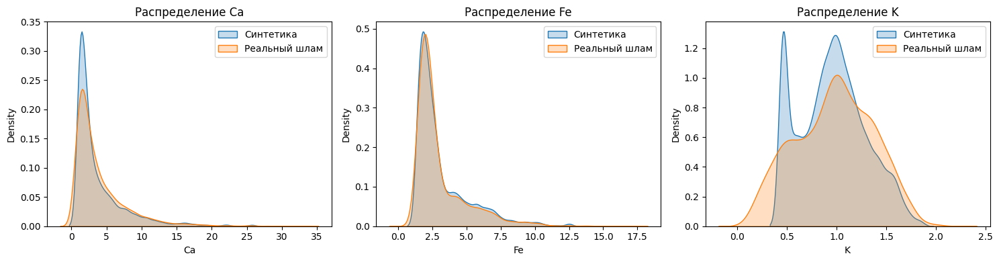

Медианы (Синтетика vs Реальный шлам):
Ca: Синтетика = 2.25, Реальный шлам = 2.60
Fe: Синтетика = 2.35, Реальный шлам = 2.29
K: Синтетика = 0.96, Реальный шлам = 0.99


In [56]:
# Проверяем 3 ключевых элемента
heck_elements = ['Ca', 'Fe', 'K']

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, el in enumerate(check_elements):
    sns.kdeplot(df_synthetic_full[el], ax=axes[i], label='Синтетика', fill=True)
    sns.kdeplot(df_slag[el], ax=axes[i], label='Реальный шлам', fill=True)
    axes[i].set_title(f'Распределение {el}')
    axes[i].legend()
plt.tight_layout()
plt.show()

# Выводим медианы для сравнения
print("Медианы (Синтетика vs Реальный шлам):")
for el in check_elements:
    print(f"{el}: Синтетика = {df_synthetic_full[el].median():.2f}, Реальный шлам = {df_slag[el].median():.2f}")

Строим графики для: ['Zr/Si', 'K/Al', 'Zn/Al', 'S/Ti']


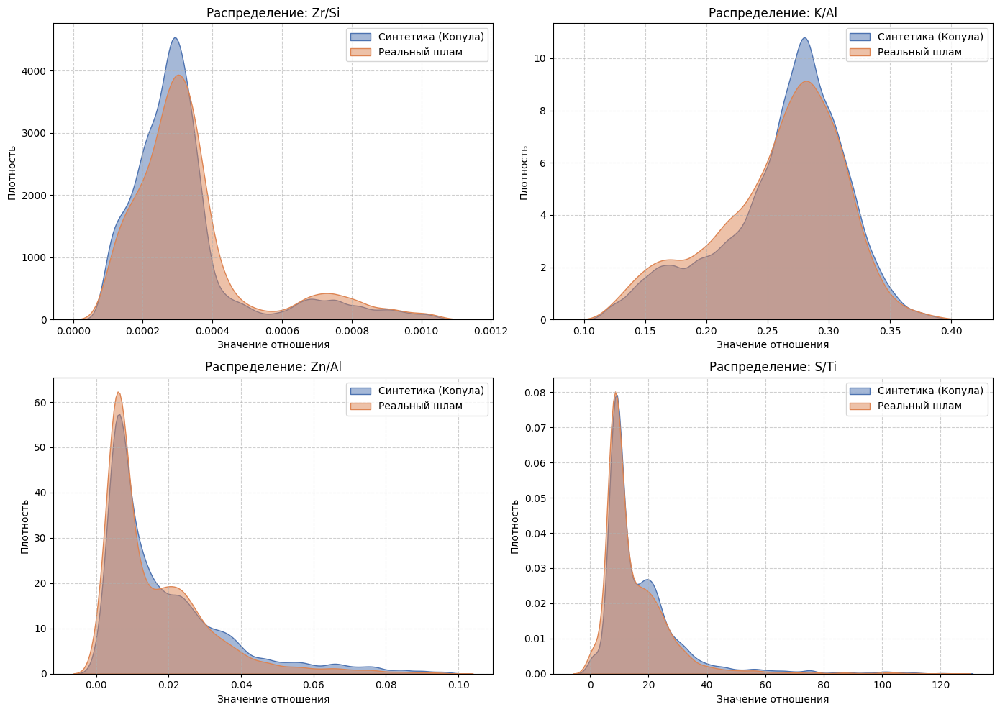


Сравнение медиан соотношений (Синтетика vs Реальный шлам):
Zr/Si: Синтетика = 0.000, Шлам = 0.000 (Разница: -5.2%)
K/Al: Синтетика = 0.274, Шлам = 0.268 (Разница: +2.0%)
Zn/Al: Синтетика = 0.013, Шлам = 0.010 (Разница: +25.2%)
S/Ti: Синтетика = 12.157, Шлам = 10.678 (Разница: +13.9%)


In [57]:
# Выбираем ключевые соотношения для проверки
ratios_to_check = [
    'Ca/Mg',          # Отношение кальция к магнию (карбонатность vs глинистость)
    'Zr/Si',          # Циркон vs кварц
    'K/Al',           # Калий vs алюминий (глинистость)
    'Zn/Al',          # Цинк vs алюминий
    'S/Ti'            # Сера vs титан
]

# Проверяем, какие из них реально есть в датафреймах (названия могут отличаться)
available_ratios = [r for r in ratios_to_check if r in df_synthetic_full.columns and r in df_slag.columns]

if not available_ratios:
    print("ВНИМАНИЕ: Ни одно из выбранных соотношений не найдено. Проверьте названия колонок!")
else:
    print(f"Строим графики для: {available_ratios}")

    n_cols = 2
    n_rows = int(np.ceil(len(available_ratios) / n_cols))
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 5 * n_rows))
    axes = axes.flatten() # Делаем плоский список для удобства
    
    for i, ratio in enumerate(available_ratios):
        ax = axes[i]
        
        # Берем данные, убираем NaN и выбросы для красивой картинки (только для визуализации)
        synth_data = df_synthetic_full[ratio].dropna()
        slag_data = df_slag[ratio].dropna()
        
        # Ограничиваем хвосты (по 1-99 перцентилю), чтобы график не растягивался
        lower = min(synth_data.quantile(0.01), slag_data.quantile(0.01))
        upper = max(synth_data.quantile(0.99), slag_data.quantile(0.99))
        
        synth_data = synth_data[(synth_data >= lower) & (synth_data <= upper)]
        slag_data = slag_data[(slag_data >= lower) & (slag_data <= upper)]
        
        # Строим KDE
        sns.kdeplot(synth_data, ax=ax, label='Синтетика (Копула)', fill=True, color='#4C72B0', alpha=0.5)
        sns.kdeplot(slag_data, ax=ax, label='Реальный шлам', fill=True, color='#DD8452', alpha=0.5)
        
        ax.set_title(f'Распределение: {ratio}', fontsize=12)
        ax.set_xlabel('Значение отношения')
        ax.set_ylabel('Плотность')
        ax.legend()
        ax.grid(linestyle='--', alpha=0.6)

    # Убираем пустые оси, если их больше, чем графиков
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

  
    print("\nСравнение медиан соотношений (Синтетика vs Реальный шлам):")
    for ratio in available_ratios:
        med_syn = df_synthetic_full[ratio].median()
        med_slag = df_slag[ratio].median()
        diff_pct = ((med_syn - med_slag) / med_slag) * 100 if med_slag != 0 else 0
        print(f"{ratio}: Синтетика = {med_syn:.3f}, Шлам = {med_slag:.3f} (Разница: {diff_pct:+.1f}%)")

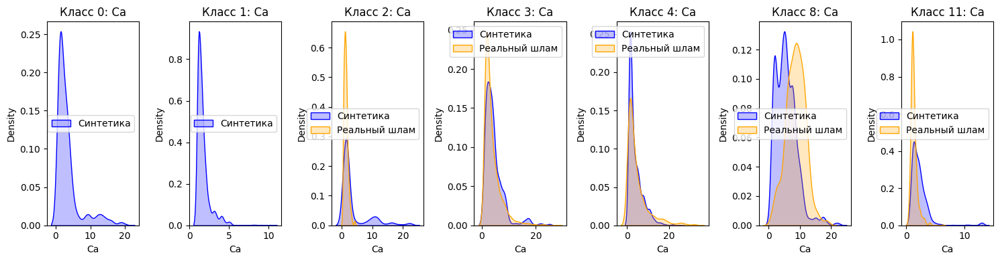

In [58]:
import matplotlib.pyplot as plt
import seaborn as sns

# Берем пару элементов, которые важны для модели (например, Si и Ca)
# и строим распределения для реального шлама и синтетики, РАЗДЕЛЕННЫЕ ПО КЛАССАМ.

# Выбираем 3 класса, которые есть и в керне, и в шламе (например, 4, 8, 11)
classes_to_check = [0, 1, 2, 3, 4, 8, 11] 
el_to_check = 'Ca' # или 'Si', 'Zr', 'S'

fig, axes = plt.subplots(1, len(classes_to_check), figsize=(15, 4))

for i, cls in enumerate(classes_to_check):
    ax = axes[i]
    
    # Данные синтетики для этого класса
    syn_data = df_synthetic_full[df_synthetic_full['Strat'] == cls][el_to_check]
    # Данные реального шлама для этого класса (если метки есть)
    slag_data = df_slag[df_slag['Stratigraphy'] == cls][el_to_check]
    
    sns.kdeplot(syn_data, ax=ax, label='Синтетика', fill=True, color='blue')
    sns.kdeplot(slag_data, ax=ax, label='Реальный шлам', fill=True, color='orange')
    ax.set_title(f'Класс {cls}: {el_to_check}')
    ax.legend()

plt.tight_layout()
plt.show()

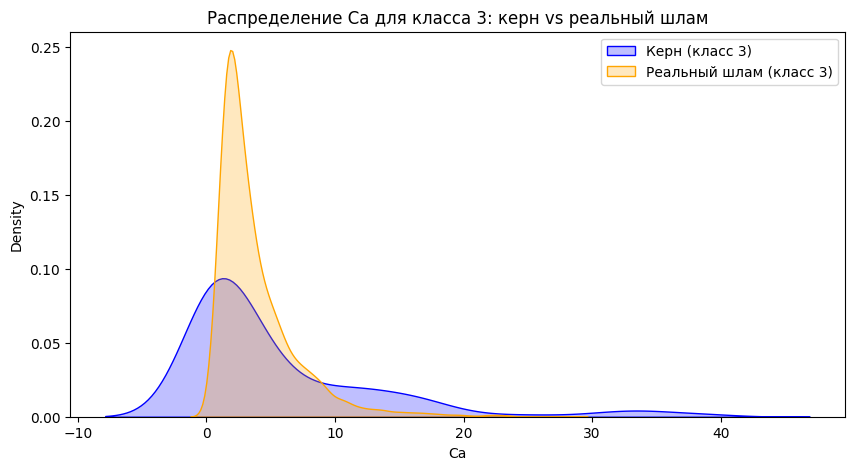

Медиана Ca в керне (класс 3): 2.03
Медиана Ca в шламе (класс 3): 2.79


In [59]:
import matplotlib.pyplot as plt
import seaborn as sns

el = 'Ca'  # или 'Ca/Mg', если есть
cls = 3

# Данные керна для класса 3
kern_data = df_kern[df_kern['Strat'] == cls][el]
# Данные реального шлама для класса 3
slag_data = df_slag[df_slag['Stratigraphy'] == cls][el]  # или 'Strat', если переименовали

plt.figure(figsize=(10, 5))
sns.kdeplot(kern_data, label='Керн (класс 3)', fill=True, color='blue')
sns.kdeplot(slag_data, label='Реальный шлам (класс 3)', fill=True, color='orange')
plt.title(f'Распределение {el} для класса 3: керн vs реальный шлам')
plt.legend()
plt.show()

print(f"Медиана {el} в керне (класс 3): {kern_data.median():.2f}")
print(f"Медиана {el} в шламе (класс 3): {slag_data.median():.2f}")

**Итог. Все ablation study**

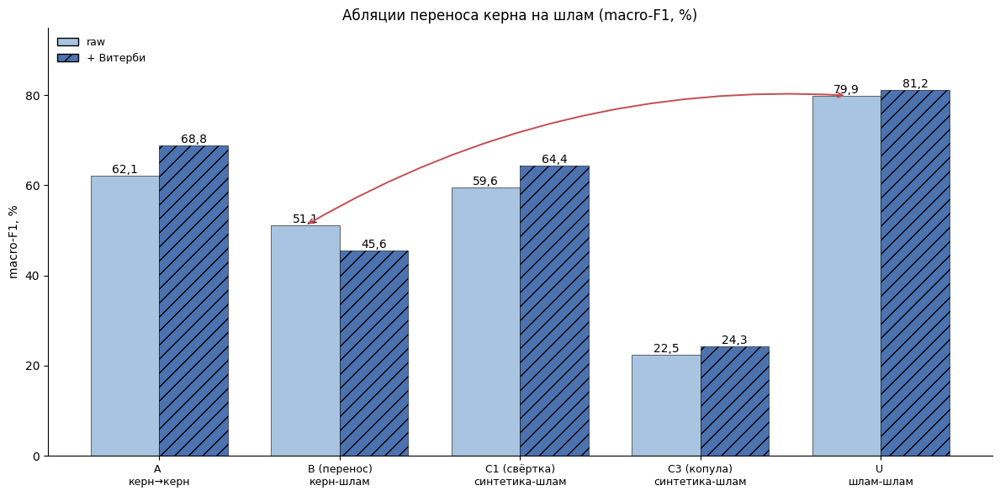

In [6]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.patches as mpatches

# (название, raw %, Витерби %)
configs = [
    ("A \nкерн→керн",      62.1, 68.8),
    ("B (перенос)\nкерн-шлам",               51.1, 45.6),
    ("C1 (свёртка)\nсинтетика-шлам",         59.6, 64.4),
    ("C3 (копула)\nсинтетика-шлам", 22.5, 24.3),
    ("U \nшлам-шлам",            79.9, 81.2),
]

C_RAW, C_VIT = "#A8C4E0", "#4C72B0"

def ru(v):
    return f"{v:.1f}".replace(".", ",")

n = len(configs)
x = np.arange(n)
w = 0.38

fig, ax = plt.subplots(figsize=(12, 6))

for i, (name, raw, vit) in enumerate(configs):
    if raw is not None:
        ax.bar(i - w/2, raw, w, color=C_RAW, edgecolor="black", linewidth=0.4)
        ax.annotate(ru(raw), (i - w/2, raw), ha="center", va="bottom", fontsize=10)
    if vit is not None:
        ax.bar(i + w/2, vit, w, color=C_VIT, edgecolor="black",
               linewidth=0.4, hatch="//")
        ax.annotate(ru(vit), (i + w/2, vit), ha="center", va="bottom", fontsize=10)

# стрелка разрыва B -> U (перенос против оракула)
ax.annotate("", xy=(4 - w/2, 79.9), xytext=(1 - w/2, 51.1),
            arrowprops=dict(arrowstyle="<->", color="#C44E52", lw=1.4,
                            connectionstyle="arc3,rad=-0.15"))



ax.set_xticks(x)
ax.set_xticklabels([c[0] for c in configs], fontsize=9)
ax.set_ylabel("macro-F1, %")
ax.set_ylim(0, 95)
ax.set_title("Абляции переноса керна на шлам (macro-F1, %)", fontsize=12)

handles = [
    mpatches.Patch(facecolor=C_RAW, edgecolor="black", label="raw"),
    mpatches.Patch(facecolor=C_VIT, edgecolor="black", hatch="//", label="+ Витерби"),
]
ax.legend(handles=handles, loc="upper left", frameon=False, fontsize=9)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()


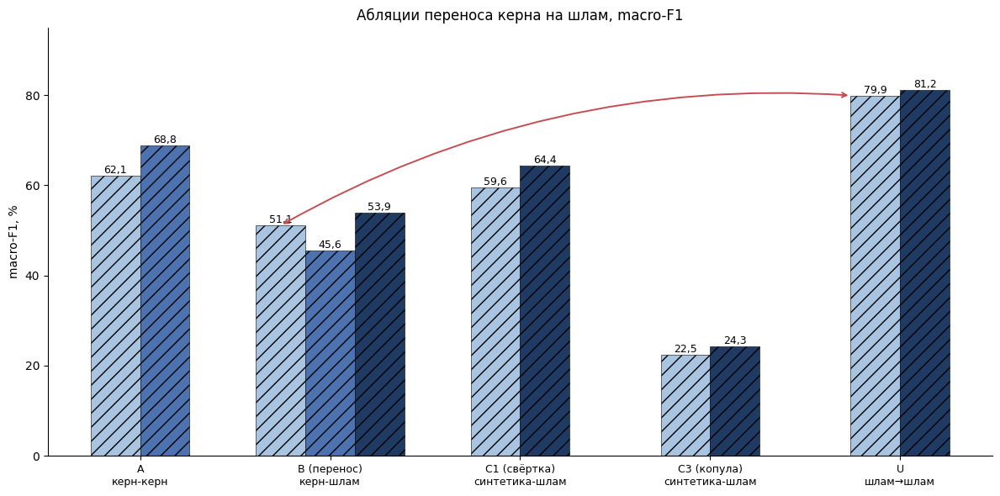

In [62]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.patches as mpatches

C_RAW   = "#A8C4E0"   # raw
C_VKERN = "#4C72B0"   # Витерби, керновая (строгая) матрица
C_VOPT  = "#1F3B63"   # Витерби, оптимизированная матрица

# столбцы: (значение, цвет) в порядке слева направо
configs = [
    ("A\nкерн-керн",
        [(62.1, C_RAW), (68.8, C_VKERN)]),
    ("B (перенос)\nкерн-шлам",
        [(51.1, C_RAW), (45.6, C_VKERN), (53.9, C_VOPT)]),
    ("C1 (свёртка)\nсинтетика-шлам",
        [(59.6, C_RAW), (64.4, C_VOPT)]),
    ("C3 (копула)\nсинтетика-шлам",
        [(22.5, C_RAW), (24.3, C_VOPT)]),
    ("U\nшлам→шлам",
        [(79.9, C_RAW), (81.2, C_VOPT)]),
]

def ru(v):
    return f"{v:.1f}".replace(".", ",")

n = len(configs)
x = np.arange(n)
bw = 0.26   # базовая ширина столбца

fig, ax = plt.subplots(figsize=(12, 6))

for i, (name, bars) in enumerate(configs):
    k = len(bars)
    # центрируем группу: сдвиги от -bw/2 до +bw/2 относительно центра
    offsets = (np.arange(k) - (k - 1) / 2) * bw
    for j, (val, color) in enumerate(bars):
        hatch = "//" if "RAW" not in color.upper() else None
        ax.bar(i + offsets[j], val, bw, color=color,
               edgecolor="black", linewidth=0.4, hatch=hatch)
        ax.annotate(ru(val), (i + offsets[j], val),
                    ha="center", va="bottom", fontsize=9)

# стрелка разрыва B -> U
ax.annotate("", xy=(4 - bw, 79.9), xytext=(1 - bw, 51.1),
            arrowprops=dict(arrowstyle="<->", color="#C44E52", lw=1.4,
                            connectionstyle="arc3,rad=-0.15"))


ax.set_xticks(x)
ax.set_xticklabels([c[0] for c in configs], fontsize=9)
ax.set_ylabel("macro-F1, %")
ax.set_ylim(0, 95)
ax.set_title("Абляции переноса керна на шлам, macro-F1", fontsize=12)

ax.legend(loc="upper left", frameon=False, fontsize=9)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()
